# <center> __Fisher Matrix forecasts__

## Author: Tiago Sinde

---

# Importing python modules

In [1]:
# Science libraries
import numpy as np
import scipy as sc
import scipy.stats as stats
from scipy.special import erf

# Get angular power spectrum for galaxy number counts and lensing
import camb
from camb.sources import SplinedSourceWindow
from camb import model

# Visualizing data
import matplotlib.pyplot as plt
from matplotlib import ticker
from matplotlib.gridspec import GridSpec
from matplotlib.colors import LogNorm
from matplotlib.colors import SymLogNorm 
from matplotlib.colors import LinearSegmentedColormap
from icecream import ic

# Saving and Loading data
import pandas as pd
import pickle 


SMALL_SIZE = 16
MEDIUM_SIZE = 18
BIGGER_SIZE = 20

plt.rc('font',  size      = SMALL_SIZE)        # controls default text sizes
plt.rc('axes',  titlesize = SMALL_SIZE)   # fontsize of the axes title
plt.rc('axes',  labelsize = MEDIUM_SIZE)  # fontsize of the x and y labels
plt.rc('xtick', labelsize = SMALL_SIZE)   # fontsize of the tick labels
plt.rc('ytick', labelsize = SMALL_SIZE)   # fontsize of the tick labels
plt.rc('legend',fontsize  = SMALL_SIZE)    # legend fontsize
plt.rc('figure',titlesize = BIGGER_SIZE)  # fontsize of the figure title


Galaxy_Colors = [ 
                # "#882255",
                "#5A002D", "#CC6677",
                "#332288", "#88CCEE",
                "#117733", "#44AA99",
                ]

HI_Colors = ["#AA4499",
            #   "#D6B71C", 
            #   "#F3CA00", 
            #   "#FFD400",
            "#BB9C00"
              ]


/tmp/ipykernel_88526/4094851097.py:3: UserWarning: A NumPy version >=1.23.5 and <2.3.0 is required for this version of SciPy (detected version 2.3.3)
  import scipy as sc


# **Functions** 

### Importing my own functions

In [2]:
import sys
sys.path.insert(0, "/home/tiagosinde/Documents/Programar/My_Python_functions/")  # add Python_functions path to search list
 
# # Creating and combining Redshift bins 
# from Galaxy_Distribution import Window_func

# # Calculate C_ell
# from Calculate_C_ell_CAMB import C_ells_CAMB

# Fisher Covariance Matrix
from Fisher_Matrix_C_ell_w_theta import  Visualising_F_Matrices


### Window selection functions

In [3]:
def Window_func_Gal_HI(dic_arr_zs, arr_z_central, z0, Ngal, 
                       arr_sigma_val=0.05, arr_bin_width=None, arr_n_gal=np.array([]), 
                       func_pz=None, func_Tz=None, W_func="W_Gauss", dic_Gal_HI_id=None, normalized=True,
                       Show_WS=False, fig_size=(17,5), Fig_y_unit=r"gal \, / \, deg^2", 
                       Name_Survey_Gal="", Name_Survey_HI="", Fig_Ws_name="Default_Ws_name"):
    
    # One Window for each central redshift given.

    dic_Window = {}

    for index_zc, z_c in enumerate(arr_z_central):

        if len(arr_sigma_val)>1:
            sigma_val=arr_sigma_val[index_zc]

        arr_zs = dic_arr_zs[index_zc]

        if index_zc in dic_Gal_HI_id["Gal"]:
            if func_pz != None:
                arr_zs_Total = np.linspace(0,np.max(arr_z_central) + 3*np.max(arr_bin_width), len(arr_zs))
                dNdz = func_pz(arr_zs_Total, z0)*Ngal   # we don't need to normalize this expresion, since CAMB already does it internally
                # dic_Window[ "Total" ] = dNdz
            W_value = Compute_Gal_Surv(W_func, func_pz, dNdz, arr_zs, z0, z_c, sigma_val, 
                                       arr_n_gal, arr_bin_width, index_zc)
        elif index_zc in dic_Gal_HI_id["HI"]:
            W_value = Compute_HI_Surv(W_func, func_Tz, arr_zs, z_c, sigma_val,  
                                      arr_bin_width, index_zc)
        
        if normalized == True:
            normalise_W = sc.integrate.trapezoid( W_value, arr_zs)
        else:
            normalise_W = 1

        dic_Window[ index_zc ] = W_value / normalise_W

    # Visualizing the selcted bins
    if Show_WS == True:
        Visualise_Windows(dic_arr_zs, arr_z_central, dic_Window, dic_Gal_HI_id, 
                         fig_size, Fig_y_unit, 
                         Name_Survey_Gal, Name_Survey_HI, Fig_Ws_name)

    return dic_Window


##################### 
# Base functions
#####################

def W_Gauss(arr_zs, z_c, sigma_zc):
    # sigma_zc = sigma_0 * (1 + z_c)
    return np.exp(- (arr_zs-z_c)**2 / (2*sigma_zc**2))  # we don't need to normalize this expresion, since CAMB already does it internally

def W_erf(z,z_c,bin_width,sigma_zc):
    # sigma_zc = sigma_0 * (1 + z_c)
    return 1/2 * (  erf( (z_c-z+bin_width/2)/(np.sqrt(2)*sigma_zc) )
                  - erf( (z_c-z-bin_width/2)/(np.sqrt(2)*sigma_zc) ) )

def Compute_Gal_Surv(W_func, func_pz, dNdz, 
                     arr_zs, z0, z_c, sigma_val, 
                     arr_n_gal, arr_bin_width, index_zc):

    sigma_zc = sigma_val * (1 + z_c)

    if W_func=="W_Gauss":
        if len(arr_n_gal) > 1:
            Window_zc = func_pz(arr_zs, z0)*arr_n_gal[index_zc] * W_Gauss(arr_zs, z_c, sigma_zc)
        else:
            Window_zc = dNdz * W_Gauss(arr_zs, z_c, sigma_val)

    elif W_func=="W_erf":
        bin_width = arr_bin_width[index_zc]
        if len(arr_n_gal) > 1:
            Window_zc = func_pz(arr_zs, z0)*arr_n_gal[index_zc] * W_erf(arr_zs, z_c, bin_width, sigma_zc)
        else:
            Window_zc = dNdz * W_erf(arr_zs, z_c, bin_width, sigma_zc)

    return Window_zc

def Compute_HI_Surv(W_func, func_Tz, 
                    arr_zs, z_c, sigma_val,  
                    arr_bin_width, index_zc):

    if W_func=="W_Gauss":
        Window_zc = func_Tz(z_c) * W_Gauss(arr_zs, z_c, sigma_val)
    elif W_func=="W_erf":
        bin_width = arr_bin_width[index_zc]
        Window_zc = func_Tz(z_c) * W_erf(arr_zs, z_c, bin_width, sigma_val)

    return Window_zc

def Visualise_Windows(dic_arr_zs, arr_z_central, dic_Window, dic_Gal_HI_id, 
                     fig_size, Fig_y_unit, 
                     Name_Survey_Gal, Name_Survey_HI, Fig_Ws_name):
        fig, axis = plt.subplots(nrows=2, ncols=1, figsize=fig_size)   
        # axis[0].plot(arr_zs, dic_Window[ "Total" ] , "--", lw=2,  c= "k", label="Total gal. dist.")
        
        for index_zc, z_c in enumerate(arr_z_central):
            arr_zs = dic_arr_zs[index_zc]
            if index_zc in dic_Gal_HI_id["Gal"]:
                axis[0].plot(arr_zs, dic_Window[ index_zc ], lw=2.5, label=rF"$W_{{ {index_zc+1} }}: z_c = {z_c :.3f}$")
                axis[0].fill_between( arr_zs, dic_Window[ index_zc ], y2=np.zeros(len( arr_zs )), alpha=0.25 )
            else:
                axis[1].plot(arr_zs, dic_Window[ index_zc ], lw=2.5, label=rF"$W_{{ {index_zc+1} }}: z_c = {z_c :.3f}$")
                axis[1].fill_between( arr_zs, dic_Window[ index_zc ], y2=np.zeros(len( arr_zs )), alpha=0.25 )

        axis[0].set_xlabel('$z$',fontsize=18)
        axis[0].set_ylabel(r"$\frac{dN}{dzd\Omega} \;\;$"+rf"$[{Fig_y_unit}]$",fontsize=18)
        axis[0].set_title(f"Galaxy Survey - {Name_Survey_Gal}")
        axis[0].legend()
        axis[1].set_xlabel('$z$',fontsize=18)
        axis[1].set_ylabel("Temperature",fontsize=18)
        axis[1].set_title(f"HI Survey - {Name_Survey_HI}")
        axis[1].legend()


        if Fig_Ws_name != "Default_Ws_name":
            plt.savefig("Figures/" + Fig_Ws_name + ".png")
        plt.show()

### Calculating $C_\ell$ with CAMB

In [4]:
# Determine Angular Power Spectrum with CAMB
def C_ells_CAMB_HI(dic_arr_zs, dic_Window, l_min, l_max, dic_mag_bias, dic_gal_bias,
                pars_CAMB="default", source_type="counts", N_count_index="D_RSD_L", goal="default",  
                dic_Gal_HI_id=None, s_value=0.01, s_variation=0, Limb_usage=True, Limb_l_min=50):
    
    if pars_CAMB == "default":
        dic_cosmology = default_cosmology()
        pars_CAMB = Cosm_parameters_CAMB(dic_cosmology)

    # Limb_l_min=50 is the Minimum l value used in Limber approx. -- See Section 2. from Fang et. al. 
    pars_CAMB.min_l, pars_CAMB.max_l = l_min, l_max 
    pars_CAMB.Want_CMB, pars_CAMB.Want_CMB_lensing, pars_CAMB.DoLensing = False, False, False
    pars_CAMB.NonLinear = model.NonLinear_none
    pars_CAMB.SourceTerms.counts_velocity        = False
    pars_CAMB.SourceTerms.counts_radial          = False
    pars_CAMB.SourceTerms.counts_timedelay       = False
    pars_CAMB.SourceTerms.counts_ISW             = False
    pars_CAMB.SourceTerms.counts_potential       = False
    pars_CAMB.SourceTerms.counts_evolve          = False
    pars_CAMB.SourceTerms.line_phot_dipole       = False
    pars_CAMB.SourceTerms.line_phot_quadrupole   = False
    pars_CAMB.SourceTerms.line_basic             = False
    pars_CAMB.SourceTerms.line_distortions       = False
    pars_CAMB.SourceTerms.line_extra             = False
    pars_CAMB.SourceTerms.line_reionization      = False
    pars_CAMB.SourceTerms.use_21cm_mK            = False
    pars_CAMB.SourceTerms.limber_windows = Limb_usage
    pars_CAMB.SourceTerms.limber_phi_lmin = Limb_l_min

    pars_CAMB.SourceWindows = Construct_CAMB_Windows(dic_arr_zs, dic_Window, dic_Gal_HI_id, 
                                                     source_type, dic_gal_bias, dic_mag_bias, 
                                                     s_value, s_variation, goal)
    
    if N_count_index == "D_RSD_L":
        pars_CAMB.SourceTerms.counts_density, pars_CAMB.SourceTerms.counts_redshift, pars_CAMB.SourceTerms.counts_lensing = True,  True,  True
    elif N_count_index == "D_RSD":
        pars_CAMB.SourceTerms.counts_density, pars_CAMB.SourceTerms.counts_redshift, pars_CAMB.SourceTerms.counts_lensing = True,  True,  False
    elif N_count_index == "D":
        pars_CAMB.SourceTerms.counts_density, pars_CAMB.SourceTerms.counts_redshift, pars_CAMB.SourceTerms.counts_lensing = True,  False, False
    elif N_count_index == "L":
        pars_CAMB.SourceTerms.counts_density, pars_CAMB.SourceTerms.counts_redshift, pars_CAMB.SourceTerms.counts_lensing = False, False, True
    
    dic_C_ls = camb.get_results(pars_CAMB).get_source_cls_dict(raw_cl=True)
    
    return dic_C_ls


##################### 
# Base functions
#####################

def default_cosmology(dic_Cosm_p=None):
    if dic_Cosm_p != None:
        dic_cosmology = {
            'Omega_M': dic_Cosm_p["Ob"][1] + dic_Cosm_p["Ocdm"][1], 
            'Omega_b': dic_Cosm_p["Ob"][1],
            "Omega_cdm" : dic_Cosm_p["Ocdm"][1],
            'Omega_L': 1-(dic_Cosm_p["Ob"][1] + dic_Cosm_p["Ocdm"][1]),
            "H_0":dic_Cosm_p["H0"][1],  
            'h': dic_Cosm_p["H0"][1]/100,
            'w': dic_Cosm_p["w"][1],
            "A_s": dic_Cosm_p["As"][1] *10**-9,
            'n_s': dic_Cosm_p["ns"][1],
            'sigma_8': 0.8
            }
    else:
        dic_cosmology = {
                'Omega_b': 0.0492,
                "Omega_cdm" : 0.2647,
                'Omega_M': 0.0492 + 0.2647, 
                'Omega_L': 1-(0.0492 + 0.2647),
                "H_0": 67.27,  
                'h': 67.27/100,
                'w': -1,
                "A_s": 2.2065 * 10**-9,
                'n_s': 0.9645,
                'sigma_8': 0.8
                }
    return dic_cosmology

def Cosm_parameters_CAMB(dic_cosmology):
    pars_CAMB = camb.CAMBparams()
    pars_CAMB.set_cosmology(H0=dic_cosmology["H_0"], 
                    ombh2=dic_cosmology["Omega_b"]*dic_cosmology["h"]**2, 
                    omch2=dic_cosmology["Omega_cdm"]*dic_cosmology["h"]**2)
    pars_CAMB.set_dark_energy( w=dic_cosmology["w"] )
    pars_CAMB.InitPower.set_params(As=dic_cosmology["A_s"], ns=dic_cosmology["n_s"])
    
    return pars_CAMB

def Construct_CAMB_Windows(dic_arr_zs, dic_Window, dic_Gal_HI_id, 
                           source_type, dic_gal_bias, dic_mag_bias, s_value,s_variation, goal):
    SSW_list = []
    N_total_bins = len(dic_Gal_HI_id["Gal"]) + len(dic_Gal_HI_id["HI"])
    for index_zc in range(N_total_bins):
        arr_zs = dic_arr_zs[ index_zc ]
        # Galaxy Window function
        if goal == "derive" and index_zc in dic_Gal_HI_id["Gal"]:
            SSW = SplinedSourceWindow(source_type=source_type, bias=dic_gal_bias[index_zc], dlog10Ndm=s_value+s_variation, 
                                      z=arr_zs, W=dic_Window[index_zc])
        elif goal == "default" and index_zc in dic_Gal_HI_id["Gal"]:   
            SSW = SplinedSourceWindow(source_type=source_type, bias=dic_gal_bias[index_zc], dlog10Ndm=dic_mag_bias[index_zc],   
                                      z=arr_zs, W=dic_Window[index_zc])
        elif goal == "default" and index_zc in dic_Gal_HI_id["HI"]:   
            SSW = SplinedSourceWindow(source_type=source_type, bias=dic_gal_bias[index_zc], dlog10Ndm=dic_mag_bias[index_zc], 
                                      z=arr_zs, W=dic_Window[index_zc])
        
        SSW_list.append(SSW)

    return SSW_list


### Calculating Beam

In [5]:
def Beam_ell(z_c, l, Ddish=13.5):
    """ Code from José Fonseca """

    theta_fwhm_mk=theta(z_c,Ddish)
    beam_mk=beam_no_ell(theta_fwhm_mk)

    Beam_ell = (beam_mk)**(l*(l+1))
    return Beam_ell


##################### 
# Base functions
#####################

def lamb(nu, c_light=2.998e5 ):
    ## nu in Hz
    # c_light in Km/sHI=1420
    return c_light*1e3/nu

def nu_obs(z, HI=1420 ):
    # HI in  MHz
    return HI/(1+z)

def theta_fwhm(lamb,D):
    ## lamb in m
    ## D in m
    return 1.22*lamb/D

def theta(zc,D):
    lamb_obs=lamb(nu_obs(zc)*1e6)
    theta_fwhm_val = theta_fwhm(lamb_obs,D)

    return theta_fwhm_val

def beam_no_ell(theta_fwhm):
    ## theta_fwhm in rad
    return np.exp(-theta_fwhm**2/16/np.log(2))


### Fisher Covariance Matrix

In [6]:
# Covariance matrix to be used in Fisher matrix
def Fisher_CovM_HI_Gal(Data_arr_indices, arr_z_c, l_min, l_max, dic_C_ell_CAMB, dic_f_sky, dic_Gal_HI_id,
                       arr_n_gal=None, ell_step=1, N_dishes=None, D_dish=13.5, time_total=None, 
                       arr_bin_width_nu=None, dic_T_sys=None, Temp_HI_func=None, verbose=False): 

    Matrix_indices_z_bins = z_bin_Matrix(Data_arr_indices)
    N_Matrices = Matrix_indices_z_bins.shape[0]
    ells = np.arange(l_min, l_max+1, ell_step)
    N_ells = len( ells )
    
    # Precompute Shot Noise, Beam and temperature factors
    dic_P_N = Calc_Shot_Noise(arr_z_c, dic_Gal_HI_id, dic_f_sky, dic_T_sys, 
                              N_dishes, time_total, arr_bin_width_nu, arr_n_gal)
    
    # Precompute Beam and Temperature
    dic_beam = {}
    dic_temp = {}
    for index_zc, z_c in enumerate(arr_z_c):
        if index_zc in dic_Gal_HI_id["HI"]:
            dic_beam[index_zc] = Beam_ell(z_c, ells, Ddish=D_dish)
            dic_temp[index_zc] = Temp_HI_func(z_c)


    dic_C_ell_CovM = Calc_C_ell_CovM(arr_z_c, dic_C_ell_CAMB, l_min, l_max, ell_step, 
                                     dic_Gal_HI_id, dic_beam, dic_temp)

    ####  Calculate Covariance Matrix
    Multiple_Matrices = np.zeros( (N_Matrices, N_ells, N_ells) )
    for index_M in range( N_Matrices ):
        if (verbose == True) and (index_M % int(N_Matrices/4))==1 and N_Matrices > 20 :
            print(f"Computing small covariance matrix {index_M} of {N_Matrices}")

        arr_index_zc_M = Matrix_indices_z_bins[index_M][0]
        index_z_i = int(arr_index_zc_M[0])
        index_z_j = int(arr_index_zc_M[1])
        index_z_p = int(arr_index_zc_M[2])
        index_z_q = int(arr_index_zc_M[3])

        # Check if any previously calculated matrix has the same z-bin combo as this one
        calculate, index_old_M = Check_previous_zbin_CovM(Matrix_indices_z_bins, index_M, 
                                                          index_z_i, index_z_j, index_z_p, index_z_q )
        if calculate == False:
            Multiple_Matrices[index_M] = Multiple_Matrices[index_old_M]

        elif calculate == True:
            Multiple_Matrices[index_M] = Calc_CovM_C_ell_ijpq(dic_C_ell_CovM, dic_P_N, 
                                                              index_z_i, index_z_j, index_z_p, index_z_q, N_ells)

    if verbose==True:
        print("Cov Matrix Calculated!")
        
    return Multiple_Matrices


##################### 
# Base functions
#####################

def kron_delta(i,j):
    if i == j :
        return 1
    else:
        return 0 

def z_bin_Matrix(Data_arr):
    D = Data_arr
    z_bin_Matrix = np.zeros( (len(D)**2, 1, 4), dtype=np.float64 )
    
    index_M = 0
    for ij in range( len(D) ):
        for pq in range( len(D) ):
            z_i, z_j = D[ij][0], D[ij][1]
            z_p, z_q = D[pq][0], D[pq][1]
            z_bin_Matrix[index_M] = np.array( [z_i, z_j, z_p, z_q] )

            index_M +=1
                
    return z_bin_Matrix 

def Calc_Shot_Noise(arr_z_c, dic_Gal_HI_id, dic_f_sky, dic_T_sys, 
                    N_dishes, time_total, arr_bin_width_nu, arr_n_gal):
    dic_P_N = {}
    count = 0

    for index_zc, z_c in enumerate(arr_z_c):
        # Constructing dictionaty of Shot Noise values
        if index_zc in dic_Gal_HI_id["Gal"]:
            P_N_val = 1/arr_n_gal[index_zc]
            
            dic_P_N[index_zc] = P_N_val


        elif index_zc in dic_Gal_HI_id["HI"]:
            # Find out which is the best bin of T_sys to use
            Closest_z_Tsys = 10**3
            for Key_i in dic_T_sys.keys():
                if np.abs(Key_i-z_c) < np.abs(Closest_z_Tsys-z_c):
                    Closest_z_Tsys = Key_i

            dic_P_N[index_zc] = ( 4*np.pi * dic_f_sky["HI"] * dic_T_sys[Closest_z_Tsys]**2 
                                 / (2*N_dishes * time_total * arr_bin_width_nu[count]) )
            count += 1

    return dic_P_N

def Calc_C_ell_CovM(arr_z_c, dic_C_ell_CAMB, l_min, l_max, ell_step, 
                    dic_Gal_HI_id, dic_beam, dic_temp):
    dic_C_ell_CovM = {} 
    for index_i in range(len(arr_z_c)):
        for index_j in range(len(arr_z_c)):
            Base_C_ell = np.abs(dic_C_ell_CAMB[F"W{index_i +1}xW{index_j +1}"] [l_min:l_max+1 : ell_step]) 

            # Constructing Corrected dictionary of C_ell values     
            if index_i in dic_Gal_HI_id["Gal"]  and  index_j in dic_Gal_HI_id["Gal"]: # Gal_i x Gal_j
                dic_C_ell_CovM[f"{index_i},{index_j}"] = Base_C_ell

            elif index_i in dic_Gal_HI_id["HI"]  and  index_j in dic_Gal_HI_id["Gal"]: # HI_i x Gal_j
                dic_C_ell_CovM[f"{index_i},{index_j}"] = ( Base_C_ell * dic_beam[index_i] * dic_temp[index_i]) 

            elif index_i in dic_Gal_HI_id["Gal"]  and  index_j in dic_Gal_HI_id["HI"]: # Gal_i x HI_j
                dic_C_ell_CovM[f"{index_i},{index_j}"] = ( Base_C_ell * dic_beam[index_j] * dic_temp[index_j]) 

            elif index_i in dic_Gal_HI_id["HI"]  and  index_j in dic_Gal_HI_id["HI"]: # HI_i x HI_j
                dic_C_ell_CovM[f"{index_i},{index_j}"] = ( Base_C_ell * dic_beam[index_i]* dic_beam[index_j] 
                                                      * dic_temp[index_i]* dic_temp[index_j])
    return dic_C_ell_CovM

def Check_previous_zbin_CovM(Matrix_indices_z_bins, index_M, 
                             index_z_i, index_z_j, index_z_p, index_z_q ):
    calculate = True

    for index_old_M in range(index_M-1):
        old_arr_index_zc_M = Matrix_indices_z_bins[index_old_M][0]
        old_index_z_i = old_arr_index_zc_M[0]
        old_index_z_j = old_arr_index_zc_M[1]
        old_index_z_p = old_arr_index_zc_M[2]
        old_index_z_q = old_arr_index_zc_M[3]
        
        # if so, this matrix is equal to that previous matrix        
        if (index_z_i==old_index_z_p and 
            index_z_j==old_index_z_q and 
            index_z_p==old_index_z_i and 
            index_z_q == old_index_z_j) :

            calculate = False
            return calculate, index_old_M   
    
    return calculate, None   

def Calc_CovM_C_ell_ijpq(dic_C_ell_CovM, dic_P_N, 
                         index_z_i, index_z_j, index_z_p, index_z_q, N_ells):
    Cl_iq = dic_C_ell_CovM[f"{index_z_i},{index_z_q}"]  
    Cl_pj = dic_C_ell_CovM[f"{index_z_p},{index_z_j}"]
    Cl_ip = dic_C_ell_CovM[f"{index_z_i},{index_z_p}"]
    Cl_qj = dic_C_ell_CovM[f"{index_z_q},{index_z_j}"]

    P_N_iq = kron_delta(index_z_i, index_z_q) * dic_P_N[index_z_i]                
    P_N_pj = kron_delta(index_z_p, index_z_j) * dic_P_N[index_z_j]
    P_N_ip = kron_delta(index_z_i, index_z_p) * dic_P_N[index_z_i]
    P_N_qj = kron_delta(index_z_q, index_z_j) * dic_P_N[index_z_j]

    # Calculate the Covariance Matrix of a specific redshift combination
    Gamma_ll = np.zeros( (N_ells, N_ells) )
    for index_ell_a in range(N_ells):
        value = (  (Cl_iq[index_ell_a]+P_N_iq) *(Cl_pj[index_ell_a]+P_N_pj) 
                +  (Cl_ip[index_ell_a]+P_N_ip) *(Cl_qj[index_ell_a]+P_N_qj) )
        for index_ell_b in range(index_ell_a, N_ells): 
            Gamma_ll[index_ell_a,index_ell_b] = value
            Gamma_ll[index_ell_b,index_ell_a] = value
    
    return Gamma_ll

### Derivatives of Cosmological/astrophysical parameters

In [7]:
# Derivatives of Fisher matrix
def Fisher_derivative_Gal_HI(Data_arr_indices, arr_z_c, dic_arr_zs, dic_Window, l_min, l_max, 
                         dic_mag_bias, dic_gal_bias, dic_Cosm_p, C_ell_func, 
                         ell_step=1, dic_Gal_HI_id=None, dic_cosmology=None, Temp_HI_func=None, verbose=False):
    
    if dic_cosmology == None:
        dic_cosmology = default_cosmology(dic_Cosm_p=dic_Cosm_p)

    N_Data = len(Data_arr_indices)
    Data_arr_indices = Data_arr_indices.astype(np.int64)
    ells = np.arange(l_min, l_max+1, ell_step)
    N_ells = len(ells)

    pars = Cosm_parameters_CAMB(dic_cosmology) 
    C_ell_Tot   = C_ell_func(dic_arr_zs, dic_Window, l_min, l_max, dic_mag_bias, dic_gal_bias,
                                pars_CAMB=pars, N_count_index="D_RSD_L", dic_Gal_HI_id=dic_Gal_HI_id)
    C_ell_L     = C_ell_func(dic_arr_zs, dic_Window, l_min, l_max, dic_mag_bias, dic_gal_bias,
                                pars_CAMB=pars, N_count_index="L", dic_Gal_HI_id=dic_Gal_HI_id)
    C_ell_D_RSD = C_ell_func(dic_arr_zs, dic_Window, l_min, l_max, dic_mag_bias, dic_gal_bias,
                                pars_CAMB=pars, N_count_index="D_RSD", dic_Gal_HI_id=dic_Gal_HI_id)

    dic_derivatives = {}

    for key in dic_Cosm_p.keys():
        if verbose == True:
            print(f"Computing derivatives: {key}")
    
        Cosm_p_info = dic_Cosm_p[key][0]
        Cosm_p_fid  = dic_Cosm_p[key][1]
        Cosm_p_h_val= dic_Cosm_p[key][2]

        if Cosm_p_info == "curv_amp":
            arr_dCl_dalpha = Analytic_derive_As(Data_arr_indices, N_Data, dic_Gal_HI_id, arr_z_c, Cosm_p_fid,
                                                C_ell_Tot, l_min, l_max, ell_step, ells, N_ells, Temp_HI_func)

        elif Cosm_p_info == "beta" :    
            arr_dCl_dalpha = Analytic_derive_beta(Data_arr_indices, N_Data, dic_Gal_HI_id, C_ell_Tot, C_ell_L, C_ell_D_RSD, 
                                                  l_min, l_max, ell_step, N_ells)

        elif Cosm_p_info == "mag_bias":  
            arr_dCl_dalpha = Five_pt_sten_mag_bias(Cosm_p_fid, Cosm_p_h_val, dic_cosmology, 
                                                    C_ell_func, dic_arr_zs, dic_Window, l_min, l_max, ell_step, 
                                                    dic_mag_bias, dic_gal_bias, dic_Gal_HI_id, N_ells, ells, Temp_HI_func,
                                                    Data_arr_indices, N_Data, arr_z_c)

        else:
            arr_dCl_dalpha = Five_pt_sten_CosmP(Cosm_p_info, Cosm_p_fid, Cosm_p_h_val, dic_cosmology, 
                                                C_ell_func, dic_arr_zs, dic_Window, l_min, l_max, ell_step, 
                                                dic_mag_bias, dic_gal_bias, dic_Gal_HI_id, N_ells, ells, Temp_HI_func,
                                                Data_arr_indices, N_Data, arr_z_c)
            
        dic_derivatives[key] = arr_dCl_dalpha

    if verbose == True: 
        print("Derivatives Calculated!")

    return dic_derivatives


##################### 
# Base functions
#####################

def Check_zbin_HI(index_z_i, index_z_j, dic_Gal_HI_id):
    # Check if z-bin is of type HI
    z_i_HI, z_j_HI = False, False 
    if index_z_i in dic_Gal_HI_id["HI"]: 
        z_i_HI = True
    if index_z_j in dic_Gal_HI_id["HI"]: 
        z_j_HI = True
    return z_i_HI, z_j_HI

# Define cosmology while derivating
def set_cosmology_param(val, Cosm_p_info, dic_cosmology, pars):
    if Cosm_p_info == "hubble_const":
        New_h = val / 100
        pars.set_cosmology(H0=val, 
                            ombh2=dic_cosmology["Omega_b"]*New_h**2, 
                            omch2=dic_cosmology["Omega_cdm"]*New_h**2)
    elif Cosm_p_info == "w":
        pars.set_dark_energy(w=val)
    elif Cosm_p_info == "omega_baryon":
        New_Omega_cdm = dic_cosmology["Omega_M"] - val
        pars.set_cosmology(H0=dic_cosmology["H_0"], 
                            ombh2=val*dic_cosmology["h"]**2, 
                            omch2=New_Omega_cdm*dic_cosmology["h"]**2)
    elif Cosm_p_info == "omega_cdm":
        pars.set_cosmology(H0=dic_cosmology["H_0"], 
                            ombh2=dic_cosmology["Omega_b"]*dic_cosmology["h"]**2, 
                            omch2=val*dic_cosmology["h"]**2)
    elif Cosm_p_info == "spec_index":
        pars.InitPower.set_params(As=dic_cosmology["A_s"], ns=val)

    return pars

def Obs_C_ell_HI(z_i_HI, z_j_HI, dCl_dalpha, z_c_i, z_c_j, ells, Temp_HI_func):
    if z_i_HI==True and z_j_HI==True:
        dCl_dalpha_corrected = ( dCl_dalpha * Beam_ell(z_c_i, ells) * Beam_ell(z_c_j, ells) 
                                * Temp_HI_func(z_c_i)* Temp_HI_func(z_c_j) )
    elif z_i_HI==True and z_j_HI==False:
        dCl_dalpha_corrected = (  dCl_dalpha * Beam_ell(z_c_i, ells) * Temp_HI_func(z_c_i))
    elif z_i_HI==False and z_j_HI==True:
        dCl_dalpha_corrected = (  dCl_dalpha * Beam_ell(z_c_j, ells) * Temp_HI_func(z_c_j))
    else:
        dCl_dalpha_corrected = dCl_dalpha

    return dCl_dalpha_corrected


# Compute derivatives for each parameter
def Analytic_derive_As(Data_arr_indices, N_Data, dic_Gal_HI_id, arr_z_c, Cosm_p_fid,
                       C_ell_Tot, l_min, l_max, ell_step, ells, N_ells, Temp_HI_func):
    arr_dCl_dalpha = np.zeros( N_Data * N_ells)

    for index_bin, (index_z_i, index_z_j) in enumerate(Data_arr_indices): 

        W_bin_comb = f"W{index_z_i+1}xW{index_z_j+1}"

        # Check if z-bin is of type HI
        z_i_HI_bool, z_j_HI_bool = Check_zbin_HI(index_z_i, index_z_j, dic_Gal_HI_id) 
        # Correcting observed C_ell^HI values
        z_c_i = arr_z_c[index_z_i]
        z_c_j = arr_z_c[index_z_j]
        
        dCl_dalpha = np.abs( C_ell_Tot[ W_bin_comb ][l_min:l_max+1 : ell_step]) / Cosm_p_fid
        dCl_dalpha_corrected = Obs_C_ell_HI(z_i_HI_bool, z_j_HI_bool, dCl_dalpha, z_c_i, z_c_j, ells, Temp_HI_func)
        arr_dCl_dalpha[N_ells*index_bin : N_ells*(1+index_bin)] = dCl_dalpha_corrected

    return arr_dCl_dalpha

def Analytic_derive_beta(Data_arr_indices, N_Data, dic_Gal_HI_id, C_ell_Tot, C_ell_L, C_ell_D_RSD, 
                         l_min, l_max, ell_step, N_ells):
    arr_dCl_dalpha = np.zeros( N_Data * N_ells)
    
    for index_bin, (index_z_i, index_z_j) in enumerate(Data_arr_indices): 
        # Check if z-bin is of type HI
        z_i_HI_bool, z_j_HI_bool = Check_zbin_HI(index_z_i, index_z_j, dic_Gal_HI_id) 

        if (z_i_HI_bool== False) or (z_j_HI_bool== False):
            W_bin_comb = f"W{index_z_i+1}xW{index_z_j+1}"
            dCl_dalpha = (  np.abs(C_ell_Tot[ W_bin_comb ][l_min:l_max+1 : ell_step]) 
                        + np.abs(C_ell_L    [ W_bin_comb ][l_min:l_max+1 : ell_step]) 
                        - np.abs(C_ell_D_RSD[ W_bin_comb ][l_min:l_max+1 : ell_step]) )
        else:
            dCl_dalpha = np.zeros( N_ells )
            
        arr_dCl_dalpha[N_ells*index_bin : N_ells*(1+index_bin)] = dCl_dalpha

    return arr_dCl_dalpha

def Five_pt_sten_mag_bias(Cosm_p_fid, Cosm_p_h_val, dic_cosmology, 
                          C_ell_func, dic_arr_zs, dic_Window, l_min, l_max, ell_step, 
                          dic_mag_bias, dic_gal_bias, dic_Gal_HI_id, N_ells, ells, Temp_HI_func,
                          Data_arr_indices, N_Data, arr_z_c):
    arr_dCl_dalpha = np.zeros( N_Data * N_ells)
    dic_C_ells_fps = {}
    variations = [2*Cosm_p_h_val, Cosm_p_h_val, -Cosm_p_h_val, -2*Cosm_p_h_val]

    pars = Cosm_parameters_CAMB(dic_cosmology) 
    for index_var, var in enumerate(variations):            
        dic_C_ells_fps[index_var+1] = C_ell_func(dic_arr_zs, dic_Window, l_min, l_max, 
                                                    dic_mag_bias, dic_gal_bias, pars_CAMB=pars, 
                                                    goal="derive", dic_Gal_HI_id=dic_Gal_HI_id, 
                                                    s_value=Cosm_p_fid, s_variation=var)
        
    for index_bin, (index_z_i, index_z_j) in enumerate(Data_arr_indices): 

        # Check if z-bin is of type HI
        z_i_HI_bool, z_j_HI_bool = Check_zbin_HI(index_z_i, index_z_j, dic_Gal_HI_id) 

        # if both s parameters differ from the value that we are derivating in order of,  then derivatives are null
        s_i, s_j = dic_mag_bias[index_z_i], dic_mag_bias[index_z_j]
        Correct_bins_boolean = (Cosm_p_fid==s_i or Cosm_p_fid==s_j)

        if Correct_bins_boolean == False:
            dCl_dalpha_corrected = np.zeros( N_ells )

        # elif Correct_bins_boolean == True and ( (z_i_HI_bool== False) or (z_j_HI_bool== False) ): # if at least one of the bins is from Galaxies
        elif Correct_bins_boolean == True: 
            W_bin_comb = f"W{index_z_i+1}xW{index_z_j+1}"
            dCl_dalpha = Five_pt_sten_C_ell(dic_C_ells_fps, W_bin_comb, l_min, l_max, ell_step, Cosm_p_h_val)

            # Correcting observed C_ell^HI values
            z_c_i = arr_z_c[index_z_i]
            z_c_j = arr_z_c[index_z_j]
            dCl_dalpha_corrected = Obs_C_ell_HI(z_i_HI_bool, z_j_HI_bool, dCl_dalpha, z_c_i, z_c_j, ells, Temp_HI_func)
        
        arr_dCl_dalpha[N_ells*index_bin : N_ells*(1+index_bin)] = dCl_dalpha_corrected

    return arr_dCl_dalpha

def Five_pt_sten_CosmP(Cosm_p_info, Cosm_p_fid, Cosm_p_h_val, dic_cosmology, 
                          C_ell_func, dic_arr_zs, dic_Window, l_min, l_max, ell_step, 
                          dic_mag_bias, dic_gal_bias, dic_Gal_HI_id, N_ells, ells, Temp_HI_func,
                          Data_arr_indices, N_Data, arr_z_c):
    arr_dCl_dalpha = np.zeros( N_Data * N_ells)
    dic_C_ells_fps = {}
    variations = [2*Cosm_p_h_val, Cosm_p_h_val, -Cosm_p_h_val, -2*Cosm_p_h_val]

    for index_var, var in enumerate(variations):            
        pars = Cosm_parameters_CAMB(dic_cosmology) 

        pars = set_cosmology_param(Cosm_p_fid + var, Cosm_p_info, dic_cosmology, pars)
        dic_C_ells_fps[index_var+1] = C_ell_func(dic_arr_zs, dic_Window, 
                                        l_min, l_max, dic_mag_bias, dic_gal_bias,
                                        pars_CAMB=pars, dic_Gal_HI_id=dic_Gal_HI_id)

    for index_bin, (index_z_i, index_z_j) in enumerate(Data_arr_indices): 

        W_bin_comb = f"W{index_z_i+1}xW{index_z_j+1}"
        dCl_dalpha = Five_pt_sten_C_ell(dic_C_ells_fps, W_bin_comb, l_min, l_max, ell_step, Cosm_p_h_val)

        # Check if z-bin is of type HI
        z_i_HI_bool, z_j_HI_bool = Check_zbin_HI(index_z_i, index_z_j, dic_Gal_HI_id) 
        # Correcting observed C_ell^HI values
        z_c_i = arr_z_c[index_z_i]
        z_c_j = arr_z_c[index_z_j]
        dCl_dalpha_corrected = Obs_C_ell_HI(z_i_HI_bool, z_j_HI_bool, dCl_dalpha, z_c_i, z_c_j, ells, Temp_HI_func)
        
        arr_dCl_dalpha[N_ells*index_bin : N_ells*(1+index_bin)] = dCl_dalpha_corrected
    
    return arr_dCl_dalpha


def Five_pt_sten_C_ell(dic_C_ells_fps, W_bin_comb, l_min, l_max, ell_step, Cosm_p_h_val):
    C_ell_var1 = np.abs(dic_C_ells_fps[1][W_bin_comb][l_min:l_max+1 : ell_step])
    C_ell_var2 = np.abs(dic_C_ells_fps[2][W_bin_comb][l_min:l_max+1 : ell_step])
    C_ell_var3 = np.abs(dic_C_ells_fps[3][W_bin_comb][l_min:l_max+1 : ell_step])
    C_ell_var4 = np.abs(dic_C_ells_fps[4][W_bin_comb][l_min:l_max+1 : ell_step])
    dCl_dalpha = ( -C_ell_var1 + 8*C_ell_var2 - 8*C_ell_var3 + C_ell_var4 ) / (12*Cosm_p_h_val)

    return dCl_dalpha

### Calculating Fisher Matrix $C_\ell$

In [8]:
def Fisher_Matrix_Cl_better(Data_arr_indices, dic_Cosm_param, Cov_Matrix, dic_derivatives, 
                            full_l_min, l_min, full_l_max, l_max, dic_f_sky, dic_Gal_HI_id=None,
                            ell_step=1, list_CosmP_log=[], verbose=False):
    if verbose==True:
        print("Builing diagonal Matrix")

    Matrix_indices_z_bins = z_bin_Matrix(Data_arr_indices)
    N_Matrices = Matrix_indices_z_bins.shape[0]
    N_data = len(Data_arr_indices) 

    ells_full = np.arange(full_l_min, full_l_max+1, ell_step)
    ells_cut = np.arange(l_min, l_max+1, ell_step)
    N_ells_full = len( ells_full )
    N_ells_cut = len( ells_cut )
    
    delta_l_min = np.abs(l_min-full_l_min)
    delta_l_max = np.abs(full_l_max-l_max)

    Big_Matrix = CovM_C_ell(N_Matrices, N_ells_cut, Cov_Matrix, Matrix_indices_z_bins, dic_Gal_HI_id, dic_f_sky, 
                            ell_step, ells_cut, delta_l_min, l_max, delta_l_max)

    Big_M_Block_Diag_inv = Construct_Block_diag_and_invert(N_data, N_ells_cut, Big_Matrix)

    ################################################## Calculating Fisher Matrix
    Name_Cosm_param = list(dic_Cosm_param.keys())
    N_cosm_p = len(Name_Cosm_param)
    Cosm_p_M = Cosm_p_Matrix(Name_Cosm_param)

    Fisher_m_ab = np.zeros( N_cosm_p**2 )
    for index_cosm in range(N_cosm_p**2): 
        if verbose==True and (index_cosm % int(N_cosm_p**2/5))==1:
            print(f"Computing Fisher matrix entry {index_cosm} of {N_cosm_p**2}")
        
        Name_CosmP_a = Cosm_p_M[index_cosm][0]
        Name_CosmP_b = Cosm_p_M[index_cosm][1]
        
        derivatives_values_a = dic_derivatives[ Name_CosmP_a ]
        derivatives_values_b = dic_derivatives[ Name_CosmP_b ]
        
        # derivative of ln of parameter
        derivatives_values_a_upated = dX_dlambda_to_dX_dloglambda(Name_CosmP_a, list_CosmP_log, dic_Cosm_param, derivatives_values_a)
        derivatives_values_b_upated = dX_dlambda_to_dX_dloglambda(Name_CosmP_b, list_CosmP_log, dic_Cosm_param, derivatives_values_b)
        
        dXdlambda_a_reorganize, dXdlambda_b_reorganize = Organize_arr_Derivative(N_data, N_ells_cut, N_ells_full, delta_l_min, delta_l_max, 
                                                                                 derivatives_values_a_upated, derivatives_values_b_upated)

        #### Calculating one Fisher Matrix component        
        dXdlambda_a_reorganize_reshape = np.reshape( dXdlambda_a_reorganize, (N_data*N_ells_cut, 1) ) 
        Inv_dXdlambda_a        = np.reshape( dXdlambda_a_reorganize_reshape, (1, N_data*N_ells_cut ) )

        dXdlambda_b_reorganize_reshape = np.reshape( dXdlambda_b_reorganize, (N_data*N_ells_cut, 1) ) 


        Fisher_value = Inv_dXdlambda_a @ Big_M_Block_Diag_inv @ dXdlambda_b_reorganize_reshape
        Fisher_m_ab[index_cosm] = Fisher_value.item()
            
    
    Fisher_M = np.reshape(Fisher_m_ab, (N_cosm_p, N_cosm_p))
    
    return Fisher_M


##################### 
# Base functions
#####################

def Cosm_p_Matrix(Cosm_p_list):
    C = Cosm_p_list
    Cosm_Matrix = np.zeros( (len(C)**2, 2), dtype=object )
    
    index_M = 0
    for a in range( len(C) ):
        for b in range( len(C) ):
            Cosm_Matrix[index_M] = np.array( [C[a], C[b]] )
            index_M +=1

    return Cosm_Matrix 

def Select_f_sky_value(Matrix_indices_z_bins, index_M, dic_Gal_HI_id, dic_f_sky):
    ### Assign correct f_sky value
    # arr_index_zc_M = Matrix_indices_z_bins[index_M][0]
    # index_z_i = int(arr_index_zc_M[0])
    # index_z_j = int(arr_index_zc_M[1])
    # index_z_p = int(arr_index_zc_M[2])
    # index_z_q = int(arr_index_zc_M[3])
    # if ( (   index_z_i in dic_Gal_HI_id["Gal"]) 
    #     and (index_z_j in dic_Gal_HI_id["Gal"]) 
    #     and (index_z_p in dic_Gal_HI_id["Gal"])
    #     and (index_z_q in dic_Gal_HI_id["Gal"])):
    #     f_sky = dic_f_sky["Gal"]
        
    # elif ( ( index_z_i in dic_Gal_HI_id["HI"]) 
    #     and (index_z_j in dic_Gal_HI_id["HI"]) 
    #     and (index_z_p in dic_Gal_HI_id["HI"])
    #     and (index_z_q in dic_Gal_HI_id["HI"])):
    #     f_sky = dic_f_sky["HI"]
    # else:
    #     f_sky = np.min( np.array([ dic_f_sky["Gal"], dic_f_sky["HI"] ]) )

    
    f_sky = np.min( np.array([ dic_f_sky["Gal"], dic_f_sky["HI"] ]) )
    

    return f_sky


def CovM_C_ell(N_Matrices, N_ells_cut, Cov_Matrix, Matrix_indices_z_bins, dic_Gal_HI_id, dic_f_sky, 
               ell_step, ells_cut, delta_l_min, l_max, delta_l_max):
    Big_Matrix = np.zeros( (N_Matrices, N_ells_cut, N_ells_cut), dtype=np.float64 )    
    # Assign diagonals in-place to Big_Matrix
    for index_M in range(N_Matrices):
        CovM_diagonals = np.diagonal(Cov_Matrix[index_M])
        f_sky = Select_f_sky_value(Matrix_indices_z_bins, index_M, dic_Gal_HI_id, dic_f_sky)

        Cl_CovM_diagonals = 1/(f_sky*ell_step) * 1/(2*ells_cut + 1) * CovM_diagonals[delta_l_min : (l_max-delta_l_max)]
        np.fill_diagonal(Big_Matrix[index_M], Cl_CovM_diagonals)
    
    return Big_Matrix


def Construct_Block_diag_and_invert(N_data, N_ells_cut, Big_Matrix):
    Big_M_Block_Diag_inv = np.zeros( (N_data* N_ells_cut, N_data*N_ells_cut), dtype=np.float64 ) 
    for index_ell in range(N_ells_cut):

        count=0
        Small_Matrix = np.zeros( (N_data, N_data), dtype=np.float64 )    
        for index_Data_i in range(N_data):
            for index_Data_j in range(N_data):
                Small_Matrix[index_Data_i,index_Data_j] = Big_Matrix[count][index_ell,index_ell]
                count+=1
        
        # Inverse of a Block diagonal is the inverse of each block
        Big_M_Block_Diag_inv[index_ell*(N_data): (index_ell+1)*(N_data), 
                             index_ell*(N_data): (index_ell+1)*(N_data)] = np.linalg.inv(Small_Matrix)
        
    return Big_M_Block_Diag_inv

def dX_dlambda_to_dX_dloglambda(Name_CosmP, list_CosmP_log, dic_Cosm_param, derivatives_values):
    if Name_CosmP in list_CosmP_log:
        Value_CosmP = dic_Cosm_param[Name_CosmP][1]
        derivatives_values_upated = derivatives_values * np.abs(Value_CosmP)
    else:
        derivatives_values_upated = derivatives_values
    return derivatives_values_upated

def Organize_arr_Derivative(N_data, N_ells_cut, N_ells_full, delta_l_min, delta_l_max, 
                            derivatives_values_a, derivatives_values_b):
    dXdlambda_a = np.zeros(N_data*N_ells_cut)
    dXdlambda_b = np.zeros(N_data*N_ells_cut)
    for index_data in range(N_data):
        start_step =  index_data   *N_ells_cut
        end_step   = (index_data+1)*N_ells_cut
        deriv_start_step =  index_data   *N_ells_full
        deriv_end_step   = (index_data+1)*N_ells_full

        dXdlambda_a[start_step : end_step] = derivatives_values_a[deriv_start_step +delta_l_min : deriv_end_step -delta_l_max]
        dXdlambda_b[start_step : end_step] = derivatives_values_b[deriv_start_step +delta_l_min : deriv_end_step -delta_l_max]
    

    dXdlambda_a_reorganize = np.zeros(N_data*N_ells_cut)
    dXdlambda_b_reorganize = np.zeros(N_data*N_ells_cut)
    count=0
    for index_ell in range(N_ells_cut):
        for index_data in range(N_data):
            dXdlambda_a_reorganize[count] = dXdlambda_a[index_ell+(index_data*N_ells_cut)]
            dXdlambda_b_reorganize[count] = dXdlambda_b[index_ell+(index_data*N_ells_cut)]
            count+=1

    return dXdlambda_a_reorganize, dXdlambda_b_reorganize

### Calculating Fihser Matrix $w(\theta)$

In [9]:
def Fisher_Matrix_w(Data_arr_indices, arr_ells, arr_thetas, Pol_Legend, 
                    dic_Cosm_param, Cov_Matrix, dic_derivatives, dic_f_sky,
                    dic_Gal_HI_id=None, list_CosmP_log=[], verbose=False):
    
    ############################# Calculating Covariant Matrix    
    Matrix_indices_z_bins = z_bin_Matrix(Data_arr_indices)
    N_Matrices = Matrix_indices_z_bins.shape[0]
    N_data = len(Data_arr_indices) 
    N_thetas = len(arr_thetas)
    
    # Discretization correction
    delta_theta = np.abs(arr_thetas[1] - arr_thetas[0])
    scale_factor =  delta_theta / arr_thetas.min()
    ic(delta_theta , arr_thetas.min(),scale_factor)
    wt_Cov_diagonals = 1/(scale_factor * (4*np.pi)**2) * np.diagonal(Cov_Matrix, axis1=1, axis2=2)  
    
    # # Adjust value of the Covariance Matrix of a specific redshift combination
    Multiple_Matrices = CovM_w_theta(N_Matrices, N_thetas, Matrix_indices_z_bins, 
                                     dic_Gal_HI_id, dic_f_sky, 
                                     Pol_Legend, arr_ells, wt_Cov_diagonals, verbose)
    
    Big_Matrix = np.reshape(Multiple_Matrices, (N_data, N_data, N_thetas, N_thetas))
    Big_Matrix = np.transpose(Big_Matrix, (0,2,1,3))
    Big_Matrix = np.reshape(Big_Matrix, (N_data*N_thetas, N_data*N_thetas))
    
    # ic(Big_Matrix.shape)
    
    Big_Matrix_inv = np.linalg.inv(Big_Matrix)
    ic(np.sum( Big_Matrix @ Big_Matrix_inv ), N_data*N_thetas)
    
    ################################################### Calculating derivatives
    Name_Cosm_param = list(dic_Cosm_param.keys())
    N_cosm_p = len(Name_Cosm_param)
    Cosm_p_M = Cosm_p_Matrix(Name_Cosm_param)
    
    if verbose==True:
        print("Computing derivatives")

    dic_dw_dalpha =  Dic_derivatives_w_theta(Name_Cosm_param, N_data, N_thetas, 
                                             arr_ells, Pol_Legend, dic_derivatives )
    
    ################################################## Calculating Fisher Matrix
    Fisher_m_ab = np.zeros( N_cosm_p**2 )
    for index_cosm in range(N_cosm_p**2):  
        
        Name_CosmP_a = Cosm_p_M[index_cosm][0]
        Name_CosmP_b = Cosm_p_M[index_cosm][1]

        dwds_a = dic_dw_dalpha[ Name_CosmP_a ]
        dwds_b = dic_dw_dalpha[ Name_CosmP_b ]

        # derivative of ln of parameter
        dwds_a_upated = dX_dlambda_to_dX_dloglambda(Name_CosmP_a, list_CosmP_log, dic_Cosm_param, dwds_a)
        dwds_b_upated = dX_dlambda_to_dX_dloglambda(Name_CosmP_b, list_CosmP_log, dic_Cosm_param, dwds_b)

        ### Calculating one Fisher Matrix component
        dwds_a_reshape = np.reshape( dwds_a_upated, (N_data * N_thetas, 1) ) 
        Inv_dwds_a     = np.reshape( dwds_a_reshape,(1, N_data * N_thetas) )
        dwds_b_reshape = np.reshape( dwds_b_upated, (N_data * N_thetas, 1) ) 
        
        Fisher_value = Inv_dwds_a @ Big_Matrix_inv @ dwds_b_reshape
        Fisher_m_ab[index_cosm] = Fisher_value.item()
    
    Fisher_M = np.reshape(Fisher_m_ab, (N_cosm_p, N_cosm_p))
    
    if verbose==True:
        print("Fisher Matrix calculated!")
    
    return Fisher_M


##################### 
# Base functions
#####################

def CovM_w_theta(N_Matrices, N_thetas, Matrix_indices_z_bins, dic_Gal_HI_id, dic_f_sky, 
                 Pol_Legend, arr_ells, wt_Cov_diagonals, verbose):

    # Adjust value of the Covariance Matrix of a specific redshift combination
    Multiple_Matrices = np.zeros( (N_Matrices, N_thetas, N_thetas) )
    for index_M in range( N_Matrices ):
        if (verbose == True) and (index_M % int(N_Matrices/5)) == 1 and N_Matrices > 20:
            print(f"Computing small covariance matrix {index_M} of {N_Matrices}")

        # Assign correct f_sky value
        f_sky = Select_f_sky_value(Matrix_indices_z_bins, index_M, dic_Gal_HI_id, dic_f_sky)

        Gamma_tt = np.zeros( (N_thetas, N_thetas) )

        for index_teta_a in range(N_thetas):
            arr_P_l_a = Pol_Legend[index_teta_a , :]
            
            for index_teta_b in range(index_teta_a, N_thetas):
                arr_P_l_b = Pol_Legend[index_teta_b , : ]

                w_theta_val = np.sum( (2*arr_ells+1)/f_sky  * arr_P_l_a *arr_P_l_b * wt_Cov_diagonals[index_M], axis=0 )

                Gamma_tt[index_teta_a,index_teta_b] = w_theta_val
                Gamma_tt[index_teta_b,index_teta_a] = w_theta_val
                
        Multiple_Matrices[index_M] = Gamma_tt 
    
    return Multiple_Matrices

def Dic_derivatives_w_theta(Name_Cosm_param, N_data, N_thetas, 
                            arr_ells, Pol_Legend, dic_derivatives ):
    dic_dw_dalpha = {}
    for cosm_key in Name_Cosm_param:  
        dw_dalpha = np.empty( N_data * N_thetas )
        for index_z_bin in range(N_data):
            for index_teta in range( N_thetas):
                value_sum = np.sum( (2*arr_ells+1) * Pol_Legend[index_teta, : ] 
                                   * dic_derivatives[cosm_key][index_z_bin*len(arr_ells) : (index_z_bin + 1)*len(arr_ells) ] )
                dw_dalpha[index_teta + index_z_bin*N_thetas] = value_sum
        dic_dw_dalpha[cosm_key] = 1/(4*np.pi) * dw_dalpha

    return dic_dw_dalpha


### Visualising Cov Matrix and derivatives

In [10]:
def Visualizing_Cov_Matrix_Gal_HI(Data_arr_zs, l_min, l_max, l_step, Cov_Matrix, fig_size=(8,6), color_map="viridis"):
    
    N_data = len(Data_arr_zs)
    ells_cut = np.arange(l_min, l_max+1, l_step)
    N_ells = len(ells_cut)
    ic(N_ells)
    ic(Cov_Matrix.shape)
    
    Cov_Matrix_vis = np.reshape(Cov_Matrix, (N_data, N_data, N_ells, N_ells))
    Cov_Matrix_vis = np.transpose(Cov_Matrix_vis, (0,2,1,3))
    Cov_Matrix_vis = np.reshape(Cov_Matrix_vis, (N_data*N_ells, N_data*N_ells))

    fig, ax = plt.subplots(ncols=1 ,nrows=1,figsize=fig_size)
    ax.set_title("Covariance Matrix")
    v_min, v_max = Cov_Matrix_vis.min(), Cov_Matrix_vis.max()

    im=ax.imshow(Cov_Matrix_vis, cmap=color_map, norm=LogNorm(vmin=v_min, vmax=v_max) )
    fig.colorbar(im, ax=ax)
    ax.set_xticks( np.arange( N_ells/2, N_ells*(N_data), N_ells) , Data_arr_zs)
    ax.set_yticks( np.arange( N_ells/2, N_ells*(N_data), N_ells) , Data_arr_zs)
    plt.show()

In [11]:
def Visualizing_derivatives_Gal_HI(Data_arr_zs, l_min, l_max, l_step, dic_Cosm_param, dic_derivatives, 
                            aspect_val=1/500, fig_size=(20,8), 
                            list_cores=[ "#2b007c","#4f00e1ff", "#FFFFFF","#00AB64", "#005934"]):
    
    list_Cosm_p = list( dic_Cosm_param.keys() )
    N_data = len(Data_arr_zs)
    N_ells = len(np.arange(l_min, l_max, l_step))
    
    fig, ax = plt.subplots(ncols=len(list_Cosm_p),nrows=1,figsize=fig_size)

    for index_cp, cosm_p in enumerate(list_Cosm_p): 
        
        deriv_auto = dic_derivatives[ list_Cosm_p[index_cp] ]
        deriv_auto = np.reshape( deriv_auto,  (len(deriv_auto) , 1) )
        
        # Calculate automatic threshold (1% of data range)
        max_abs = max(abs(deriv_auto.min()), abs(deriv_auto.max()))
        linthresh_val = max_abs * 0.01  # Adjust this factor as needed
        
        if ( deriv_auto.min() < 0 < deriv_auto.max() ) == True:
            im = ax[index_cp].imshow( deriv_auto,
                                    # norm=TwoSlopeNorm(vmin=deriv_auto.min(), vcenter=0, vmax=deriv_auto.max()), 
                                    norm=SymLogNorm(linthresh=linthresh_val, vmin=-max_abs,vmax=max_abs,base=10),
                                    cmap=LinearSegmentedColormap.from_list("", list_cores) ,
                                    aspect=aspect_val )
            cbar = fig.colorbar(im, ax=ax[index_cp] , ticks=np.array( [deriv_auto.min(), 0, deriv_auto.max()] ) )
            cbar.ax.set_yticklabels('{:.1g}'.format(x) for x in np.array( [deriv_auto.min(), 0, deriv_auto.max()] ) )

        elif ( deriv_auto.max() <= 0 ) == True:
            im = ax[index_cp].imshow( deriv_auto,
                                    norm=SymLogNorm(linthresh=linthresh_val, vmin=deriv_auto.min(), vmax=deriv_auto.max()),
                                    cmap=LinearSegmentedColormap.from_list("", [list_cores[0], list_cores[1], list_cores[2]]),
                                    aspect=aspect_val )
        
            cbar = fig.colorbar(im, ax=ax[index_cp] , ticks=np.linspace(deriv_auto.min(), deriv_auto.max(), 3))
            cbar.ax.set_yticklabels('{:.1g}'.format(x) for x in np.linspace(deriv_auto.min(), deriv_auto.max(), 3) )
        elif ( deriv_auto.min() >= 0 ) == True:
            im = ax[index_cp].imshow( deriv_auto,
                                    norm=SymLogNorm(linthresh=linthresh_val, vmin=deriv_auto.min(), vmax=deriv_auto.max()),
                                    cmap=LinearSegmentedColormap.from_list("", [list_cores[2], list_cores[3], list_cores[4]]),
                                    aspect=aspect_val )
        
            cbar = fig.colorbar(im, ax=ax[index_cp] , ticks=np.linspace(deriv_auto.min(), deriv_auto.max(), 3))
            cbar.ax.set_yticklabels('{:.1g}'.format(x) for x in np.linspace(deriv_auto.min(), deriv_auto.max(), 3) )
        # Configure tick locator for symmetric log scale
        locator = ticker.SymmetricalLogLocator(linthresh=linthresh_val, base=10)
        cbar.locator = locator
        cbar.update_ticks()
        
        # Format labels for better readability
        cbar.formatter = ticker.LogFormatterSciNotation(base=10)
        cbar.update_ticks()
        ax[index_cp].set_xticks( np.array([0]) , [cosm_p])
        ax[index_cp].set_yticks( [] )

    ax[0].set_yticks( np.arange( N_ells/2, N_ells*(N_data), N_ells) , Data_arr_zs)
    ax[0].set_ylabel("Combination of z-bins")
    
    plt.show()

### Visualising corner plots

In [47]:
# Corner plots
def ContourEllipse(F,x,y,theta):
    ''' Calculate ellipses using Eq2 and 4 from https://arxiv.org/pdf/0906.4123.pdf'''
    # F: input Fisher matrix
    # (x,y): chosen indices for parameter pair in Fisher matrix to compute elipse for
    
    C = np.linalg.inv(F)
    Cxx,Cyy,Cxy = C[x,x],C[y,y],C[x,y]
    a = 2*np.sqrt( np.abs( (Cxx + Cyy)/2 + np.sqrt( (Cxx - Cyy)**2/4 + Cxy**2 ) ) )
    b = 2*np.sqrt( np.abs( (Cxx + Cyy)/2 - np.sqrt( (Cxx - Cyy)**2/4 + Cxy**2 ) ) )

    
    # Compute widths and heights, factors of two to agree with python Ellipse convention
    # Flip major/minor axis depending on which parameter is dominant
    if Cxx >= Cyy: 
        w = 2*a; h = 2*b
    else: 
        w = 2*b 
        h = 2*a
    if Cxx==Cyy: 
        ang = 0.5*np.arctan(1e30) # avoid divide by zero for diagonal params p1=p2
    else: 
        ang = 0.5*np.arctan( 2*Cxy / (Cxx - Cyy) )
    
    ### Create ellipse equation line for plotting
    phi = np.linspace(0, 2*np.pi, 100) # angle variables
    Ellps = np.array([w*np.cos(phi) , h*np.sin(phi)]) # Ellipse equation
    
    # Construct 2D rotation matrix for ellipse:
    R_rot = np.array([[np.cos(ang) , -np.sin(ang)],[np.sin(ang) , np.cos(ang)]])
    Ellps_rot = np.zeros((2,Ellps.shape[1]))
    for i in range(Ellps.shape[1]):
        Ellps_rot[:,i] = np.dot(R_rot,Ellps[:,i])
    
    return theta[y]+Ellps_rot[1,:], theta[x]+Ellps_rot[0,:] # return reversed for matplotlib (j,i) panel convention




def CornerPlot(Fs, theta, theta_labels, labels_title, Plot_title,
               Flabels=None, cores=['tab:blue','tab:orange','tab:gray','tab:red'], arr_alpha=np.array([1,1]),
               figure_size=(10,10), Fig_name="default", xy_label_size=16, legend_size=16, sigma_title_size=16):
    # from matplotlib.ticker import FormatStrFormatter

    if np.shape(Fs)[0]==1: # just one matrix provided. 
        Npar = np.shape(Fs)[1]
        Fs = [Fs] 
    else:
        Npar = np.shape(Fs[0])[0]
        
    # if len(np.shape(Fs))==2: # just one matrix provided. 
    #     Fs = [Fs] 
    # Npar = np.shape(Fs[0])[0]
    
    fig = plt.figure(figsize=figure_size)
    gs = GridSpec(Npar,Npar) # rows,columns
    xmins, xmaxs, ymins, ymaxs = np.zeros((Npar,Npar)), np.zeros((Npar,Npar)), np.zeros((Npar,Npar)), np.zeros((Npar,Npar))
    ell_xs, ell_ys = np.zeros((len(Fs),100)),np.zeros((len(Fs),100))
    
    for i in range(Npar):
        for j in range(Npar):
            if j>i: continue # only plot one corner of panels
            for Fi in range(len(Fs)):
                F = Fs[Fi]
                ell_xs[Fi],ell_ys[Fi] = ContourEllipse(F,i,j,theta)
                
            xmins[i,j] = np.min(ell_xs); ymins[i,j] = np.min(ell_ys)
            xmaxs[i,j] = np.max(ell_xs); ymaxs[i,j] = np.max(ell_ys)
            xbuff = np.abs(xmaxs[i,j] - xmins[i,j])*0.05
            ybuff = np.abs(ymaxs[i,j] - ymins[i,j])*0.05
            xmins[i,j] -= xbuff; ymins[i,j] -= ybuff
            xmaxs[i,j] += xbuff; ymaxs[i,j] += ybuff
    
    for i in range(Npar):
        for j in range(Npar):
            if j>i: continue # only plot one corner of panels
            ax = fig.add_subplot(gs[i,j]) # First row, first column
            
            ax.set_xlim(left=xmins[i,j],right=xmaxs[i,j])
            ax.tick_params(axis='x', labelrotation = 75)
            # ax.xaxis.set_major_formatter(FormatStrFormatter('%.3f'))
            # ax.yaxis.set_major_formatter(FormatStrFormatter('%.3f'))
            count_cores=0
            arr_label_titles = np.array([])
            # for index_Fi, Fi in enumerate(Fs):
            for Fi in range(len(Fs)):
                F = Fs[Fi]
                C = np.linalg.inv(F)
                
                if i==(Npar-1): 
                    ax.set_xlabel(theta_labels[j], fontsize=xy_label_size)
                if j==0: 
                    ax.set_ylabel(theta_labels[i], fontsize=xy_label_size)
                if i==j: # Plot Gaussian distribution for marginalised parameter estimate
                    
                    variance = C[i,i]
                    if variance <= 0:
                        print(f"Warning: Negative variance for parameter {i}: {variance}")
                        continue  # Skip this parameter
                    sigma = np.sqrt(variance)
                    
                    # sigma = np.sqrt(  C[i,i] ) 
                    xi = np.linspace(theta[i]-5*sigma, theta[i]+5*sigma, 200)
                    gauss = stats.norm.pdf(xi, theta[i], sigma)
                    gauss /= np.max(gauss) # normalise so max =1
                    if Flabels is None: 
                        ax.plot(xi,gauss,color=cores[Fi])
                        ax.fill_between( xi,gauss, alpha=arr_alpha[Fi], color=cores[Fi] )                        
                    else: 
                        # ax.plot(xi,gauss,label=Flabels[Fi],color=cores[Fi])
                        ax.plot(xi,gauss,color="k", lw=1)
                        ax.fill_between( xi,gauss, alpha=arr_alpha[Fi], color=cores[Fi], label=Flabels[Fi] )
                    count_cores+=1
                    #else: ax.plot(xi,gauss,label=Flabels[Fi] + ' ['+theta_labels[i]+r'$=0\pm{:#.3g}$'.format(sigma)+']')
                    
                    ax.set_ylim(bottom=0)
                    ax.set_yticks([])
                
                    
                    if theta[i]==0: 
                        title = rF"{theta_labels[i]}$ = 0\pm{sigma :.2g}$"
                    else: 
                        # title = rF"$\sigma(${labels_title[i]}$) /${labels_title[i]}$=${100*sigma/theta[i] :.3g}%"
                        
                        font = {'family': 'serif',
                                'color':  cores[Fi],
                                'weight': 'normal',
                                'size': 12,
                                }
                        
                        title = rF"{np.abs(100*sigma/theta[i]) :.2g}%"
                        arr_label_titles = np.append(arr_label_titles, title)

                    # print( theta_labels[i]+r'$=0\pm{:#.3g}$'.format(sigma) ) ######################################## se quiser ver os labels eles estão aqui

                    if Fi==(len(Fs)-1):
                        # if i==0 and Flabels is not None: 
                        #     ax.legend(bbox_to_anchor=[1.2,1.1],fontsize=14,
                        #                                            frameon=False,loc='upper left',
                        #                                            title=r'$z=$'+str(zin)+' '+r'$\Delta z=$'+str(Dz),title_fontsize=16)
                        ax.axvline(theta[i],color='grey',lw=0.5,zorder=-1)
                    continue
                
                ell_x,ell_y = ContourEllipse(F,i,j,theta)
                # ax.plot(ell_x,ell_y,color=cores[Fi])
                ax.plot(ell_x,ell_y,color="k",lw=1)
                ax.fill( ell_x,ell_y, alpha=arr_alpha[Fi], color=cores[Fi] )
                ax.axvline(theta[j],color='grey',lw=0.5,zorder=-1)
                ax.axhline(theta[i],color='grey',lw=0.5,zorder=-1)
                ax.set_ylim(bottom=ymins[i,j],top=ymaxs[i,j])
                
                count_cores+=1
                
            
            if j!=0: ax.set_yticks([])
            if i!=(Npar-1): ax.set_xticks([])
            
            
        # final_label_title = rF" $\sigma(${labels_title[i]}$)/${labels_title[i]}$:$"
        # for index_label in range( len(Fs) ): 
        #     final_label_title += "\n " + arr_label_titles[index_label] 

        # ax.set_title(final_label_title, loc="center" )


        # Position for the additional lines (in axes coordinates)
        y_step = 0.01*sigma_title_size         # vertical spacing between lines
        y_start_labels = 1 + len(arr_label_titles)*y_step          # starting y-position (just below the title)
        y_start_title =  1.05 + (len(arr_label_titles))*y_step          # starting y-position (just below the title)

        # Set the main title (or combine it with the first line)
        main_title = rf" $\sigma(${labels_title[i]}$)/${labels_title[i]}$:$"
        ax.set_title(main_title, y=y_start_title, loc="center", fontsize=sigma_title_size)

        for idx, line in enumerate(arr_label_titles):
            # Place each line centered horizontally, at decreasing y positions
            ax.text(0.2, y_start_labels - idx * y_step, r"$\blacktriangleright$", 
                    transform=ax.transAxes,          # use axes coordinates (0..1)
                    ha='right', va='top',
                    color=cores[idx],
                    fontsize=sigma_title_size-3, 
                    # fontweight='semibold'
                    ) 
            ax.text(0.2+2*y_step, y_start_labels - idx * y_step, line,
                    transform=ax.transAxes,          # use axes coordinates (0..1)
                    ha='center', va='top',
                    # color=cores[idx],
                    fontsize=sigma_title_size, 
                    # fontweight='semibold'
                    ) 



    plt.subplots_adjust(wspace=0, hspace=0, right=0.99,top=0.97)
    plt.legend(loc="upper right", bbox_to_anchor=(1, Npar), fontsize=legend_size)
    fig.suptitle(Plot_title, x=0.55, y=1.05, fontsize=20)
    if Fig_name!="default":
        plt.savefig(Fig_name, bbox_inches='tight')
    plt.show()


---

# **Fisher Matrix analysis**  

\begin{split}
    F_{\alpha\beta} &\simeq \mu_{,\alpha}^T C^{-1} \mu_{,\beta} \\
    F_{\alpha\beta} &\simeq \frac{\partial\mu^T}{\partial \lambda_\alpha} (\Gamma_{\theta\theta', ijpq})^{-1} \frac{\partial\mu}{\partial \lambda_\beta}						
\end{split}

I calculate the Cov Matrix and the derivatives of $C_\ell$ once, for the entirety of the $\ell$ range.

Afterwards, if we want to remove some of that $\ell s$ we can still use the original matrix, since the functions select the relevant data.

**Note:** even if we want to cut some $\theta s$ out of our analysis, $w(\theta)$ still needs the entire CovM of $C_\ell$ as input.

## 1. Initial parameters

### 1.1 Parameters for all 5 Surveys

#### **Euclid** 

- [Euclid preparation: XIX. Impact of magnification on photometric galaxy clustering](https://www.aanda.org/articles/aa/full_html/2022/06/aa42419-21/aa42419-21.html), 
-  [Monatnari 2015](http://dx.doi.org/10.1088/1475-7516/2015/10/070)

| z̄  | ngal(z̄) [gal/bin/arcmin²] | b(z̄) | s(z̄) |
|----|----------------------------|------|------|
|0.14 |  0.758 |  0.624 |  0.023 | 
|0.26 |  2.607 |  0.921 |  0.135 | 
|0.39 |  4.117 |  1.116 |  0.248 | 
|0.53 |  3.837 |  1.350 |  0.253 | 
|0.69 |  3.861 |  1.539 |  0.227 | 
|0.84 |  3.730 |  1.597 |  0.280 | 
|1.0  |  3.000 |  1.836 |  0.392 | 
|1.14 |  2.827 |  1.854 |  0.481 | 
|1.3  |  1.800 |  2.096 |  0.603 | 
|1.44 |  1.078 |  2.270 |  0.787 | 
|1.62 |  0.522 |  2.481 |  1.057 | 
|1.78 |  0.360 |  2.193 |  1.138 | 
|1.91 |  0.251 |  2.160 |  1.094 | 


Notes. Number density (in units of gal/bin/arcmin2), galaxy bias, and from local the count Flagship slope simulation. used in each A simple photometric fit for b(z) bin. and Values s(z) are can extracted be found in Appendix C.


In [13]:
# # Montanari Euclid parameters
def pz_Euclid(z, z0):
    pz = z**2 * np.exp( -(z/z0)**(3/2) )
    return pz

# def gal_bias_Euclid(z, b0=1):
#     b_z = b0 * np.sqrt(1+z)
#     del b0
#     return b_z

# def mag_bias_Euclid(z, s_0 = 0.1194, s_1 = 0.2122, s_2 = -0.0671, s_3 = 0.1031):
#     s_z = s_0 + s_1*z + s_2*z**2 + s_3*z**3
#     del s_0, s_1, s_2, s_3
#     return np.round(s_z, 3)

z0_Euclid = 0.9/1.42      # z_mean = 0.9
# N_gal_Euclid = 3.5*10**8  # galaxies / redshift / steradian

# f_sky_Euclid = 0.375
area_obs_Euclid = 14000 # deg^2 max sky coverage 
area_total_sky = 4*np.pi
deg2_to_str = (np.pi/180)**2
f_sky_Euclid = (area_obs_Euclid * deg2_to_str) / (area_total_sky) 
print(f_sky_Euclid)

### Euclid preparation: XIX. Impact of magnification on photometric galaxy clustering

arr_z_central_Euclid = np.array([0.14, 0.26,  0.39,  0.53,  0.69,  0.84,  1.0,  1.14,   1.3,   1.44,  1.62,  1.78,  1.91 ] )

arcmin2_to_str = 1/(1/60)**2 * 1/(np.pi/180)**2

arr_ngal_bin_Euclid = (np.array([0.758, 2.607, 4.117, 3.837, 3.861, 3.730, 3.000, 2.827, 1.800, 1.078, 0.522, 0.360, 0.251]) #arcmin-2 to str
                       * arcmin2_to_str ) 
print(arr_ngal_bin_Euclid)
arr_bias_gal_Euclid = np.array([0.624, 0.921, 1.116, 1.350, 1.539, 1.597, 1.836, 1.854, 2.096, 2.270, 2.481, 2.193, 2.160])
arr_mag_bias_Euclid = np.array([0.023, 0.135, 0.248, 0.253, 0.227, 0.280, 0.392, 0.481, 0.603, 0.787, 1.057, 1.138, 1.094])

0.3393695767766752
[ 8958121.96791205 30809794.15613022 48655129.47479407 45346060.67398223
 45629695.14262325 44081523.6679577  35454308.58012684 33409776.78533952
 21272585.1480761  12739914.88312558  6169049.69294207  4254517.02961522
  2966343.81787061]


#### **DES** initial parameters 

- [Fonseca 2016](https://academic.oup.com/mnras/article/466/3/2780/2679644)
- [DES Y6 results:Magnification ...](https://arxiv.org/abs/2601.14833v1)

| Bin|  Redshift range | Ngal |  ngal [arcmin−2 ] | Balrog   Csample  |
|----|-----------------|------|-------------------|-------------------|
| 1  | (0.20, 0.40]|  1852541 |  0.128            |3.163 ± 0.083      |
| 2  | (0.40, 0.55]|  1335298 |  0.092            |2.760 ± 0.211      |
| 3  | (0.55, 0.70]|  1413743 |  0.097            |4.086 ± 0.152      |
| 4  | (0.70, 0.85]|  1783837 |  0.123            |4.417 ± 0.162      |
| 5  | (0.85, 0.95]|  1391524 |  0.096            |4.902 ± 0.287      |
| 6  | (0.95, 1.05]|  1409284 |  0.097            |4.832 ± 0.250      |

$$ C = 5s^G -2$$

\begin{equation}
C = C_{area} + C_{sample} \qquad , C_{area}=-2
\end{equation} 

$$ s^G = C_{sample} / 5 $$

In [14]:
#Set bins for DES - Fonsea 2016

def pz_DES(z, z0=0.57):
    return (z/z0)**1.04*np.exp(-(z/z0)**1.34)  # arcmin**-2

def gal_bias_DES(z):
    return 1+0.84*z

def mag_bias_DES(z, s0=0.132, s1=0.259, s2=0.281, s3=0.691, s4=0.409, s5=0.152):
    s_z = s0 + s1*z - s2*z**2 + s3*z**3 - s4*z**4 + s5*z**5
    return s_z


C_sample = np.array( [3.163, 2.760, 4.086, 4.417, 4.902, 4.832]) 
arr_mag_bias_DES_Y6 = C_sample/5
ic(arr_mag_bias_DES_Y6)

C_sample_uncertainty = np.array([0.083, 0.211, 0.152, 0.162, 0.287, 0.250])
ic(C_sample_uncertainty/C_sample *100 )


z0_DES = 0.57
# N_gal_DES      = 22.36 # galaxies / redshift / arcmin^2
# N_gal_DES_deg2 = N_gal_DES * 1 / (1/60)**2   # galaxies / redshift * 1/deg^2
# N_gal_DES_str  = N_gal_DES_deg2 * 1 / (np.pi/180)**2 #deg^2 to strd; galaxies / redshift * 1/strd
# ic(N_gal_DES, N_gal_DES_deg2, N_gal_DES_str)


### Values form DES Y6 results
arr_z_min_DES = np.array([0.20, 0.40, 0.55, 0.70, 0.85, 0.95])
arr_z_max_DES = np.array([0.40, 0.55, 0.70, 0.85, 0.95, 1.05])
arr_z_central_DES = (arr_z_min_DES + arr_z_max_DES) /2
ic(arr_z_central_DES)

# arr_z_min_long_DES = np.array([0.20, 0.40, 0.55, 0.70, 0.85, 0.95, 1.05, 1.15, 1.25, 1.35])
# arr_z_max_long_DES = np.array([0.40, 0.55, 0.70, 0.85, 0.95, 1.05, 1.15, 1.25, 1.35, 1.45])
# arr_z_central_DES = (arr_z_min_long_DES + arr_z_max_long_DES) /2

arr_ngal_bin_DES = np.array([0.128, 0.092, 0.097, 0.123, 0.096, 0.097]) * arcmin2_to_str  # arcmin-2 to str
ic(arr_ngal_bin_DES)

area_obs_DES = 5000 # deg^2 max sky coverage 
area_total_sky = 4*np.pi
deg2_to_str = (np.pi/180)**2
f_sky_DES = (area_obs_DES * deg2_to_str) / (area_total_sky) 

ic| arr_mag_bias_DES_Y6: array([0.6326, 0.552 , 0.8172, 0.8834, 0.9804, 0.9664])
ic| C_sample_uncertainty/C_sample *100: array([2.62409105, 7.64492754, 3.72001958, 3.66764772, 5.85475316,
                                               5.17384106])
ic| arr_z_central_DES: array([0.3  , 0.475, 0.625, 0.775, 0.9  , 1.   ])
ic| arr_ngal_bin_DES: array([1512717.16608541, 1087265.46312389, 1146355.9774241 ,
                             1453626.6517852 , 1134537.87456406, 1146355.9774241 ])


#### **LSST** initial parameters

- [LSST Collaboration](https://arxiv.org/abs/1809.01669)

__Y10__

We assume 10 tomographic bins spaced by 0.1 in photo-z between 0.2 ≤ z ≤ 1.2.

b(z) = 0.95/G(z)

G(z = 0) = 1

σz = 0.03(1 + z)

N_gal_LSST_Y10 = 48 # arcmin**-2

$$ dN/dz ∝ z² \exp [−(z/z0 )^α] $$
 
z0 = .28, alpha = 0.90

For Y10, they were [1.376695, 1.451179, 1.528404, 1.607983, 1.689579, 1.772899, 1.857700, 1.943754, 2.030887, 2.118943].

In [15]:
### Y10 - 10 redshit bins
def pz_LSST_Y10(z, z0):
    alpha = 0.90
    pz = z**2 * np.exp(-(z/z0)**(alpha) )
    return pz

z0_LSST_Y10 = 0.28
N_gal_LSST_Y10_arcmin = 48  # galaxies / redshift / arcmin^2
N_gal_LSST_Y10_str = N_gal_LSST_Y10_arcmin * arcmin2_to_str  # galaxies / redshift / str
ic(N_gal_LSST_Y10_str)

arr_z_central_LSST_Y10 = np.arange(0.25, 1.15+0.1, 0.1)
ic(arr_z_central_LSST_Y10)
bin_width_LSST = 0.1
sigma_val_LSST = 0.03

arr_gal_bias_LSST_Y10 = np.array( [1.376695, 1.451179, 1.528404, 1.607983, 1.689579, 1.772899, 1.857700, 1.943754, 2.030887, 2.118943] )

area_obs_LSST_Y10 = 14300 # deg^2 max sky coverage 
f_sky_LSST_Y10 = (area_obs_LSST_Y10 * deg2_to_str) / (area_total_sky) 

ic(f_sky_LSST_Y10)


#### Mag bias = ???

# Usar o Mag bias da função do DES

ic| N_gal_LSST_Y10_str: 567268937.2820294
ic| arr_z_central_LSST_Y10: array([0.25, 0.35, 0.45, 0.55, 0.65, 0.75, 0.85, 0.95, 1.05, 1.15])
ic| f_sky_LSST_Y10: 0.3466417819933182


0.3466417819933182

#### **MeerKAT** parameters

- [Paul 2025](https://research.manchester.ac.uk/en/publications/the-meerklass-uhf-on-the-fly-continuum-survey-data-release-i/)

10000 deg 2

- [Fonseca 2016](https://academic.oup.com/mnras/article/466/3/2780/2679644)
- [Santos,M 2016](https://ui.adsabs.harvard.edu/abs/2016mks..confE..32S/abstract)

4,000deg2


4,000 hours

UHF-band (0.4 < z < 1.45) for a redshift bin of width ∆z = 0.1 , sigmaz=deltaz/2

In [16]:
#For HI

def bias_HI(z):
    return 0.66655 + 0.17765 * z + 0.050223 * z**2

def Temp_HI(z):
    return 0.055919 + 0.23242 * z - 0.024136 * z**2


arr_z_central_MK = np.array( [0.5, 0.7, 0.9, 1.1, 1.3] ) 
arr_bin_width_MK = np.array( [0.2, 0.2, 0.2, 0.2, 0.2] ) 

sigma_z_MK = 10**-2

nu_ref = 1420.0 # MHz, frequency of the HI line
arr_nu_central_MK = nu_ref / (arr_z_central_MK+1)

# f_sky_MK = np.around(1/2 * (1 - np.cos( np.radians(np.sqrt(4000)) )), 3 ) 
# area_obs_MK = 4000 # deg^2 max sky coverage 
# area_obs_MK = 5000 # deg^2 max sky coverage 
area_obs_MK = 10000 # deg^2 max sky coverage 
f_sky_MK = (area_obs_MK * deg2_to_str) / (area_total_sky)



### System temperature and N antennas
# t_tot_MK = 4000 *3600 # sec
t_tot_MK = 2500 *3600 # sec
N_dish_MK=64
D_dish_MK=13.5


# Freq[MHz]    T_sys[K]    A_effective/T[m^2/K]
tsys_uhf=np.loadtxt('Codes_Ze/UHF_Tsys.txt')

N_nu = len(tsys_uhf[:,0])
arr_zs_Tsys = np.zeros(N_nu)
arr_Tsys_MK = np.zeros(N_nu)
dic_T_sys_MK = {}
for i in range(N_nu):
    z_i = np.around(nu_ref / tsys_uhf[:,0][i] - 1, 3)
    arr_zs_Tsys[i] = z_i
    arr_Tsys_MK[i] = tsys_uhf[:,1][i]
    dic_T_sys_MK[z_i] = tsys_uhf[:,1][i]

ic(dic_T_sys_MK)

ic| dic_T_sys_MK: {np.float64(0.42): np.float64(20.32144411),
                   np.float64(0.495): np.float64(20.95035455),
                   np.float64(0.578): np.float64(21.66722859),
                   np.float64(0.671): np.float64(22.49790518),
                   np.float64(0.775): np.float64(23.4780108),
                   np.float64(0.893): np.float64(24.65761524),
                   np.float64(1.029): np.float64(26.10862067),
                   np.float64(1.185): np.float64(27.93684248),
                   np.float64(1.367): np.float64(30.30244111),
                   np.float64(1.448): np.float64(31.45097253)}


{np.float64(1.448): np.float64(31.45097253),
 np.float64(1.367): np.float64(30.30244111),
 np.float64(1.185): np.float64(27.93684248),
 np.float64(1.029): np.float64(26.10862067),
 np.float64(0.893): np.float64(24.65761524),
 np.float64(0.775): np.float64(23.4780108),
 np.float64(0.671): np.float64(22.49790518),
 np.float64(0.578): np.float64(21.66722859),
 np.float64(0.495): np.float64(20.95035455),
 np.float64(0.42): np.float64(20.32144411)}

#### **SKA**  parameters - red book

Table 10.  - SKA1-MID Wide Band 1 Survey. 

z  
0.4 
0.6 
0.8 
1.0 
1.2 
1.4 
1.6 
1.8 
2.0 
2.2 
2.4 
2.6 
2.8 
3.0 


Note that the assumed redshift bin width is z = 0.1, but we show the results for half of the bins for brevity.


sigam_z = 0.005, 
Zazzera - Exploring future synergies for large-scale structure between gravitational
waves and radio sources

In [17]:
# SKA1 Wide Band 1 Survey

# arr_z_central_SKA_FULL = np.array([0.4, 0.6, 0.8, 1.0, 1.2, 1.4, 1.6, 1.8, 2.0, 2.2, 2.4, 2.6, 2.8, 3.0] ) 

# arr_z_central_SKA = np.array([0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0, 1.1, 1.2, 1.3] ) 
# bin_width_SKA = 0.1

# Submeti estes
arr_z_central_SKA = np.array([0.4, 0.6, 0.8, 1.0, 1.2, 1.4, 1.65, 1.95, 2.25, 2.55, 2.85 ] ) 
arr_bin_width_SKA = np.array([0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.3,  0.3,  0.3,  0.3,  0.3  ] )

# arr_z_central_SKA = np.array([0.45, 0.65, 0.85, 1.05, 1.25, 1.45, 1.7,  2.0,  2.3,  2.6,  2.9 ] ) 
# arr_bin_width_SKA = np.array([0.2,  0.2,  0.2,  0.2,  0.2,  0.2,  0.3,  0.3,  0.3,  0.3,  0.3 ] )


# sigma_z_SKA = 10**-3
sigma_z_SKA = 10**-2
# sigma_z_SKA = 0.05

nu_ref = 1420.0 # MHz, frequency of the HI line
# arr_nu_min_SKA =  nu_ref / (arr_z_max_SKA+1)
# arr_nu_max_SKA =  nu_ref / (arr_z_min_SKA+1)
arr_nu_central_SKA = nu_ref / (arr_z_central_SKA+1)
ic(arr_nu_central_SKA)

# f_sky_SKA = np.around(1/2 * (1 - np.cos( np.radians(np.sqrt(20000) )) ), 3 ) # 20000 deg2 max sky coverage 
area_obs_SKA = 20000 # deg^2 max sky coverage 
f_sky_SKA = (area_obs_SKA * deg2_to_str) / (area_total_sky) 
ic(f_sky_SKA)



### System temperature and N antennas

N_dish_SKA = 133 + N_dish_MK
D_dish_SKA = 15
t_tot_SKA = 10000 *3600 # s on sky

tsys_band1_SKA = np.loadtxt('Codes_Ze/band1_Tsys.txt')

N_nu_SKA = len(tsys_band1_SKA[:,0])
arr_zs_Tsys_SKA = np.zeros(N_nu_SKA)
arr_Tsys_SKA = np.zeros(N_nu_SKA)
dic_T_sys_SKA = {}
for i in range(N_nu_SKA):
    z_i = np.around(nu_ref / tsys_band1_SKA[:,0][i] - 1, 3)
    arr_zs_Tsys_SKA[i] = z_i
    arr_Tsys_SKA[i] = tsys_band1_SKA[:,1][i]
    dic_T_sys_SKA[z_i] = tsys_band1_SKA[:,1][i]

ic| arr_nu_central_SKA: array([1014.28571429,  887.5       ,  788.88888889,  710.        ,
                                645.45454545,  591.66666667,  535.8490566 ,  481.3559322 ,
                                436.92307692,  400.        ,  368.83116883])
ic| f_sky_SKA: 0.48481368110953593


In [18]:
### SKA1 Medium-Deep Band 2 Survey

# arr_gal_bias_SKA = np.array([0.86, 0.86, 0.90, 1.21, 1.52, 1.58, 2.09, 2.39, 2.85])
# arr_mag_bias_SKA = np.array([0.76, 1.04, 1.05, 1.19, 1.30, 1.22, 1.46, 1.25, 1.25]) 

# # Number of galaxies per bin
# arr_dNdz = np.array([ 4.14, 6.25, 8.06, 7.78, 7.85, 5.77, 4.54, 7.90, 6.12 ]) *10**6
# dNdz_SKA = 3.2 # arcmin^-2

# arr_z_min_SKA = np.array([0  , 0.3, 0.6, 0.9, 1.2, 1.5, 1.8, 2.1, 3.0])
# arr_z_max_SKA = np.array([0.3, 0.6, 0.9, 1.2, 1.5, 1.8, 2.1, 3.0, 6.0])

# f_sky_SKA = np.around(1/2 * (1 - np.cos( np.radians(np.sqrt(5000) )) ), 3 ) # 5000 deg2 max sky coverage 
# ic(f_sky_SKA)

#### Visualise Survey parameters

In [19]:
# # plt.title("Survey - Galaxy bias")
# # plt.plot(arr_z_central_Euclid, arr_bias_gal_Euclid, "-o", label="Euclid")
# # plt.plot(arr_z_central_DES, gal_bias_DES(arr_z_central_DES), "-o", label="DES")
# # plt.plot(arr_z_central_LSST_Y10, arr_gal_bias_LSST_Y10, "-o", label="LSST")
# # plt.xlabel(r"$z$")
# # plt.ylabel(r"$b(z)$")
# # plt.legend()
# # plt.show()

# # plt.title("Survey - Number density of galaxies")
# # plt.plot(arr_z_central_Euclid, arr_ngal_bin_Euclid, "-o", label="Euclid")
# # plt.plot(arr_z_central_DES, arr_ngal_bin_DES, "-o", label="DES")
# # # plt.plot(arr_z_central_LSST_Y10, arr_gal_bias_LSST_Y10, "-o", label="LSST")
# # plt.xlabel(r"$z$")
# # plt.ylabel(r"$n_\text{gal}$")
# # plt.yscale("log")
# # plt.legend()
# # plt.show()

# # plt.title("Survey - Magnification bias")
# # plt.plot(arr_z_central_Euclid, arr_mag_bias_Euclid, "-o", label="Euclid")
# # plt.plot(arr_z_central_DES, mag_bias_DES(arr_z_central_DES), "-o", label="DES")
# # plt.plot(arr_z_central_LSST_Y10, mag_bias_DES(arr_gal_bias_LSST_Y10), "-o", label="LSST")
# # plt.xlabel(r"$z$")
# # plt.ylabel(r"$s(z)$")
# # plt.legend()
# # plt.show()

# # Create figure with three subplots


# # Galaxy_Colors = [ 
# #                 "#882255", "#CC6677",
# #                 "#117733", "#44AA99",
# #                 "#332288", "#88CCEE" 
# #                 ]


# # fig, axes = plt.subplots(3, 1, figsize=(7,8), sharex=True)
# fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(9,7), sharex="col", 
#                         gridspec_kw={ 'hspace': 0}  # no spacing
#                         ) 
# # First subplot: Galaxy bias
# axes[0].plot(arr_z_central_DES, gal_bias_DES(arr_z_central_DES), "-s", lw=1, color=Galaxy_Colors[0], label="DES")
# axes[0].plot(arr_z_central_Euclid[:10], arr_bias_gal_Euclid[:10], "-^", lw=1, color=Galaxy_Colors[2],label="Euclid")
# axes[0].plot(arr_z_central_LSST_Y10, arr_gal_bias_LSST_Y10, "-o", lw=1, color=Galaxy_Colors[4],label="LSST")
# axes[0].set_ylabel(r"$b^G$", fontsize=20)
# axes[0].legend(fontsize=16)
# axes[0].grid(True, alpha=0.3)

# # Second subplot: Number density of galaxies
# axes[1].plot(arr_z_central_DES, arr_ngal_bin_DES, "-s", lw=1, color=Galaxy_Colors[0],label="DES")
# axes[1].plot(arr_z_central_Euclid[:10], arr_ngal_bin_Euclid[:10], "-^", lw=1, color=Galaxy_Colors[2],label="Euclid")
# # Note: LSST plot commented out in original
# axes[1].set_ylabel(r"$n_\text{gal}$", fontsize=20)
# axes[1].set_yscale("log")
# axes[1].legend(fontsize=16)
# axes[1].grid(True, alpha=0.3)

# # Third subplot: Magnification bias
# axes[2].plot(arr_z_central_DES, arr_mag_bias_DES_Y6, "-s", lw=1,color=Galaxy_Colors[0],label="DES")
# axes[2].plot(arr_z_central_Euclid[:10], arr_mag_bias_Euclid[:10], "-^", lw=1,color=Galaxy_Colors[2],label="Euclid")
# axes[2].plot(arr_z_central_LSST_Y10, mag_bias_DES(arr_gal_bias_LSST_Y10), "-o", lw=1,color=Galaxy_Colors[4],label="LSST")
# axes[2].set_xlabel(r"$z$", fontsize=20)
# axes[2].set_ylabel(r"$s^G$", fontsize=20)
# axes[2].legend(fontsize=16)
# axes[2].grid(True, alpha=0.3)

# # Adjust layout and display
# plt.tight_layout()
# plt.savefig("Galaxy_Surveys-bz_ngal_sz.pdf")
# plt.show()


# # HI_Colors = ["#AA4499", "#D6B71C"]

# plt.figure(figsize=(7,4))
# plt.title("Survey - Temperature system", fontsize=16)
# plt.plot(arr_zs_Tsys, arr_Tsys_MK, "-o", lw=1, color=HI_Colors[0], label="MeerKAT")
# plt.plot(arr_zs_Tsys_SKA[10:], arr_Tsys_SKA[10:], "-o", lw=1, color=HI_Colors[1], label="SKA")
# plt.grid(True, alpha=0.3)
# plt.xlabel(r"$z$", fontsize=18)
# plt.ylabel(r"$T_\text{sys}$ [K]", fontsize=18)
# plt.legend(fontsize=16)
# plt.savefig("HI_Surveys-Tsys.pdf")
# plt.show()

### 1.2 Choosing parameters for 2 Surveys

#### Choose Surveys to analyse

In [37]:
### Galaxy Surveys
Survey_Gal = "DES"
N_bins_Gal = 6

# Survey_Gal = "LSST"
# N_bins_Gal = 10

# Survey_Gal = "Euclid"
# N_bins_Gal = 13



### HI Surveys
Survey_HI = "Meerkat"
# N_bins_HI  = 0
N_bins_HI  = 5

# Survey_HI = "SKA"
# N_bins_HI  = 6 
# N_bins_HI  = 8        # with Euclid


#### Survey parameters

In [38]:
dic_f_sky={}
if Survey_Gal == "Euclid":
    func_pz = pz_Euclid
    z0_value = z0_Euclid 
    N_gal_value = np.sum(arr_ngal_bin_Euclid)
    arr_ngal_bin  = arr_ngal_bin_Euclid
    sigma_val = 0.05
    arr_bias_gal  = arr_bias_gal_Euclid
    arr_mag_bias  = arr_mag_bias_Euclid
    dic_f_sky["Gal"] = f_sky_Euclid

elif Survey_Gal == "DES":
    func_pz = pz_DES
    z0_value = z0_DES 
    N_gal_value = np.sum(arr_ngal_bin_DES)
    arr_ngal_bin = arr_ngal_bin_DES
    sigma_val = 0.05
    bias_func_Gal = gal_bias_DES
    dic_f_sky["Gal"] = f_sky_DES

elif Survey_Gal == "LSST":
    func_pz = pz_LSST_Y10
    z0_value = z0_LSST_Y10 
    N_gal_value = N_gal_LSST_Y10_str
    arr_ngal_bin = np.array([0])
    sigma_val = sigma_val_LSST
    arr_bias_gal  = arr_gal_bias_LSST_Y10
    dic_f_sky["Gal"] = f_sky_LSST_Y10


if Survey_HI == "Meerkat":
    N_dish = N_dish_MK
    D_dish = D_dish_MK
    t_tot = t_tot_MK 
    dic_T_sys = dic_T_sys_MK
    dic_f_sky["HI"] = f_sky_MK
    arr_z_central_HI = arr_z_central_MK
    bin_width_HI = arr_bin_width_MK
    sigma_val_HI = sigma_z_MK
    
elif Survey_HI == "SKA":
    N_dish = N_dish_SKA
    D_dish = D_dish_SKA
    t_tot = t_tot_SKA 
    dic_T_sys = dic_T_sys_SKA
    dic_f_sky["HI"] = f_sky_SKA
    arr_z_central_HI = arr_z_central_SKA
    bin_width_HI = arr_bin_width_SKA
    sigma_val_HI = sigma_z_SKA



# deg to hour proportion
deg_h_prop_MK = area_obs_MK/(t_tot_MK/3600) # deg/h
deg_h_prop_SKA = area_obs_SKA/(t_tot_SKA/3600) # deg/h

if Survey_Gal == "DES" and Survey_HI == "Meerkat":
    # overlaping area / (deg/h proportion rate)
    t_tot = np.min([area_obs_DES,area_obs_MK])/deg_h_prop_MK *3600 # time corresponding to overlaping area in seconds

elif Survey_Gal == "LSST" and Survey_HI == "Meerkat":
    t_tot = np.min([area_obs_LSST_Y10,area_obs_MK])/deg_h_prop_MK *3600 # time corresponding to overlaping area in seconds

elif Survey_Gal == "Euclid" and Survey_HI == "Meerkat":
    t_tot = np.min([area_obs_Euclid,area_obs_MK])/deg_h_prop_MK *3600 # time corresponding to overlaping area in seconds


if Survey_Gal == "DES" and Survey_HI == "SKA":
    # overlaping area / (deg/h proportion rate)
    t_tot = np.min([area_obs_DES,area_obs_SKA])/deg_h_prop_SKA *3600 # time corresponding to overlaping area in seconds

elif Survey_Gal == "LSST" and Survey_HI == "SKA":
    t_tot = np.min([area_obs_LSST_Y10,area_obs_SKA])/deg_h_prop_SKA *3600 # time corresponding to overlaping area in seconds

elif Survey_Gal == "Euclid" and Survey_HI == "SKA":
    t_tot = np.min([area_obs_Euclid,area_obs_SKA])/deg_h_prop_SKA *3600 # time corresponding to overlaping area in seconds
    

#### Defining bins

ic| arr_bin_width: array([0.2 , 0.15, 0.15, 0.15, 0.1 , 0.1 , 0.2 , 0.2 , 0.2 , 0.2 , 0.2 ])


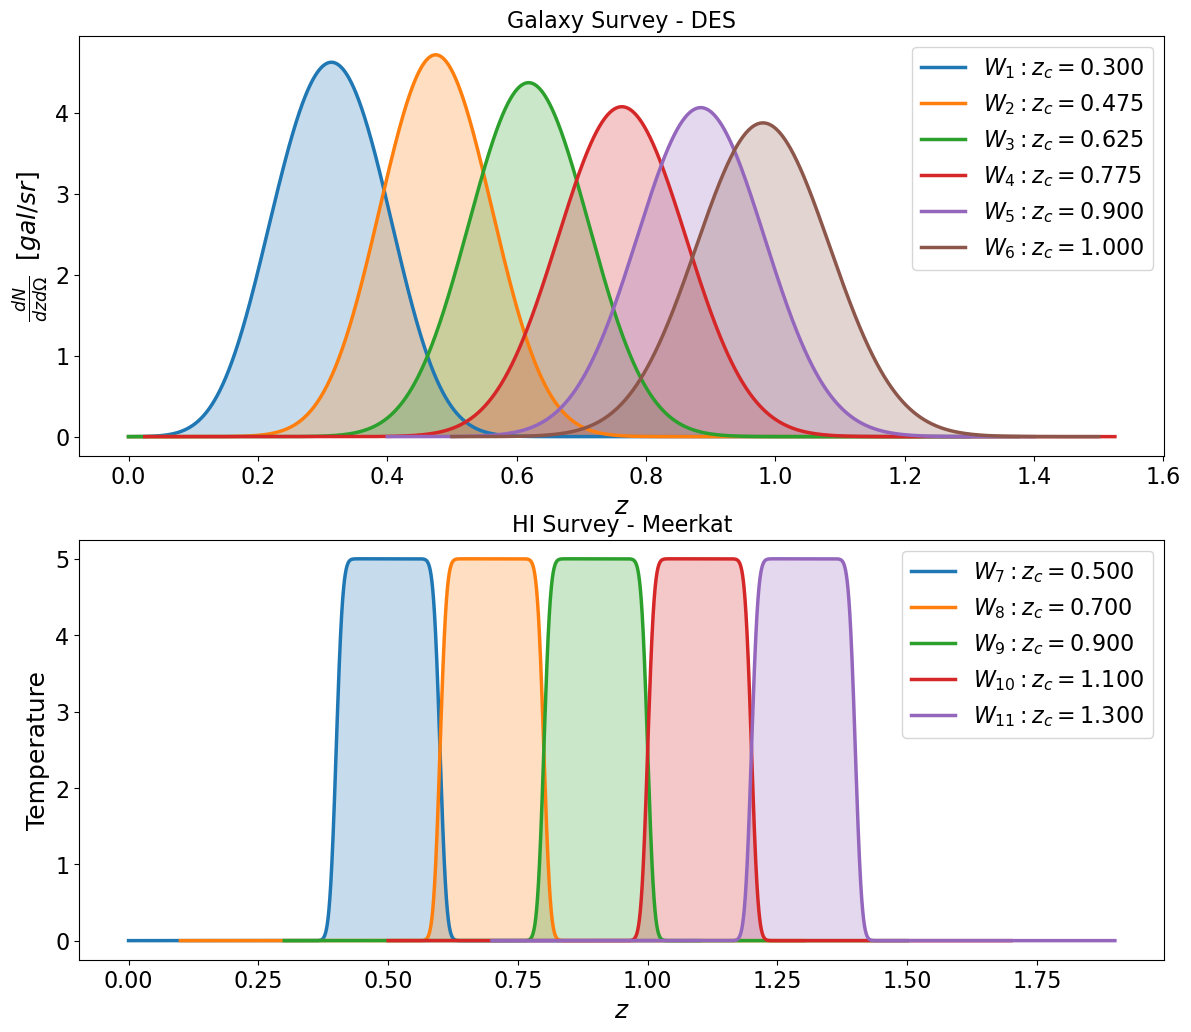

In [39]:
N_bins_Total = N_bins_Gal+N_bins_HI

# Creating central redshifts and redshift combinations
arr_z_central = np.zeros(N_bins_Total)
arr_bin_width = np.zeros(N_bins_Total)
arr_bin_width_nu = np.zeros(N_bins_HI)

for i in range(N_bins_Total):
    if i < N_bins_Gal:
        if Survey_Gal == "Euclid":
            arr_z_central[i] = arr_z_central_Euclid[i]
            if i < N_bins_Gal-1:
                arr_bin_width[i] = np.abs(arr_z_central_Euclid[i+1] - arr_z_central_Euclid[i])
            else:
                arr_bin_width[i] = np.abs(arr_z_central_Euclid[i] - arr_z_central_Euclid[i-1])
        elif Survey_Gal == "DES":
            arr_z_central[i] = arr_z_central_DES[i]
            arr_bin_width[i] = np.abs(arr_z_min_DES[i] - arr_z_max_DES[i])
            # arr_bin_width[i] = np.abs(arr_z_min_long_DES[i] - arr_z_max_long_DES[i])
        elif Survey_Gal == "LSST":
            arr_z_central[i] = arr_z_central_LSST_Y10[i]
            arr_bin_width[i] = bin_width_LSST
    else:
        index_HI = i-N_bins_Gal
        # ic(index_HI)
        arr_z_central[i] = arr_z_central_HI[index_HI]
        arr_bin_width[i] = bin_width_HI[index_HI]
        nu_1 = nu_ref / ((arr_z_central_HI[index_HI]-bin_width_HI[index_HI]/2) + 1)
        nu_2 = nu_ref / ((arr_z_central_HI[index_HI]+bin_width_HI[index_HI]/2) + 1)
        arr_bin_width_nu[index_HI] =  np.abs( nu_1 - nu_2 )
ic(arr_bin_width)

# Identify the z-bins of Gal and HI survey
dic_Gal_HI_id  = {}
dic_Gal_HI_id["Gal"] = np.arange(0, N_bins_Gal, 1)
dic_Gal_HI_id["HI"] = np.arange(N_bins_Gal, N_bins_Total, 1)



################# 
# Calculate Window functions
#################

arr_sigma_z = np.zeros(N_bins_Total)
for index_zc in range(N_bins_Total):
    if index_zc in dic_Gal_HI_id["Gal"]:
        arr_sigma_z[index_zc] = sigma_val
    elif index_zc in dic_Gal_HI_id["HI"]:
        arr_sigma_z[index_zc] = sigma_val_HI


dic_arr_zs = {}
for index_zc, z_c in enumerate(arr_z_central):
    
    if index_zc in dic_Gal_HI_id["Gal"]:
        arr_zs = np.arange( np.max( [0, z_c - 5*arr_bin_width[index_zc]] ) , z_c + 5*arr_bin_width[index_zc], 10**-4)
        # arr_zs = np.arange(0, np.max(arr_z_central[:N_bins_Gal])+ 2*np.max(arr_bin_width), 10**-3)

    elif index_zc in dic_Gal_HI_id["HI"]:
        arr_zs = np.arange( np.max( [0, z_c - 3*arr_bin_width[index_zc]] ) , z_c + 3*arr_bin_width[index_zc], 10**-4)
        # arr_zs = np.arange(0, np.max(arr_z_central[N_bins_Gal-1:])+ 2*np.max(arr_bin_width), 10**-3)

    # arr_zs = np.arange(0, np.max(arr_z_central)+ 2*np.max(arr_bin_width), 10**-3)

    dic_arr_zs[ index_zc ] = arr_zs


if Survey_Gal == "LSST":
    arr_ngal_bin = np.zeros(10)
    for index_zc, z_c in enumerate(arr_z_central):
        # Constructing dictionaty of Shot Noise values
        if index_zc in dic_Gal_HI_id["Gal"] and Survey_Gal=="LSST":
            arr_zs = dic_arr_zs[index_zc]
            arr_W = W_erf(arr_zs, z_c, bin_width_LSST, sigma_val_LSST)
            norm_factor = N_gal_LSST_Y10_str / sc.integrate.trapezoid(pz_LSST_Y10(arr_zs, z0_LSST_Y10), arr_zs)
            
            arr_ngal_bin[index_zc] = sc.integrate.trapezoid(arr_W * norm_factor * pz_LSST_Y10(z_c, z0_LSST_Y10) , arr_zs)


dic_Window  = Window_func_Gal_HI(dic_arr_zs, arr_z_central, z0_value, N_gal_value, 
                                arr_sigma_val=arr_sigma_z, arr_bin_width=arr_bin_width, 
                                arr_n_gal=arr_ngal_bin, func_pz=func_pz, func_Tz=Temp_HI, 
                                W_func="W_erf", dic_Gal_HI_id=dic_Gal_HI_id, normalized=True,
                                Show_WS=True, Fig_y_unit="gal/sr", 
                                Name_Survey_Gal=Survey_Gal, Name_Survey_HI=Survey_HI, fig_size=(14,12) )

# Bias values 
dic_gal_bias = {}
for index_zc, z_c in enumerate(arr_z_central):

    if index_zc in dic_Gal_HI_id["Gal"] and Survey_Gal=="DES":
        dic_gal_bias[index_zc] = bias_func_Gal(z_c)
    elif index_zc in dic_Gal_HI_id["Gal"]:
        dic_gal_bias[index_zc] = arr_bias_gal[index_zc]

    if index_zc in dic_Gal_HI_id["HI"] :
        dic_gal_bias[index_zc] = bias_HI(z_c)


In [40]:
# Calculate combinations of z-bins

# # Data_arr_indices_GG_auto = np.zeros( (N_bins_Gal,2) ) 
Data_arr_indices_GG_full = np.zeros( (int(N_bins_Gal*(N_bins_Gal+1)/2), 2) )  
# Data_arr_indices_HIHI_auto = np.zeros( (N_bins_HI,2) ) 
Data_arr_indices_HIHI_full = np.zeros( (int(N_bins_HI*(N_bins_HI+1)/2), 2) ) 
Data_arr_indices_GHI_cross = np.zeros( (int(N_bins_Gal*(N_bins_HI)), 2) ) 
Data_arr_indices_T_full = np.zeros( (int(N_bins_Total*(N_bins_Total+1)/2), 2) ) 

count_G=0
count_HI=0
count_GHI=0
count_T=0

for i in range(N_bins_Total):
    
    # #### GG auto and full combinations
    if i < N_bins_Gal:
        # Data_arr_indices_GG_auto[i] = np.array( [i, i] )
        for j in range( N_bins_Gal -i ):
            Data_arr_indices_GG_full[count_G] = np.array( [i, i+j] )
            count_G+=1


    #### HI auto and full combinations
    else:
        index_HI = i-N_bins_Gal
        # Data_arr_indices_HIHI_auto[index_HI] = np.array( [i, i] )
        for j in range( N_bins_HI -index_HI ):
            Data_arr_indices_HIHI_full[count_HI] = np.array( [i, i+j] )
            count_HI+=1
    

    # #### G HI cross combinations
    if i < N_bins_Gal:
        for j in range( N_bins_Gal, N_bins_Total):
            # index_GHI = N_bins_Gal + j  
            Data_arr_indices_GHI_cross[count_GHI] = np.array( [i, j] )
            count_GHI+=1



    #### Total auto and full combinations
    # z_c_i = arr_z_central[i]
    # Data_arr_zs_auto[i] = np.array( [z_c_i, z_c_i] )

    for j in range( N_bins_Total -i ):
        # z_c_j = arr_z_central[i+j]  # We do i+j since we don't want to repeat combinations 
        # Data_arr_zs_full[count] = np.array( [z_c_i, z_c_j] )
        Data_arr_indices_T_full[count_T] = np.array( [i, i+j] )
        count_T+=1



# ic(Data_arr_indices_GG_full, Data_arr_indices_HIHI_auto, Data_arr_indices_HIHI_full, Data_arr_indices_T_full)
# ic(Data_arr_indices_GHI_cross)


# Data_G_f_HI_a = np.vstack([Data_arr_indices_GG_full, Data_arr_indices_HIHI_auto])
Data_G_f_HI_f = np.vstack([Data_arr_indices_GG_full, Data_arr_indices_HIHI_full])
Data_G_f_GHI_c = np.vstack([Data_arr_indices_GG_full, Data_arr_indices_GHI_cross])
# ic(Data_G_f_GHI_c)

#### Visualise

In [84]:
# # Create figure with three subplots

# # dic_Window_vis  = Window_func_Gal_HI(arr_zs, arr_z_central, z0_value, N_gal_value, 
# #                                 arr_sigma_val=arr_sigma_z, arr_bin_width=arr_bin_width, 
# #                                 arr_n_gal=arr_ngal_bin, func_pz=func_pz, func_Tz=Temp_HI, 
# #                                 W_func="W_erf", dic_Gal_HI_id=dic_Gal_HI_id, normalized=False,
# #                                 Show_WS=True, Fig_y_unit="gal/sr", 
# #                                 Name_Survey_Gal=Survey_Gal, Name_Survey_HI=Survey_HI, fig_size=(10,10) )

# arr_zs_total = np.arange(0, np.max(arr_z_central)+2*np.max(arr_bin_width), 10**-4)
# arr_ngal_bin_LSST = np.zeros(10)
# for index_zc, z_c in enumerate(arr_z_central):
#     # Constructing dictionaty of Shot Noise values
#     if index_zc in dic_Gal_HI_id["Gal"] and Survey_Gal=="LSST":
#         # arr_zs = dic_arr_zs[index_zc]

#         sigma_zc = sigma_val_LSST * (1+z_c)
#         arr_W = W_erf(arr_zs_total, z_c, bin_width_LSST, sigma_zc)
#         norm_factor = N_gal_LSST_Y10_str / sc.integrate.trapezoid(pz_LSST_Y10(arr_zs_total, z0_LSST_Y10), arr_zs_total)
        
#         arr_ngal_bin_LSST[index_zc] = sc.integrate.trapezoid(arr_W * norm_factor * pz_LSST_Y10(z_c, z0_LSST_Y10) , arr_zs_total)
#         # arr_ngal_bin_LSST[index_zc] = sc.integrate.trapezoid(dic_Window_vis[index_zc], arr_zs)



# # fig, axes = plt.subplots(3, 1, figsize=(7,8), sharex=True)
# fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(10,11), sharex="col", 
#                         gridspec_kw={ 'hspace': 0}  # no spacing
#                         ) 
# # subplot: Number density of galaxies
# axes[0].plot(arr_z_central_DES, arr_ngal_bin_DES, "s", color=Galaxy_Colors[0],label="DES-like")
# axes[0].plot(arr_z_central_LSST_Y10, arr_ngal_bin_LSST, "-o", color=Galaxy_Colors[2],label="LSST-like")
# axes[0].plot(arr_z_central_Euclid, arr_ngal_bin_Euclid, "^", ms=7, color=Galaxy_Colors[4],label="Euclid-like")
# axes[0].set_ylabel(r"$n_\mathrm{gal} \quad [\mathrm{gal/sr}]$", fontsize=20)
# axes[0].set_yscale("log")
# axes[0].legend(loc="upper right",fontsize=18)
# axes[0].grid(True, alpha=0.3)


# # subplot: Galaxy bias
# axes[1].plot(arr_z_central_DES, gal_bias_DES(arr_z_central_DES), "-s", lw=1, color=Galaxy_Colors[0], label="DES-like")
# axes[1].plot(arr_z_central_LSST_Y10, arr_gal_bias_LSST_Y10, "o", lw=1, color=Galaxy_Colors[2],label="LSST-like")
# axes[1].plot(arr_z_central_Euclid, arr_bias_gal_Euclid, "^", lw=1, color=Galaxy_Colors[4],label="Euclid-like")
# axes[1].set_ylabel(r"$b^G$", fontsize=20)
# axes[1].legend(fontsize=18, loc="lower right")
# axes[1].grid(True, alpha=0.3)


# # subplot: Magnification bias
# axes[2].plot(arr_z_central_DES, arr_mag_bias_DES_Y6, "s", lw=1,color=Galaxy_Colors[0],label="DES-like")
# axes[2].plot(arr_z_central_LSST_Y10, mag_bias_DES(arr_gal_bias_LSST_Y10), "-o", lw=1,color=Galaxy_Colors[2],label="LSST-like")
# axes[2].plot(arr_z_central_Euclid, arr_mag_bias_Euclid, "^", lw=1,color=Galaxy_Colors[4],label="Euclid-like")
# axes[2].set_xlabel(r"$z$", fontsize=20)
# axes[2].set_ylabel(r"$s^G$", fontsize=20)
# axes[2].legend(fontsize=18)
# axes[2].grid(True, alpha=0.3)

# # Adjust layout and display
# plt.tight_layout()
# plt.savefig("Galaxy_Surveys-bz_ngal_sz.pdf", bbox_inches='tight')
# plt.show()




# plt.figure(figsize=(7,4))
# # plt.title("System Temperature", fontsize=20)
# plt.plot(arr_zs_Tsys, arr_Tsys_MK, "o", lw=1, color=HI_Colors[0], label="MeerKLASS")
# plt.plot(arr_zs_Tsys_SKA[6:], arr_Tsys_SKA[6:], "o", lw=1, color=HI_Colors[1], label="SKAO")
# plt.grid(True, alpha=0.3)
# plt.xlabel(r"$z$", fontsize=20)
# plt.ylabel(r"$T_\text{sys}$ [K]", fontsize=20)
# plt.legend(fontsize=18)
# plt.savefig("HI_Surveys-Tsys.pdf", bbox_inches='tight')

# plt.show()

Bins: DES, LSST, Euclid

In [85]:
# arr_zs_vis = np.arange(0, 2.35, 10**-3)
# Surv_Names = [ "DES", 
#               "LSST",
#               "Euclid",
#               ]

# # Galaxy_Colors = [ 
# #                 "#882255", "#CC6677",
# #                 "#117733", "#44AA99",
# #                 "#332288", "#88CCEE" 
# #                 ]

# # HI_Colors = ["#AA4499", "#D6B71C"]

# fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(9,9), sharex="col", 
#                         gridspec_kw={ 'hspace': 0}  # no spacing
#                         ) 

# for index_name, name in enumerate(Surv_Names):
#     N_bins_Gal = 10
#     N_bins_HI = 10
#     if name == "Euclid":
#         N_bins_Gal = 13
#         func_pz = pz_Euclid
#         z0_value = z0_Euclid 
#         N_gal_value = np.sum(arr_ngal_bin_Euclid)
#         arr_ngal_bin  = arr_ngal_bin_Euclid
#         # arr_ngal_bin = np.array([0])

#         sigma_val = 0.05
#         arr_z_c = arr_z_central_Euclid[:N_bins_Gal]
#     elif name == "DES":
#         N_bins_Gal = 6
#         func_pz = pz_DES
#         z0_value = z0_DES 
#         N_gal_value = np.sum(arr_ngal_bin_DES)
#         arr_ngal_bin = arr_ngal_bin_DES[:N_bins_Gal]
#         # arr_ngal_bin = np.array([0])

#         sigma_val = 0.05
#         arr_z_c = arr_z_central_DES
#     elif name == "LSST":
#         func_pz = pz_LSST_Y10
#         z0_value = z0_LSST_Y10 
#         N_gal_value = N_gal_LSST_Y10_str
#         arr_ngal_bin = np.array([0])
#         sigma_val = sigma_val_LSST
#         arr_z_c = arr_z_central_LSST_Y10[:N_bins_Gal]

#     dic_Gal_HI_id  = {}
#     dic_Gal_HI_id["Gal"] = np.arange(0, N_bins_Gal, 1)
#     dic_Gal_HI_id["HI"] = np.array([])


#     arr_bin_width = np.zeros(N_bins_Gal)
 
#     for i in range(N_bins_Gal):
#         if name == "Euclid":
#             if i < N_bins_Gal-1:
#                 arr_bin_width[i] = np.abs(arr_z_central_Euclid[i+1] - arr_z_central_Euclid[i])
#             else:
#                 arr_bin_width[i] = np.abs(arr_z_central_Euclid[i] - arr_z_central_Euclid[i-1])
#         elif name == "DES":
#             arr_bin_width[i] = np.abs(arr_z_min_DES[i] - arr_z_max_DES[i])
#         elif name == "LSST":
#             arr_bin_width[i] = bin_width_LSST

#     dic_arr_zs_vis = {}
#     arr_sigma_z = np.zeros(len(arr_z_c))
#     for i, z_c in enumerate(arr_z_c):
#         # if i in dic_Gal_HI_id["Gal"]:
#         arr_sigma_z[i] = sigma_val
#         dic_arr_zs_vis[i] = arr_zs_vis

#     dic_Window_vis  = Window_func_Gal_HI(dic_arr_zs_vis, arr_z_c, z0_value, N_gal_value, 
#                                 arr_sigma_val=arr_sigma_z, arr_bin_width=arr_bin_width, 
#                                 arr_n_gal=arr_ngal_bin, func_pz=func_pz, W_func="W_erf",
#                                 dic_Gal_HI_id=dic_Gal_HI_id, normalized=True,
#                                 Show_WS=False)
#     # norm_term = 0
#     # for index_zc, z_c in enumerate(arr_z_c):
#     #     if norm_term < np.sum(dic_Window_vis[index_zc]):
#     #         norm_term = np.sum(dic_Window_vis[index_zc]) 
    
#     for index_zc, z_c in enumerate(arr_z_c):
#         if index_zc == 0:
#             axes[index_name].plot(arr_zs_vis, 
#                                   dic_Window_vis[ index_zc ], 
#                                 #   dic_Window_vis[ index_zc ]/norm_term * (dic_Window_vis["Total"]/np.max(dic_Window_vis["Total"])), 
#                                   lw=1.5, 
#                                 #   color="k", 
#                                   color=Galaxy_Colors[2*index_name], 
#                                 label=name + f"-like: {N_bins_Gal} z-bins")
#         else:
#             axes[index_name].plot(arr_zs_vis, 
#                                   dic_Window_vis[ index_zc ], 
#                                 #   dic_Window_vis[ index_zc ]/norm_term * (dic_Window_vis["Total"]/np.max(dic_Window_vis["Total"])), 
#                                   lw=1.5, 
#                                 #   color="k"
#                                   color=Galaxy_Colors[2*index_name]
#                                   )
#         axes[index_name].fill_between(arr_zs_vis, 
#                                       dic_Window_vis[ index_zc ], 
#                                     #   dic_Window_vis[ index_zc ]/norm_term * (dic_Window_vis["Total"]/np.max(dic_Window_vis["Total"])), 
#                                       y2=np.zeros(len( arr_zs_vis )), 
#                                       alpha=0.2, 
#                                       color=Galaxy_Colors[2*index_name+1]
#                                         )
#     # axes[index_name].plot(arr_zs_vis, N_gal_value*func_pz(arr_zs_vis, z0_value), color="k")

#     axes[index_name].yaxis.set_major_formatter(ticker.FormatStrFormatter('%.2g'))
#     axes[index_name].legend(fontsize=20)

# plt.xlabel('$z$',fontsize=20)
# plt.ylabel(r"Normalised $\;\; n(z)$", fontsize=20, y=1.5)

# # plt.title(f"Galaxy Survey - {Survey_Gal}")
# # plt.title(f"HI Survey - {Survey_HI}")
# plt.savefig("Window_z-bins_Galaxies.pdf")

# plt.show()

In [86]:
# Surv_Names = [ "MeerKLASS","SKAO"]

# # Galaxy_Colors = [ 
# #                 "#882255", "#CC6677",
# #                 "#117733", "#44AA99",
# #                 "#332288", "#88CCEE" 
# #                 ]

# # HI_Colors = ["#AA4499", "#D6B71C"]



# dic_arr_zs_vis = {}
# for index_zc, z_c in enumerate(arr_z_central):

#     arr_zs_vis = np.linspace(0, 2.35, 1000)

#     dic_arr_zs_vis[ index_zc ] = arr_zs_vis



# fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(12,9), sharex="col", 
#                         gridspec_kw={ 'hspace': 0}  # no spacing
#                         ) 
# for index_name, name in enumerate(Surv_Names):
#     N_bins_Gal = 10
#     N_bins_HI = 5
#     if name == "MeerKLASS":
#         arr_z_c = arr_z_central_MK[:N_bins_HI]
#         arr_bin_width_HI = arr_bin_width_MK
    
#     elif name == "SKAO":
#         N_bins_HI = 8
#         arr_z_c = arr_z_central_SKA[:N_bins_HI]
#         arr_bin_width_HI = arr_bin_width_SKA

#     dic_Gal_HI_id  = {}
#     dic_Gal_HI_id["Gal"] = np.array([])
#     dic_Gal_HI_id["HI"] = np.arange(0, N_bins_HI, 1)

    
#     arr_bin_width = np.zeros(N_bins_HI)
#     arr_sigma_z = np.zeros(N_bins_HI)
#     for i in range(N_bins_HI):
#         arr_bin_width[i] = arr_bin_width_HI[i]
#         if i in dic_Gal_HI_id["HI"]:
#             arr_sigma_z[i] = sigma_val_HI

#     dic_Window_vis  = Window_func_Gal_HI(dic_arr_zs_vis, arr_z_c, z0_value, N_gal_value, 
#                                 arr_sigma_val=arr_sigma_z, arr_bin_width=arr_bin_width, 
#                                 func_Tz=Temp_HI, 
#                                 W_func="W_erf", dic_Gal_HI_id=dic_Gal_HI_id )

#     for index_zc, z_c in enumerate(arr_z_c):
#         if index_zc == 0:
#             axes[index_name].plot(arr_zs_vis, dic_Window_vis[ index_zc ], lw=1.5, color=HI_Colors[index_name], 
#                                 label=name + f": {N_bins_HI} z-bins")
#         else:
#             axes[index_name].plot(arr_zs_vis, dic_Window_vis[ index_zc ], lw=1.5, color=HI_Colors[index_name])

#         axes[index_name].fill_between(arr_zs_vis, dic_Window_vis[ index_zc ], 
#                                     y2=np.zeros(len( arr_zs_vis )), 
#                                     alpha=0.2, color=HI_Colors[index_name] )
    
#     # axes[index_name].plot(arr_zs_vis, Temp_HI(arr_zs_vis), color="k")
    
#     axes[index_name].legend(fontsize=18)

# plt.xlabel('$z$',fontsize=20)
# plt.ylabel("Normalised Temperature",fontsize=20, y=1)
# # plt.title(f"HI Survey - {Survey_HI}")
# plt.savefig("Window_z-bins_HI.pdf")
# plt.show()

### 1.3 Parameters for $C_\ell$ and $w(\theta)$

In [41]:
# Range of theta and ell values

theta_max = 90
# theta_max = 18

#coupled
l_min = np.max( [int(180/theta_max) + (180 % theta_max > 0), 2] )
#decoupled
# l_min = np.max( [int(180/theta_max) + (180 % theta_max > 0), 2] ) +10
# l_min = np.max( [int(180/theta_max) + (180 % theta_max > 0), 2] ) +20


l_max = 1000

theta_min = 180/l_max
# theta_min_str = str(round(theta_min, 2))[0] + str(round(theta_min, 2))[2:]

ic(theta_min, theta_max) 
ic(l_min, l_max)

########################################################## Parameters for C_ell and w(theta) #############################
full_l_min = 2
full_l_max = 1000
ell_step = 10
ells = np.arange(full_l_min, full_l_max+1, ell_step)
ic(len(ells))


theta_val = theta_min
theta_step = 2.245
N_thetas = int((theta_max - theta_min)/theta_step) +1
ic(N_thetas)
thetas = np.empty( N_thetas )
count=0

while theta_val < theta_max:
    thetas[count] = theta_val
    theta_val += theta_step
    count+=1

Pol_Legend = np.zeros( (N_thetas, len(ells))  )
for index_t, teta in enumerate(thetas):
    for index_l, l in enumerate(ells):
        Pol_Legend[index_t,index_l] = sc.special.lpmv(0, l, np.cos( np.radians(teta) ))

ic| theta_min: 0.18, theta_max: 90
ic| l_min: np.int64(2), l_max: 1000
ic| len(ells): 100
ic| N_thetas: 41


### 1.4 Cosmology and Magnification bias values

In [42]:
set_name = "both"
# set_name = "sz"
# set_name = "beta"

# set_name = "only_sz_beta"

In [43]:
############################# Cosmological parameters ####################################
# dic_Cosm_param={"parameter_name" : ["par_info", fiducial_value, h_value]
dic_Cosm_param= {
                  "H0"        : ['hubble_const' , 67.27           , 0.7       ],    # H = 100 h    km s-1 Mpc-1
                  'w'         : ['w'            , -1              , 0.05      ],
                  'Ob'        : ['omega_baryon' , 0.0492          , 10**-4    ],
                  'Ocdm'      : ['omega_cdm'    , 0.2647          , 10**-3    ], 
                #   "As"        : ["curv_amp"     , 2.2065          , 10**-2    ],    # comoving curvature power at k=pivot_scalar
                  "As"        : ["curv_amp"     , 2.2065*10**-9   , 10**-11    ],    # comoving curvature power at k=pivot_scalar
                  "ns"        : ["spec_index"   , 0.9645          , 10**-2    ]     # scalar spectral index
                  }

dic_cosmology = {
    'Omega_M': dic_Cosm_param["Ob"][1] + dic_Cosm_param["Ocdm"][1], 
    'Omega_b': dic_Cosm_param["Ob"][1],
    "Omega_cdm" : dic_Cosm_param["Ocdm"][1],
    'Omega_L': 1-(dic_Cosm_param["Ob"][1] + dic_Cosm_param["Ocdm"][1]),
    "H_0":dic_Cosm_param["H0"][1],  
    'h': dic_Cosm_param["H0"][1]/100,
    'w': dic_Cosm_param["w"][1],
    "A_s": dic_Cosm_param["As"][1],
    'n_s': dic_Cosm_param["ns"][1],
    'sigma_8': 0.8
    }

# Magnification bias values, s(z)
dic_mag_bias = {}
for index_zc, z_c in enumerate(arr_z_central):
    if index_zc in dic_Gal_HI_id["Gal"]:
        if Survey_Gal=="Euclid":
            dic_mag_bias[index_zc] = arr_mag_bias_Euclid[index_zc]
        elif Survey_Gal=="DES":
            dic_mag_bias[index_zc] = arr_mag_bias_DES_Y6[index_zc]
        elif Survey_Gal=="LSST":
            dic_mag_bias[index_zc] = mag_bias_DES(z_c)

    elif index_zc in dic_Gal_HI_id["HI"]:
        dic_mag_bias[index_zc] = 2/5
ic(dic_mag_bias)

if set_name=="both":
    dic_Cosm_param["beta"] = ['beta', 1, 10**-2]
    for index_zc in range(len(arr_z_central)):
        if index_zc in dic_Gal_HI_id["Gal"]:
            dic_Cosm_param[f"s_{index_zc+1}"] = ["mag_bias", dic_mag_bias[index_zc], dic_mag_bias[index_zc]*10**-2]

elif set_name=="sz":
    for index_zc in range(len(arr_z_central)):
        dic_Cosm_param[f"s_{index_zc+1}"] = ["mag_bias", dic_mag_bias[index_zc], dic_mag_bias[index_zc]*10**-2]
        if index_zc>=N_bins_Gal-1:
            break
elif set_name=="beta":
    dic_Cosm_param["beta"] = ['beta', 1, 10**-2]

elif set_name=="only_sz_beta":
    dic_Cosm_param = { 'beta' : ["beta", 1, 10**-2] }
    for index_zc in range(len(arr_z_central)):
        dic_Cosm_param[f"s_{index_zc+1}"] = ["mag_bias", dic_mag_bias[index_zc], dic_mag_bias[index_zc]*10**-2]
        if index_zc>=N_bins_Gal-1:
            break

ic(dic_Cosm_param.keys())



# folder to save the data in
folder_name = "Fisher_Data/"
# String name to save file
save_filename = f"{Survey_Gal}_{N_bins_Gal}zbins_{Survey_HI}_{N_bins_HI}zbins_{set_name}"
print(f"{folder_name}_..._{save_filename}")

Fisher_Data/_..._DES_6zbins_Meerkat_5zbins_both


ic| dic_mag_bias: {0: np.float64(0.6325999999999999),
                   1: np.float64(0.5519999999999999),
                   2: np.float64(0.8172),
                   3: np.float64(0.8834),
                   4: np.float64(0.9804),
                   5: np.float64(0.9663999999999999),
                   6: 0.4,
                   7: 0.4,
                   8: 0.4,
                   9: 0.4,
                   10: 0.4}
ic| dic_Cosm_param.keys(): dict_keys(['H0', 'w', 'Ob', 'Ocdm', 'As', 'ns', 'beta', 's_1', 's_2', 's_3', 's_4', 's_5', 's_6'])


## 2. Covariance Matrix

In [29]:
pars = Cosm_parameters_CAMB(dic_cosmology=dic_cosmology)
dic_C_ell_CAMB = C_ells_CAMB_HI(dic_arr_zs, dic_Window, l_min, l_max, dic_mag_bias, dic_gal_bias,
                                pars_CAMB=pars, dic_Gal_HI_id=dic_Gal_HI_id )

All correlations

In [30]:
Cov_Matrix_full = Fisher_CovM_HI_Gal(Data_arr_indices_T_full, 
                                     arr_z_central, full_l_min, full_l_max,
                                     dic_C_ell_CAMB, dic_f_sky, dic_Gal_HI_id,
                                     arr_n_gal=arr_ngal_bin,
                                     ell_step=ell_step, N_dishes=N_dish, D_dish=D_dish, time_total=t_tot, 
                                     arr_bin_width_nu=arr_bin_width_nu, dic_T_sys=dic_T_sys, Temp_HI_func=Temp_HI,
                                     verbose=True)

### Saving data
np.save(F"{folder_name}FisherM_CovM_full_{save_filename}", Cov_Matrix_full)

Computing small covariance matrix 1 of 53361
Computing small covariance matrix 13341 of 53361
Computing small covariance matrix 26681 of 53361
Computing small covariance matrix 40021 of 53361
Cov Matrix Calculated!


### Partes

In [242]:
# Cov_Matrix_G_f_HI_f = Fisher_CovM_HI_Gal(Data_G_f_HI_f, arr_z_central, full_l_min, full_l_max,
#                                      dic_C_ell_CAMB, dic_f_sky, dic_Gal_HI_id,
#                                      arr_n_gal=arr_ngal_bin,
#                                      ell_step=ell_step, N_dishes=N_dish, D_dish=D_dish, time_total=t_tot, 
#                                      arr_bin_width_nu=arr_bin_width_nu, dic_T_sys=dic_T_sys, Temp_HI_func=Temp_HI,
#                                      verbose=True)

# ### Saving data
# np.save(F"{folder_name}FisherM_CovM_G_f_HI_f_{save_filename}", Cov_Matrix_G_f_HI_f)

In [243]:
# Cov_Matrix_G_f_GHI_c = Fisher_CovM_HI_Gal(Data_G_f_GHI_c, arr_z_central, full_l_min, full_l_max,
#                                      dic_C_ell_CAMB, dic_f_sky, dic_Gal_HI_id,
#                                      arr_n_gal=arr_ngal_bin,
#                                      ell_step=ell_step, N_dishes=N_dish, D_dish=D_dish, time_total=t_tot, 
#                                      arr_bin_width_nu=arr_bin_width_nu, dic_T_sys=dic_T_sys, Temp_HI_func=Temp_HI,
#                                      verbose=True)

# ### Saving data
# np.save(F"{folder_name}FisherM_CovM_G_f_GHI_c_{save_filename}", Cov_Matrix_G_f_GHI_c)

In [244]:
# Visualizing_Cov_Matrix_Gal_HI(Data_arr_zs_full, l_min, l_max, ell_step, Cov_Matrix_full, fig_size=(10,10))

## 3. Derivatives

In [31]:
pars = Cosm_parameters_CAMB(dic_cosmology=dic_cosmology)

dic_derivatives_full = Fisher_derivative_Gal_HI(Data_arr_indices_T_full, arr_z_central, dic_arr_zs, dic_Window, 
                                            full_l_min, full_l_max, 
                                            dic_mag_bias, dic_gal_bias, dic_Cosm_param, C_ells_CAMB_HI, 
                                            ell_step=ell_step, dic_Gal_HI_id=dic_Gal_HI_id, 
                                            dic_cosmology=dic_cosmology, Temp_HI_func=Temp_HI,
                                            verbose=True )   


### Saving data
with open(F"{folder_name}FisherM_deriv_full_{save_filename}.pkl", 'wb') as file:
    pickle.dump(dic_derivatives_full, file)

Computing derivatives: H0
Computing derivatives: w
Computing derivatives: Ob
Computing derivatives: Ocdm
Computing derivatives: As
Computing derivatives: ns
Computing derivatives: beta
Computing derivatives: s_1
Computing derivatives: s_2
Computing derivatives: s_3
Computing derivatives: s_4
Computing derivatives: s_5
Computing derivatives: s_6
Computing derivatives: s_7
Computing derivatives: s_8
Computing derivatives: s_9
Computing derivatives: s_10
Computing derivatives: s_11
Computing derivatives: s_12
Computing derivatives: s_13
Derivatives Calculated!


In [246]:
# Visualizing_derivatives_Gal_HI( Data_arr_zs_full, l_min, l_max, ell_step, dic_Cosm_param, dic_derivatives_full, aspect_val=1/250 )

### Partes

In [247]:
# pars = Cosm_parameters_CAMB(dic_cosmology=dic_cosmology)

# dic_derivatives_G_f_HI_f = Fisher_derivative_Gal_HI(Data_G_f_HI_f, arr_z_central, dic_arr_zs, dic_Window, 
#                                             full_l_min, full_l_max, 
#                                             dic_mag_bias, dic_gal_bias, dic_Cosm_param, C_ells_CAMB_HI, 
#                                             ell_step=ell_step, dic_Gal_HI_id=dic_Gal_HI_id, 
#                                             dic_cosmology=dic_cosmology, Temp_HI_func=Temp_HI,
#                                             verbose=True )   


# ### Saving data
# with open(F"{folder_name}FisherM_deriv_G_f_HI_f_{save_filename}.pkl", 'wb') as file:
#     pickle.dump(dic_derivatives_G_f_HI_f, file)

In [248]:
# pars = Cosm_parameters_CAMB(dic_cosmology=dic_cosmology)

# dic_derivatives_G_f_GHI_c = Fisher_derivative_Gal_HI(Data_G_f_GHI_c, arr_z_central, dic_arr_zs, dic_Window, 
#                                             full_l_min, full_l_max, 
#                                             dic_mag_bias, dic_gal_bias, dic_Cosm_param, C_ells_CAMB_HI, 
#                                             ell_step=ell_step, dic_Gal_HI_id=dic_Gal_HI_id, 
#                                             dic_cosmology=dic_cosmology, Temp_HI_func=Temp_HI,
#                                             verbose=True )   


# ### Saving data
# with open(F"{folder_name}FisherM_deriv_G_f_GHI_c_{save_filename}.pkl", 'wb') as file:
#     pickle.dump(dic_derivatives_G_f_GHI_c, file)

## 4. Fisher Matrix  $C_\ell$

### Full correlations

In [32]:
# # Loading data

save_filename_both = f"{Survey_Gal}_{N_bins_Gal}zbins_{Survey_HI}_{N_bins_HI}zbins_both"
ic(save_filename_both)

Cov_Matrix_both = np.load(F"{folder_name}FisherM_CovM_full_{save_filename_both}.npy")


with open(F"{folder_name}FisherM_deriv_full_{save_filename_both}.pkl", 'rb') as file:
    dic_derivatives_both = pickle.load(file)

ic| save_filename_both: 'Euclid_13zbins_SKA_8zbins_both'


Builing diagonal Matrix
Computing Fisher matrix entry 1 of 400
Computing Fisher matrix entry 81 of 400
Computing Fisher matrix entry 161 of 400
Computing Fisher matrix entry 241 of 400
Computing Fisher matrix entry 321 of 400


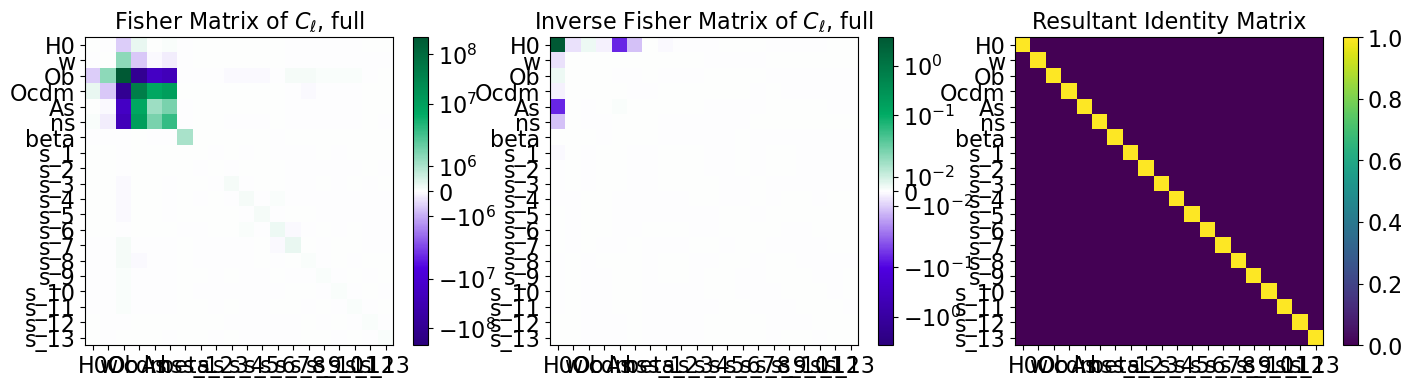

ic| np.sum(Matrix @ Matrix_inv): np.float64(20.00000000015126)


In [33]:
# Calculating matrix
list_CosmP_log = [ "As" ]
# list_CosmP_log = [ "H0", "Ob", "Ocdm", "As"]

Fish_Cl_full = Fisher_Matrix_Cl_better(Data_arr_indices_T_full, dic_Cosm_param, Cov_Matrix_both, dic_derivatives_both, 
                                full_l_min, l_min, full_l_max, l_max, dic_f_sky, dic_Gal_HI_id=dic_Gal_HI_id,
                                ell_step=ell_step, list_CosmP_log=list_CosmP_log, verbose=True)

# Ploting Matrix
Visualising_F_Matrices( Fish_Cl_full, dic_Cosm_param, 
                        list_titles=[r"Fisher Matrix of $C_\ell$, full",r"Inverse Fisher Matrix of $C_\ell$, full",
                                    "Resultant Identity Matrix"])

# Saving data
df_Cl_full = pd.DataFrame(data=Fish_Cl_full.astype(float))
df_Cl_full.to_csv(F"{folder_name}FisherM_Cl_full_{save_filename}.csv", sep=' ', header=False, float_format='%.8g', index=False)

In [36]:
ic(np.diagonal(Fish_Cl_full))

skip_value = 0

Inv_FM_Cell = np.linalg.inv(    np.linalg.inv( np.linalg.inv(Fish_Cl_full)[skip_value:,skip_value:] )    )
# Inv_FM_Cell = np.linalg.inv( Fish_Cl_full )
ic(np.diagonal(Inv_FM_Cell))


for i,key in enumerate(dic_Cosm_param.keys()):
    if i < skip_value:
        continue

    if key in list_CosmP_log:
        Key_value = np.log(dic_Cosm_param[key][1])
    else:
        Key_value = dic_Cosm_param[key][1]

    err_percent = np.sqrt(np.diagonal(Inv_FM_Cell)[i-skip_value]) / np.abs(Key_value) *100
    # err_percent = np.sqrt(np.diagonal(Inv_FM_Cell)[i]) / np.abs(dic_Cosm_param[key][1]) *100
    print(key,   f"{err_percent:.3f}"  )


ic( np.linalg.det(Fish_Cl_full) )
ic( np.linalg.det(np.linalg.inv( Fish_Cl_full )) )

H0 2.891
w 1.287
Ob 4.474
Ocdm 1.425
As 0.167
ns 0.812
beta 0.098
s_1 53.824
s_2 5.394
s_3 1.258
s_4 1.339
s_5 1.454
s_6 0.949
s_7 0.591
s_8 1.039
s_9 0.884
s_10 0.614
s_11 0.444
s_12 0.320
s_13 0.355


ic| np.diagonal(Fish_Cl_full): array([1.70085107e+03, 2.89989531e+04, 2.20467070e+08, 4.32459064e+07,
                                      1.17625078e+06, 2.91895630e+06, 1.04935766e+06, 7.66871744e+03,
                                      2.65034099e+04, 1.35571254e+05, 1.18800731e+05, 1.15922226e+05,
                                      2.02342779e+05, 2.47502891e+05, 6.13962133e+04, 6.45586054e+04,
                                      7.15254003e+04, 6.49980106e+04, 8.61256152e+04, 7.25167351e+04])
ic| np.diagonal(Inv_FM_Cell): array([3.78142087e+00, 1.65643447e-04, 4.84577468e-06, 1.42369303e-05,
                                     1.11067955e-03, 6.13983502e-05, 9.65074086e-07, 1.53250978e-04,
                                     5.30342504e-05, 9.72920562e-06, 1.14814088e-05, 1.08915006e-05,
                                     7.05363396e-06, 5.37580253e-06, 2.49882564e-05, 2.84271702e-05,
                                     2.33817762e-05, 2.20374779e-05, 1.32681578e-05, 

np.float64(2.19324548575471e-95)

### Partes

ic| save_filename_both: 'DES_6zbins_SKA_6zbins_both'


Builing diagonal Matrix
Computing Fisher matrix entry 1 of 169
Computing Fisher matrix entry 34 of 169
Computing Fisher matrix entry 67 of 169
Computing Fisher matrix entry 100 of 169
Computing Fisher matrix entry 133 of 169
Computing Fisher matrix entry 166 of 169


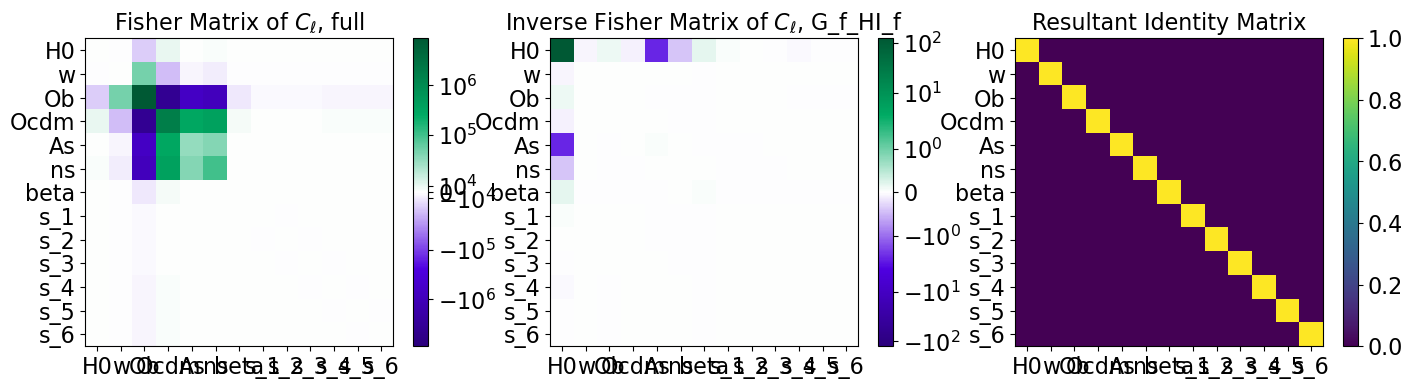

ic| np.sum(Matrix @ Matrix_inv): np.float64(13.000000000300396)


In [ ]:
# # # Loading data

# save_filename_both = f"{Survey_Gal}_{N_bins_Gal}zbins_{Survey_HI}_{N_bins_HI}zbins_both"
# ic(save_filename_both)

# Cov_Matrix_both_G_f_HI_f = np.load(F"{folder_name}FisherM_CovM_G_f_HI_f_{save_filename_both}.npy")


# with open(F"{folder_name}FisherM_deriv_G_f_HI_f_{save_filename_both}.pkl", 'rb') as file:
#     dic_derivatives_both_G_f_HI_f = pickle.load(file)


# # Calculating matrix
# list_CosmP_log = [ "As" ]
# # list_CosmP_log = [ "H0", "Ob", "Ocdm", "As"]

# Fish_Cl_G_f_HI_f = Fisher_Matrix_Cl_better(Data_G_f_HI_f, dic_Cosm_param, Cov_Matrix_both_G_f_HI_f, dic_derivatives_both_G_f_HI_f, 
#                                 full_l_min, l_min, full_l_max, l_max, dic_f_sky, dic_Gal_HI_id=dic_Gal_HI_id,
#                                 ell_step=ell_step, list_CosmP_log=list_CosmP_log, verbose=True)

# # Ploting Matrix
# Visualising_F_Matrices( Fish_Cl_G_f_HI_f, dic_Cosm_param, 
#                         list_titles=[r"Fisher Matrix of $C_\ell$, full",r"Inverse Fisher Matrix of $C_\ell$, G_f_HI_f",
#                                     "Resultant Identity Matrix"])

# # Saving data
# df_Cl_G_f_HI_f = pd.DataFrame(data=Fish_Cl_G_f_HI_f.astype(float))
# df_Cl_G_f_HI_f.to_csv(F"{folder_name}FisherM_Cl_G_f_HI_f_{save_filename}.csv", sep=' ', header=False, float_format='%.8g', index=False)

ic| save_filename_both: 'DES_6zbins_SKA_6zbins_both'


Builing diagonal Matrix
Computing Fisher matrix entry 1 of 169
Computing Fisher matrix entry 34 of 169
Computing Fisher matrix entry 67 of 169
Computing Fisher matrix entry 100 of 169
Computing Fisher matrix entry 133 of 169
Computing Fisher matrix entry 166 of 169


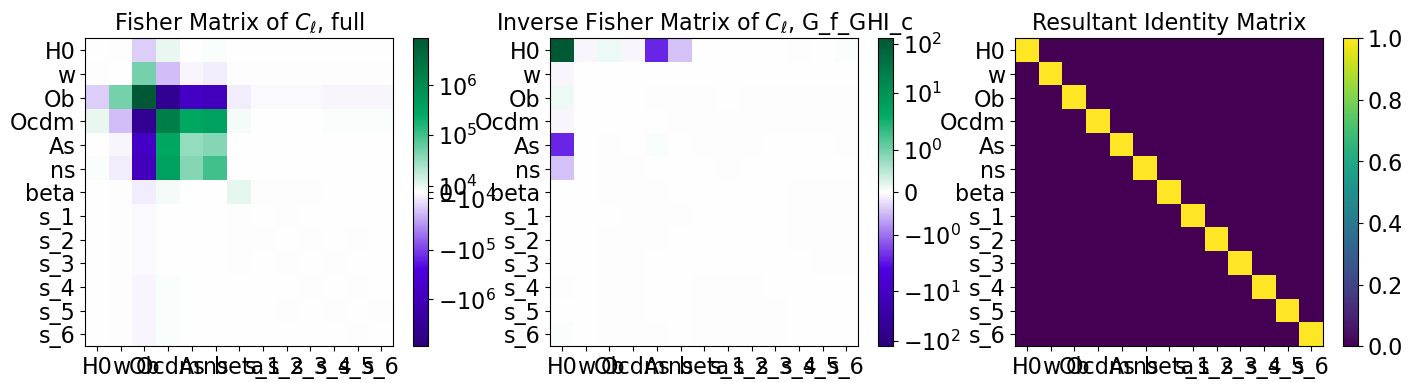

ic| np.sum(Matrix @ Matrix_inv): np.float64(13.000000000100378)


In [ ]:
# # # Loading data

# save_filename_both = f"{Survey_Gal}_{N_bins_Gal}zbins_{Survey_HI}_{N_bins_HI}zbins_both"
# ic(save_filename_both)

# Cov_Matrix_both_G_f_GHI_c = np.load(F"{folder_name}FisherM_CovM_G_f_GHI_c_{save_filename_both}.npy")


# with open(F"{folder_name}FisherM_deriv_G_f_GHI_c_{save_filename_both}.pkl", 'rb') as file:
#     dic_derivatives_both_G_f_GHI_c = pickle.load(file)


# # Calculating matrix
# list_CosmP_log = [ "As" ]
# # list_CosmP_log = [ "H0", "Ob", "Ocdm", "As"]

# Fish_Cl_G_f_GHI_c = Fisher_Matrix_Cl_better(Data_G_f_GHI_c, dic_Cosm_param, Cov_Matrix_both_G_f_GHI_c, dic_derivatives_both_G_f_GHI_c, 
#                                 full_l_min, l_min, full_l_max, l_max, dic_f_sky, dic_Gal_HI_id=dic_Gal_HI_id,
#                                 ell_step=ell_step, list_CosmP_log=list_CosmP_log, verbose=True)
# # ic(Fish_Cl_G_f_GHI_c)
# # Ploting Matrix
# Visualising_F_Matrices( Fish_Cl_G_f_GHI_c, dic_Cosm_param, 
#                         list_titles=[r"Fisher Matrix of $C_\ell$, full",r"Inverse Fisher Matrix of $C_\ell$, G_f_GHI_c",
#                                     "Resultant Identity Matrix"])

# # Saving data
# df_Cl_G_f_GHI_c = pd.DataFrame(data=Fish_Cl_G_f_GHI_c.astype(float))
# df_Cl_G_f_GHI_c.to_csv(F"{folder_name}FisherM_Cl_G_f_GHI_c_{save_filename}.csv", sep=' ', header=False, float_format='%.8g', index=False)

## 5. Fisher Matrix $w(\theta)$

ic| delta_theta: np.float64(2.245)
    arr_thetas.min(): np.float64(0.18)
    scale_factor: np.float64(12.472222222222223)


Computing small covariance matrix 1 of 4356
Computing small covariance matrix 872 of 4356
Computing small covariance matrix 1743 of 4356
Computing small covariance matrix 2614 of 4356
Computing small covariance matrix 3485 of 4356


ic| np.sum( Big_Matrix @ Big_Matrix_inv ): np.float64(2706.000000004654)
    N_data*N_thetas: 2706


Computing derivatives
Fisher Matrix calculated!


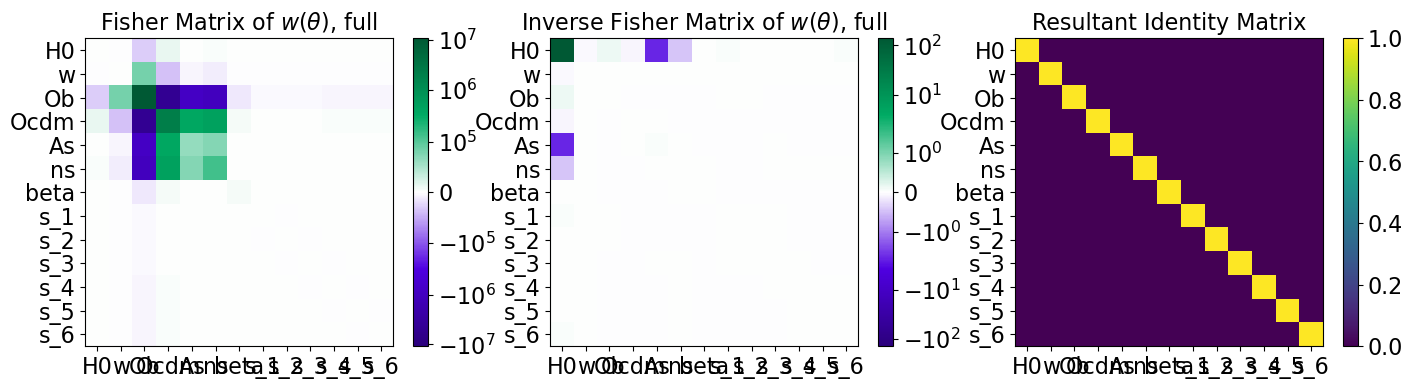

ic| np.sum(Matrix @ Matrix_inv): np.float64(12.999999999917588)


In [44]:
# Loading data
Cov_Matrix_full = np.load(F"{folder_name}FisherM_CovM_full_{save_filename}.npy")

with open(F"{folder_name}FisherM_deriv_full_{save_filename}.pkl", 'rb') as file:
    dic_derivatives_full = pickle.load(file)


# list_CosmP_log = [ "H0", "Ob", "Ocdm", "As" ]
list_CosmP_log = [ "As" ]
Fish_w_full = Fisher_Matrix_w(Data_arr_indices_T_full, ells, thetas, Pol_Legend, dic_Cosm_param, Cov_Matrix_full, 
                              dic_derivatives_full, dic_f_sky, 
                              dic_Gal_HI_id=dic_Gal_HI_id, list_CosmP_log=list_CosmP_log, verbose=True)


Visualising_F_Matrices( Fish_w_full, dic_Cosm_param, 
                       list_titles=[r"Fisher Matrix of $w(\theta)$, full",r"Inverse Fisher Matrix of $w(\theta)$, full",
                                    "Resultant Identity Matrix"])

# # Saving data
df_w_full = pd.DataFrame(data=Fish_w_full.astype(float))
df_w_full.to_csv(F"{folder_name}FisherM_w_full_{save_filename}.csv", sep=' ', header=False, float_format='%.8g', index=False)

In [45]:
Inv_FM_w = np.linalg.inv( Fish_w_full )

for i,key in enumerate(dic_Cosm_param.keys()):
    if key in list_CosmP_log:
        Key_value = np.log(dic_Cosm_param[key][1])
    else:
        Key_value = dic_Cosm_param[key][1]

    err_percent = np.sqrt(np.diagonal(Inv_FM_w)[i]) / np.abs(Key_value) *100
    print(key,   f"{err_percent:.3f}"  )

H0 17.509
w 5.543
Ob 26.680
Ocdm 7.528
As 0.986
ns 4.675
beta 1.266
s_1 6.238
s_2 4.989
s_3 4.108
s_4 3.702
s_5 3.230
s_6 3.745


In [76]:
# # Loading data
# Cov_Matrix_full = np.load(F"{folder_name}FisherM_CovM_full_{save_filename}.npy")

# with open(F"{folder_name}FisherM_deriv_full_{save_filename}.pkl", 'rb') as file:
#     dic_derivatives_full = pickle.load(file)

# list_CosmP_log = [ "As" ]

# # list_theta_step = np.array([0.9, 1, 1.5, 1.75,  2, 2.25, 2.5, 2.75, 3, 3.25, 3.5, 3.75, 4, 4.25, 4.5, 4.75, 5, 6])
# list_theta_step = np.linspace(1.25, 2.25, 200)
# H0_err_percent = np.zeros(len(list_theta_step))
# w_err_percent = np.zeros(len(list_theta_step))
# Ob_err_percent = np.zeros(len(list_theta_step))
# Ocdm_err_percent = np.zeros(len(list_theta_step))
# As_err_percent = np.zeros(len(list_theta_step))
# ns_err_percent = np.zeros(len(list_theta_step))
# for index_ts, theta_step in enumerate(list_theta_step):

#     theta_val = theta_min
#     N_thetas = int((theta_max - theta_min)/theta_step) +1
#     # ic(N_thetas)
#     thetas = np.empty( N_thetas )
#     count=0

#     while theta_val < theta_max:
#         thetas[count] = theta_val
#         theta_val += theta_step
#         count+=1

#     Pol_Legend = np.zeros( (N_thetas, len(ells))  )
#     for index_t, teta in enumerate(thetas):
#         for index_l, l in enumerate(ells):
#             Pol_Legend[index_t,index_l] = sc.special.lpmv(0, l, np.cos( np.radians(teta) ))

#     Fish_w_full = Fisher_Matrix_w(Data_arr_indices_full, ells, thetas, Pol_Legend, dic_Cosm_param, Cov_Matrix_full, 
#                                 dic_derivatives_full, dic_f_sky, 
#                                 dic_Gal_HI_id=dic_Gal_HI_id, list_CosmP_log=list_CosmP_log, verbose=False)
#     Inv_FM_w = np.linalg.inv( Fish_w_full )

#     for i,key in enumerate(dic_Cosm_param.keys()):
#         if key in list_CosmP_log:
#             Key_value = np.log(dic_Cosm_param[key][1])
#         else:
#             Key_value = dic_Cosm_param[key][1]

#         err_percent = np.sqrt(np.diagonal(Inv_FM_w)[i]) / np.abs(Key_value) *100
#         # err_percent = np.sqrt(np.diagonal(Inv_FM_Cell)[i]) / np.abs(dic_Cosm_param[key][1]) *100
#         # print(key,   f"{err_percent:.3f}"  )

#         if i == 0:
#             H0_err_percent[index_ts] = err_percent
#         elif i==1:
#             w_err_percent[index_ts] = err_percent
#         elif i==2:
#             Ob_err_percent[index_ts] = err_percent
#         elif i==3:
#             Ocdm_err_percent[index_ts] = err_percent
#         elif i==4:
#             As_err_percent[index_ts] = err_percent
#         elif i==5:
#             ns_err_percent[index_ts] = err_percent

In [77]:
# plt.figure(figsize=(18,8))
# plt.plot(list_theta_step, H0_err_percent, label="H0")
# plt.plot(list_theta_step, w_err_percent, label="w")
# plt.plot(list_theta_step, Ob_err_percent, label="Ob")
# plt.plot(list_theta_step, Ocdm_err_percent, label="Ocdm")
# plt.plot(list_theta_step, As_err_percent, label="As")
# plt.plot(list_theta_step, ns_err_percent, label="ns")
# plt.legend(loc="upper left")
# plt.xlabel("theta step")
# plt.ylabel(r"$\sigma(\lambda) / \lambda \times 100\%$")
# # plt.yscale("log")
# plt.show()
# ic(list_theta_step[np.argmin(H0_err_percent)] )
# ic(list_theta_step[np.argmin(w_err_percent)] )
# ic(list_theta_step[np.argmin(Ob_err_percent)] )
# ic(list_theta_step[np.argmin(Ocdm_err_percent)] )
# ic(list_theta_step[np.argmin(As_err_percent)] )
# ic(list_theta_step[np.argmin(ns_err_percent)] )

## 6. Visualise **Corner plots** 

### C_ell vs w(theta)

ic| key: 'H0'
ic| key: 'w'
ic| key: 'Ob'
ic| key: 'Ocdm'
ic| key: 'As'
ic| key: 'ns'
ic| fid: [67.27, -1, 0.0492, 0.2647, np.float64(-19.931858287218947), 0.9645]


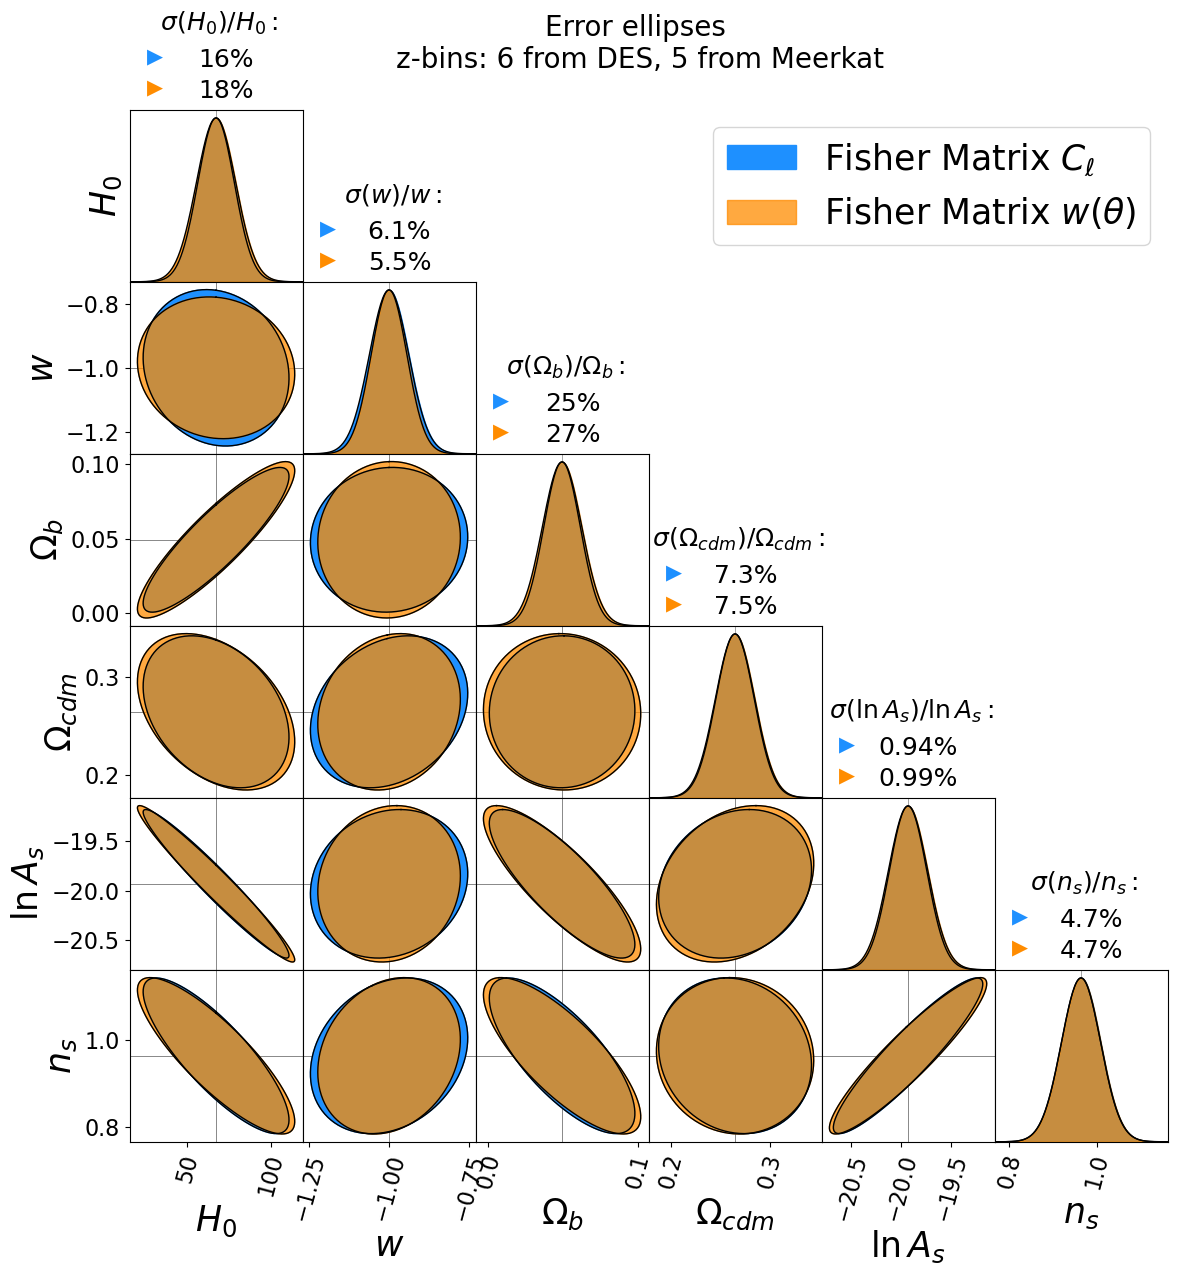

In [48]:
# Importing Fihser Matrices values from  saved data

FIM_Cl_full = np.loadtxt(open(F"{folder_name}FisherM_Cl_full_{save_filename}.csv", "rb"), delimiter=" ", skiprows=0)
FIM_w_full  = np.loadtxt(open(F"{folder_name}FisherM_w_full_{ save_filename}.csv", "rb"), delimiter=" ", skiprows=0)

########################## Corner plots ###################################################################
fid=[]
list_CosmP_log = ["As"]
counter = 1
for key in dic_Cosm_param.keys():

    if key in list_CosmP_log:
        Key_value = np.log(dic_Cosm_param[key][1])
    else:
        Key_value = dic_Cosm_param[key][1]

    # fid.append( Key_value )
    if counter < 7:
        ic(key)
        fid.append( Key_value )
    counter+=1
ic(fid)

par = [
    r'$H_0$',
    r'$w$', 
    r"$\Omega_b$", 
    r"$\Omega_{cdm}$",
    r"$\ln A_s$", 
    r"$n_s$"
    ]
par_titles = par

Plot_title = ("Error ellipses \n" + rf"z-bins: {N_bins_Gal} from {Survey_Gal}, {N_bins_HI} from {Survey_HI}" )

name_fig_corner = f"Figures/CornerP_{set_name}_{Survey_Gal}_{N_bins_Gal}zbins_{Survey_HI}_{N_bins_HI}zbins"

# list_colors = ["#37b67e", "#057041", "#7e71bf", "#4900ac"]
# list_colors = ["dodgerblue", "darkorange", "slateblue", "firebrick"]
list_colors = ["slateblue", "firebrick", "dodgerblue", "darkorange"]

arr_alpha = np.array([
                      1, 
                      0.75,
                      ])
# Only s(z)
# Fishers = [ np.linalg.inv(np.linalg.inv(FIM_Cl_auto) [0:4,0:4]), 
#             np.linalg.inv(np.linalg.inv(FIM_w_auto)  [0:4,0:4]), 
#             np.linalg.inv(np.linalg.inv(FIM_Cl_cross)[0:4,0:4]), 
#             np.linalg.inv(np.linalg.inv(FIM_w_cross) [0:4,0:4]) ]

# Only Cosm param
Fishers = [
            np.linalg.inv(np.linalg.inv(FIM_Cl_full) [:6,:6]), 
            np.linalg.inv(np.linalg.inv(FIM_w_full) [:6,:6]), 
            # np.linalg.inv(np.linalg.inv(FIM_Cl_full)[:6,:6]) 
            ]


# Fishers = [ FIM_Cl_auto, FIM_w_auto, FIM_Cl_full, FIM_w_full ]
# Flabels = [ r"Fisher Matrix $C_\ell$, auto", r"Fisher Matrix $w(\theta)$, auto", r"Fisher Matrix $C_\ell$, full", r"Fisher Matrix $w(\theta)$, full" ]
# CornerPlot( Fishers, fid, par, par_titles, Plot_title, Flabels=Flabels, cores=list_colors, figure_size=(10,8), 
#             Fig_name= name_fig_corner+".png")

# Fishers = [ FIM_Cl_auto, FIM_w_auto]
# Flabels = [ r"Fisher Matrix $C_\ell$, auto", r"Fisher Matrix $w(\theta)$, auto"  ]
# CornerPlot( Fishers, fid, par, par_titles, Plot_title,  Flabels=Flabels, cores=[list_colors[0], list_colors[1]] )

# Fishers = [ FIM_w_full, FIM_w_full ]
# Fishers = [ FIM_Cl_full, FIM_Cl_full ]
# Fishers = [ FIM_Cl_full, FIM_w_full ]
Flabels = [ 
            r"Fisher Matrix $C_\ell$", 
            r"Fisher Matrix $w(\theta)$", 
           ]
CornerPlot( Fishers, fid, par, par_titles, Plot_title, Flabels=Flabels, 
            cores=[
                list_colors[2], 
                list_colors[3],
                ], 
            arr_alpha=arr_alpha,
            Fig_name= name_fig_corner+"_full.pdf", figure_size=(12,12),           
            xy_label_size=25, 
            legend_size=25, 
            sigma_title_size=18)

### Gal Survey x HI Survey

ic| fid: [1,
          np.float64(0.023),
          np.float64(0.135),
          np.float64(0.248),
          np.float64(0.253),
          np.float64(0.227),
          np.float64(0.28),
          np.float64(0.392),
          np.float64(0.481),
          np.float64(0.603),
          np.float64(0.787),
          np.float64(1.057),
          np.float64(1.138),
          np.float64(1.094)]
ic| save_filename_i: 'Euclid_13zbins_Meerkat_0zbins_both'
ic| save_filename_i: 'Euclid_13zbins_Meerkat_5zbins_both'
ic| save_filename_i: 'Euclid_13zbins_SKA_8zbins_both'


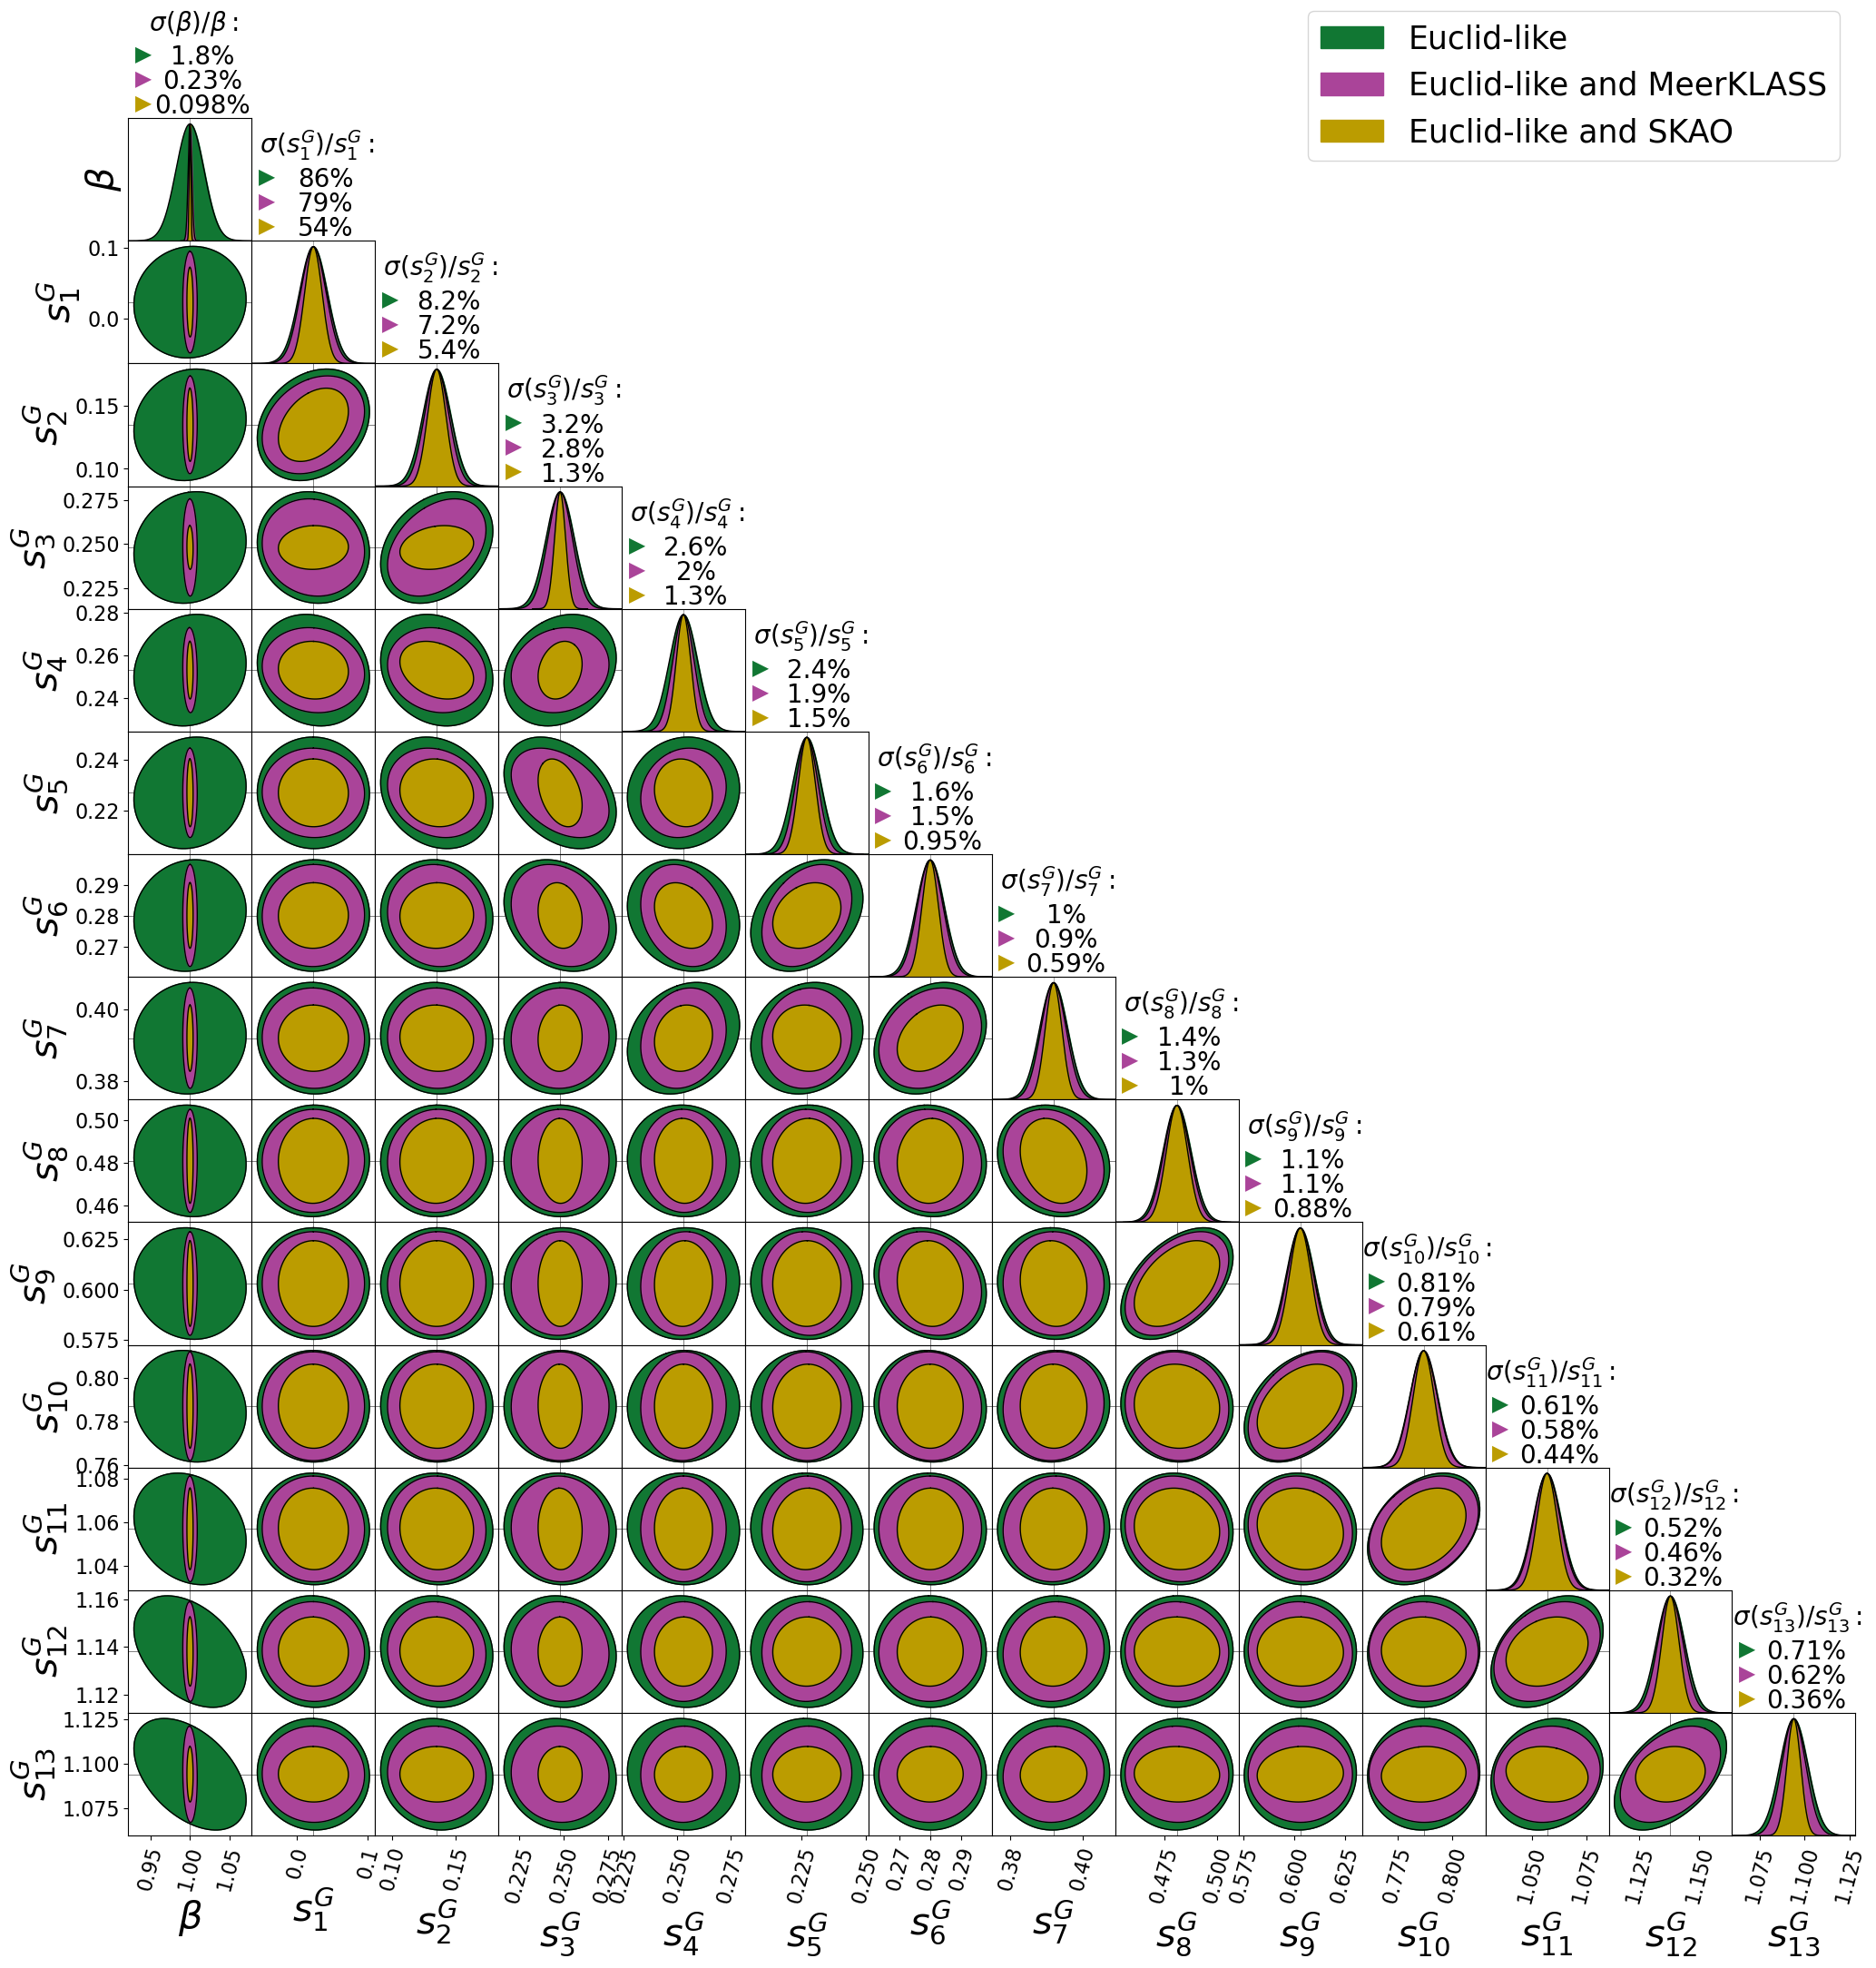

In [35]:
########################## Corner plots ###################################################################
fid=[]
counter = 1
for key in dic_Cosm_param.keys():
    # fid.append( dic_Cosm_param[key][1] )
    if counter >= 7:
        # ic(key)
        fid.append( dic_Cosm_param[key][1] )
    counter+=1
ic(fid)

par = [
    r"$\beta$",
    r"$s^G_1$",
    r"$s^G_2$",
    r"$s^G_3$",
    r"$s^G_4$",
    r"$s^G_5$",
    r"$s^G_6$",
    r"$s^G_7$",
    r"$s^G_8$",
    r"$s^G_9$",
    r"$s^G_{10}$",
    r"$s^G_{11}$",
    r"$s^G_{12}$",
    r"$s^G_{13}$",
    ]
par_titles = par

Plot_title = ("")



# Name_Survey_Gal = "DES" 
# Name_Survey_Gal = "LSST" 
Name_Survey_Gal = "Euclid" 

list_HI_surv  = [
                 "Meerkat",
                 "Meerkat", 
                #  "Meerkat", 
                 "SKA",
                 ]
if Name_Survey_Gal == "DES":
    list_colors = [  Galaxy_Colors[0], HI_Colors[0], HI_Colors[1], HI_Colors[1]  ]
elif Name_Survey_Gal == "LSST":
    list_colors = [  Galaxy_Colors[2], HI_Colors[0], HI_Colors[1]  ]
elif Name_Survey_Gal == "Euclid":
    list_colors = [  Galaxy_Colors[4], HI_Colors[0], HI_Colors[1]  ]

arr_alpha = np.array([
                      1, 
                      1, 
                      1,
                    #   1,
                      ])

Fishers = []
Flabels = []

count=0

# for Name_Survey_Gal in list_Gal_surv:
for Name_Survey_HI in list_HI_surv:
    
    if count == 0 and Name_Survey_HI=="Meerkat":
        Flabels.append( f"{Name_Survey_Gal}-like" )
        save_filename_i = f"{Name_Survey_Gal}_{N_bins_Gal}zbins_{Name_Survey_HI}_{0}zbins_{set_name}"
        FIM_Cl_i = np.loadtxt(open(F"{folder_name}FisherM_Cl_full_{save_filename_i}.csv", "rb"), delimiter=" ", skiprows=0)

    elif count == 1 and Name_Survey_HI=="Meerkat":
        Flabels.append( f"{Name_Survey_Gal}-like and MeerKLASS" )
        save_filename_i = f"{Name_Survey_Gal}_{N_bins_Gal}zbins_{Name_Survey_HI}_{5}zbins_{set_name}"
        FIM_Cl_i = np.loadtxt(open(F"{folder_name}FisherM_Cl_full_{save_filename_i}.csv", "rb"), delimiter=" ", skiprows=0)

    # elif count == 2 and Name_Survey_HI == "Meerkat":
    #     Flabels.append( f"{Name_Survey_Gal}-like and MeerKLASS" )
    #     save_filename_i = f"{Name_Survey_Gal}_{N_bins_Gal}zbins_{Name_Survey_HI}_{5}zbins_{set_name}"
    #     FIM_Cl_i = np.loadtxt(open(F"{folder_name}FisherM_Cl_auto_{save_filename_i}.csv", "rb"), delimiter=" ", skiprows=0)

    elif Name_Survey_HI == "SKA":
        Flabels.append( f"{Name_Survey_Gal}-like and SKAO" )
        save_filename_i = f"{Name_Survey_Gal}_{N_bins_Gal}zbins_{Name_Survey_HI}_{N_bins_HI}zbins_{set_name}"
        FIM_Cl_i = np.loadtxt(open(F"{folder_name}FisherM_Cl_full_{save_filename_i}.csv", "rb"), delimiter=" ", skiprows=0)
            
    # Only beta and s(z)
    Fishers.append( np.linalg.inv( np.linalg.inv(FIM_Cl_i)[6:,6:] ))

    ic(save_filename_i)
    count+=1



CornerPlot( Fishers, fid, par, par_titles, Plot_title, Flabels=Flabels, 
            cores=list_colors, 
            arr_alpha=arr_alpha, 
            # Fig_name= name_fig_corner+"_full.png", 
            Fig_name= f"CornerP_{Name_Survey_Gal}_beta_sz.pdf", 
            # figure_size=(14,14), 
            # figure_size=(18,18), 
            figure_size=(22,22), 
            xy_label_size=30, 
            legend_size=25, 
            sigma_title_size=20)

### Multi-Tracer Cross-correlations

ic| fid: [1,
          np.float64(0.6325999999999999),
          np.float64(0.5519999999999999),
          np.float64(0.8172),
          np.float64(0.8834),
          np.float64(0.9804),
          np.float64(0.9663999999999999)]
ic| save_filename_i: 'DES_6zbins_Meerkat_0zbins_both'
ic| save_filename_i: 'DES_6zbins_SKA_6zbins_both'
ic| save_filename_i: 'DES_6zbins_SKA_6zbins_both'
ic| save_filename_i: 'DES_6zbins_SKA_6zbins_both'


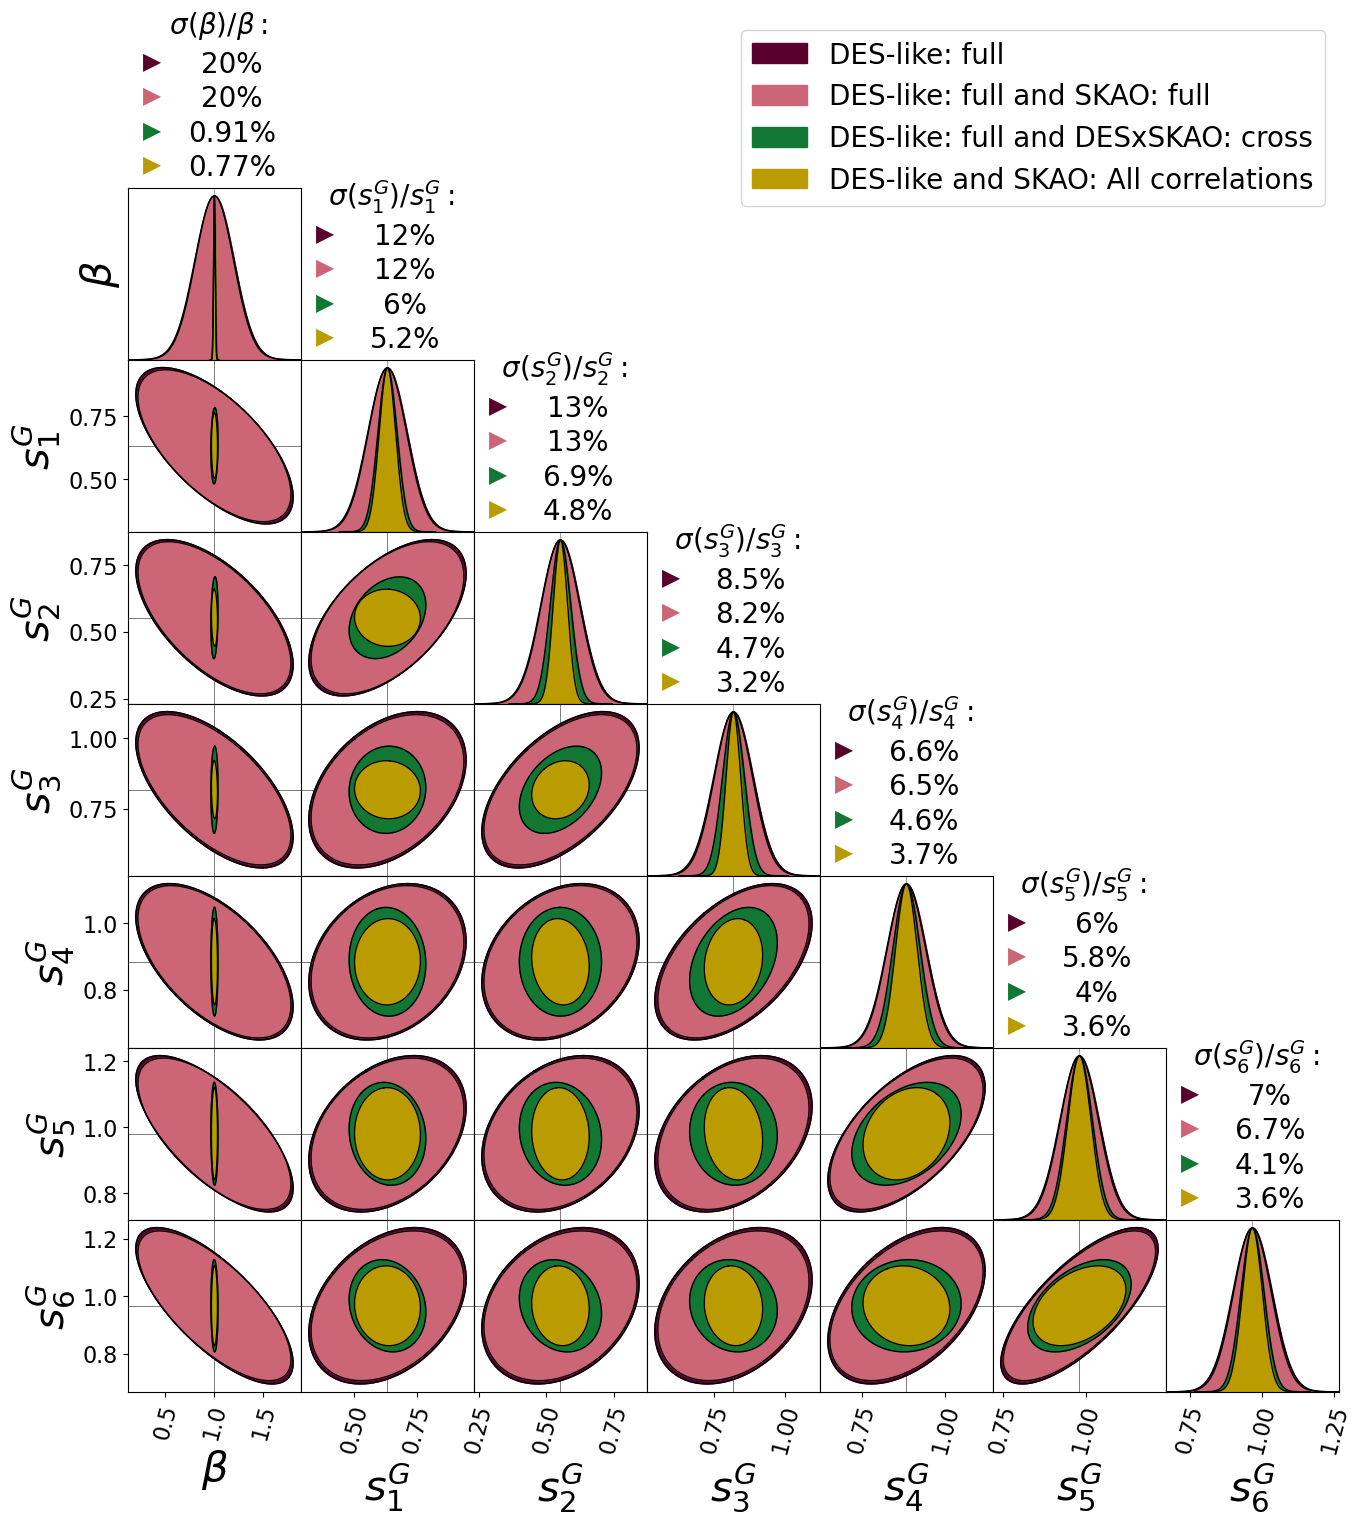

In [146]:
########################## Corner plots ###################################################################
fid=[]
counter = 1
for key in dic_Cosm_param.keys():
    # fid.append( dic_Cosm_param[key][1] )
    if counter >= 7:
        # ic(key)
        fid.append( dic_Cosm_param[key][1] )
    counter+=1
ic(fid)

par = [
    r"$\beta$",
    r"$s^G_1$",
    r"$s^G_2$",
    r"$s^G_3$",
    r"$s^G_4$",
    r"$s^G_5$",
    r"$s^G_6$",
    r"$s^G_7$",
    r"$s^G_8$",
    r"$s^G_9$",
    r"$s^G_{10}$",
    r"$s^G_{11}$",
    r"$s^G_{12}$",
    r"$s^G_{13}$",
    ]
par_titles = par

Plot_title = ("")



list_Gal_surv = [ 
                 "DES", 
                #  "LSST", 
                #  "Euclid"
                 ]

list_HI_surv  = [
                 "Meerkat",
                 "SKA", 
                 "SKA", 
                 "SKA", 
                 ]
if list_Gal_surv == ["DES"]:
    list_colors = [Galaxy_Colors[0],
                   Galaxy_Colors[1], 
                   Galaxy_Colors[4], 
                #    Galaxy_Colors[5],
                   HI_Colors[1]
                   ]


arr_alpha = np.array([
                      1.0, 
                      1.0, 
                      1.0,
                      1.0,
                      ])

Fishers = []
Flabels = []

count=0

for Name_Survey_Gal in list_Gal_surv:
    for Name_Survey_HI in list_HI_surv:
        
        if count == 0 and Name_Survey_HI=="Meerkat":
            Flabels.append( f"{Name_Survey_Gal}-like: full" )
            save_filename_i = f"{Name_Survey_Gal}_{N_bins_Gal}zbins_{Name_Survey_HI}_{0}zbins_{set_name}"
            FIM_Cl_i = np.loadtxt(open(F"{folder_name}FisherM_Cl_full_{save_filename_i}.csv", "rb"), delimiter=" ", skiprows=0)

        elif count == 1:
            Flabels.append( f"{Name_Survey_Gal}-like: full and SKAO: full" )
            save_filename_i = f"{Name_Survey_Gal}_{N_bins_Gal}zbins_{Name_Survey_HI}_{N_bins_HI}zbins_{set_name}"
            FIM_Cl_i = np.loadtxt(open(F"{folder_name}FisherM_Cl_G_f_HI_f_{save_filename_i}.csv", "rb"), delimiter=" ", skiprows=0)

        elif count == 2:
            Flabels.append( f"{Name_Survey_Gal}-like: full and DESxSKAO: cross" )
            save_filename_i = f"{Name_Survey_Gal}_{N_bins_Gal}zbins_{Name_Survey_HI}_{N_bins_HI}zbins_{set_name}"
            FIM_Cl_i = np.loadtxt(open(F"{folder_name}FisherM_Cl_G_f_GHI_c_{save_filename_i}.csv", "rb"), delimiter=" ", skiprows=0)
        
        elif count == 3:
            Flabels.append( f"{Name_Survey_Gal}-like and SKAO: All correlations" )
            save_filename_i = f"{Name_Survey_Gal}_{N_bins_Gal}zbins_{Name_Survey_HI}_{N_bins_HI}zbins_{set_name}"
            FIM_Cl_i = np.loadtxt(open(F"{folder_name}FisherM_Cl_full_{save_filename_i}.csv", "rb"), delimiter=" ", skiprows=0)

                
        # Only beta and s(z)
        Fishers.append( np.linalg.inv( np.linalg.inv(FIM_Cl_i)[6:,6:] ))

        ic(save_filename_i)
        count+=1



CornerPlot( Fishers, fid, par, par_titles, Plot_title, Flabels=Flabels, 
            cores=list_colors, 
            arr_alpha=arr_alpha, 
            # Fig_name= name_fig_corner+"_full.png", 
            Fig_name= "CornerP_DESxSKA_beta_sz_GHI_cross.pdf", 
            figure_size=(14,14), 
            # figure_size=(18,18), 
            # figure_size=(22,22), 
            xy_label_size=30, 
            legend_size=20, 
            sigma_title_size=20)

In [75]:

# # FIM_Cl_full = np.loadtxt(open(F"{folder_name}FisherM_Cl_full_{save_filename}.csv", "rb"), delimiter=" ", skiprows=0)
# # FIM_w_full  = np.loadtxt(open(F"{folder_name}FisherM_w_full_{ save_filename}.csv", "rb"), delimiter=" ", skiprows=0)


# ########################## Corner plots ###################################################################
# fid=[]
# counter = 1
# for key in dic_Cosm_param.keys():
#     # fid.append( dic_Cosm_param[key][1] )
#     if counter >= 7:
#         # ic(key)
#         fid.append( dic_Cosm_param[key][1] )
#     counter+=1
# ic(fid)

# par = [
#     r"$\beta$",
#     r"$s^G_1$",
#     r"$s^G_2$",
#     r"$s^G_3$",
#     r"$s^G_4$",
#     r"$s^G_5$",
#     r"$s^G_6$",
#     r"$s^G_7$",
#     r"$s^G_8$",
#     r"$s^G_9$",
#     r"$s^G_{10}$",
#     r"$s^G_{11}$",
#     r"$s^G_{12}$",
#     r"$s^G_{13}$",
#     ]
# par_titles = par

# # Plot_title = (r"Error ellipses: Multi-tracer technique")
# Plot_title = ("")

# # name_fig_corner = f"Figures/CornerP_{set_name}_{Survey_Gal}_{N_bins_Gal}zbins_{Survey_HI}_{N_bins_HI}zbins"

# Galaxy_Colors = [ 
#                 # "#882255",
#                 "#5A002D",
#                 "#CC6677",
#                 "#117733", "#44AA99",
#                 "#332288", "#88CCEE" 
#                 ]

# HI_Colors = ["#AA4499",
#             #   "#D6B71C", 
#             #   "#F3CA00", 
#             #   "#FFD400",
#             "#BB9C00"
#               ]


# # list_colors = [ HI_Colors[0], HI_Colors[1] ]
# # list_colors = [ Galaxy_Colors[4], Galaxy_Colors[5] ]

# # list_colors = [ Galaxy_Colors[2], HI_Colors[0], HI_Colors[1] ]
# # list_colors = [  Galaxy_Colors[0], Galaxy_Colors[2], Galaxy_Colors[4]  ]

# list_colors = ["dodgerblue", "darkorange"]


# # Importing Fihser Matrices values from  saved data


# list_Gal_surv = [ 
#                 #  "DES", 
#                  "Euclid"
#                 #  "LSST", 
#                  ]
# list_HI_surv  = [
#                 #  "Meerkat",
#                 #  "Meerkat", 
#                  "SKA"
#                  ]

# # dic_Fishers = {}
# Fishers = []
# Flabels = []

# count=1

# for Name_Survey_Gal in list_Gal_surv:
#     for Name_Survey_HI in list_HI_surv:
#         N_bins_Gal = 10
#         N_bins_HI  = 5
#         if count == 0:
#             N_bins_HI  = 0
#         if Name_Survey_HI == "SKA":
#             N_bins_HI  = 11


#         if Name_Survey_Gal == "DES":
#             N_bins_Gal = 6
#             save_filename_i = f"{Name_Survey_Gal}_{N_bins_Gal}zbins_{Name_Survey_HI}_{N_bins_HI}zbins_{set_name}"
#             FIM_Cl_full_i = np.loadtxt(open(F"{folder_name}FisherM_Cl_full_{save_filename_i}.csv", "rb"), delimiter=" ", skiprows=0)
#             Fishers.append( np.linalg.inv(np.linalg.inv(FIM_Cl_full_i) [6:13,6:13]))
#         elif Name_Survey_Gal == "Euclid":
#             N_bins_Gal = 13
#             save_filename_i = f"{Name_Survey_Gal}_{N_bins_Gal}zbins_{Name_Survey_HI}_{N_bins_HI}zbins_{set_name}"
#             FIM_Cl_full_i = np.loadtxt(open(F"{folder_name}FisherM_Cl_full_{save_filename_i}.csv", "rb"), delimiter=" ", skiprows=0)
#             FIM_w_full_i  = np.loadtxt(open(F"{folder_name}FisherM_w_full_{ save_filename_i}.csv", "rb"), delimiter=" ", skiprows=0)
            
#             # Only beta and s(z)
#             Fishers.append( np.linalg.inv( np.linalg.inv(FIM_Cl_full_i)[6:,6:] ))
#             Fishers.append( np.linalg.inv( np.linalg.inv(FIM_w_full_i)[6:,6:] ))

#         else:
#             save_filename_i = f"{Name_Survey_Gal}_{N_bins_Gal}zbins_{Name_Survey_HI}_{N_bins_HI}zbins_{set_name}"
#             FIM_Cl_full_i = np.loadtxt(open(F"{folder_name}FisherM_Cl_full_{save_filename_i}.csv", "rb"), delimiter=" ", skiprows=0)
            
#             # Only beta and s(z)
#             Fishers.append( np.linalg.inv( np.linalg.inv(FIM_Cl_full_i)[6:,6:] ))
            
#         if count == 0:
#             Flabels.append( f"{Name_Survey_Gal}" )
#         else:    
#             Flabels.append( fr"$C_\ell$ {Name_Survey_Gal} and {Name_Survey_HI}" )
#             Flabels.append( fr"$w(\theta)$ {Name_Survey_Gal} and {Name_Survey_HI}" )

#         count+=1

# CornerPlot( Fishers, fid, par, par_titles, Plot_title, Flabels=Flabels, 
#             cores=list_colors, 
#             # Fig_name= name_fig_corner+"_full.png", 
#             figure_size=(22,22), 
#             xy_label_size=30, 
#             legend_size=25, 
#             sigma_title_size=20)

## 7. Compare performance with **histograms**

ic| check_parameters: ['H0',
                       'w',
                       'Ob',
                       'Ocdm',
                       'As',
                       'ns',
                       'beta',
                       's_1',
                       's_2',
                       's_3',
                       's_4',
                       's_5',
                       's_6',
                       's_7',
                       's_8',
                       's_9',
                       's_10']


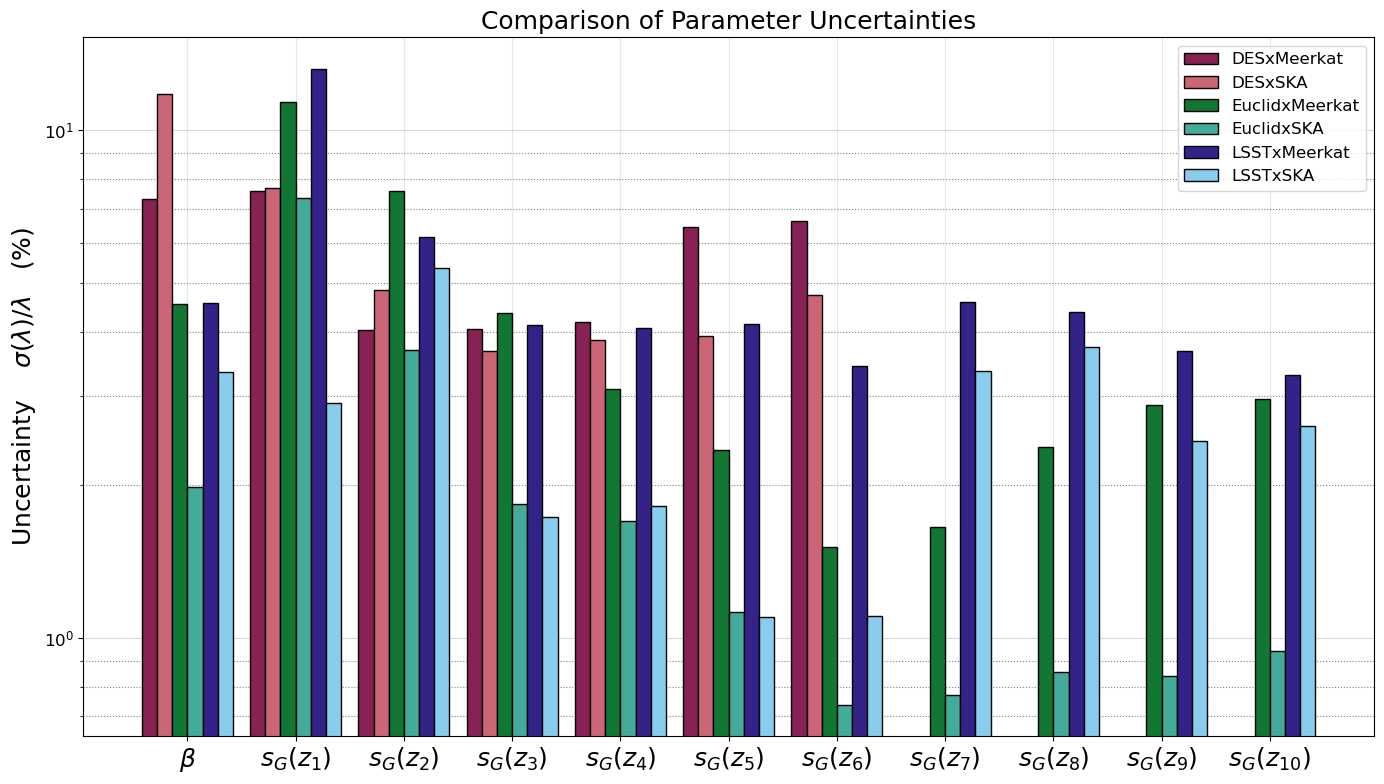

In [ ]:
# list_parameters = [
#     # r'$H_0$',
#     # r'$w$', 
#     # r"$\Omega_b$", 
#     # r"$\Omega_{cdm}$",
#     # r"$A_s 10^{9}$", 
#     # r"$n_s$",
#     r"$\beta$",
#     r"$s_G(z_1)$",
#     r"$s_G(z_2)$",
#     r"$s_G(z_3)$",
#     r"$s_G(z_4)$",
#     r"$s_G(z_5)$",
#     r"$s_G(z_6)$",
#     r"$s_G(z_7)$",
#     r"$s_G(z_8)$",
#     r"$s_G(z_9)$",
#     r"$s_G(z_{10})$",
#     ]

# parameters_vals = [ ]
# check_parameters = [ ]
# for key in dic_Cosm_param.keys():
#     parameters_vals.append( dic_Cosm_param[key][1] )
#     check_parameters.append( key )
# ic(check_parameters)

# skip_Cosm_param = 6


# # list_Gal_surv = ["Euclid", "DES"]
# list_Gal_surv = [ "DES", "Euclid", "LSST"]
# list_HI_surv  = ["Meerkat", "SKA"]
# # list_HI_surv  = [ "SKA"]


# dic_Result_Surveys = {}
# for Name_Survey_Gal in list_Gal_surv:
#     for Name_Survey_HI in list_HI_surv:

#         if Name_Survey_Gal == "DES":
#             save_filename_i = f"{Name_Survey_Gal}_6zbins_{Name_Survey_HI}_{N_bins_HI}zbins_{set_name}"
#             N_params = len(list_parameters) - 4
#         else:
#             save_filename_i = f"{Name_Survey_Gal}_{N_bins_Gal}zbins_{Name_Survey_HI}_{N_bins_HI}zbins_{set_name}"
#             N_params = len(list_parameters)

#         # Load your Fisher matrices
#         FIM_Cl_full_i = np.loadtxt(open(f"{folder_name}FisherM_Cl_full_{save_filename_i}.csv", "rb"), delimiter=" ", skiprows=0)
#         # Calculate parameter uncertainties (sqrt of diagonal of inverse FIM)
#         Inv_FIM_Cl_full_i = np.linalg.inv(FIM_Cl_full_i)
        
#         array_FIM_err_percent = np.zeros( len(list_parameters) )

#         for index_p in range(N_params):
#             inddex_skip_Cosm_p = index_p+skip_Cosm_param
#             array_FIM_err_percent[index_p] = np.sqrt( Inv_FIM_Cl_full_i [inddex_skip_Cosm_p,inddex_skip_Cosm_p] 
#                                                      ) / np.abs(parameters_vals[inddex_skip_Cosm_p]) * 100
        
#         dic_Result_Surveys[f"{Name_Survey_Gal}x{Name_Survey_HI}"] = array_FIM_err_percent

#         # ax.bar(x - width/2, dic_Result_Surveys[f"{Name_Survey_Gal}x{Name_Survey_HI}"], width, label=f'{Name_Survey_HI} x {Name_Survey_Gal}')

# list_keys= []
# for key in dic_Result_Surveys.keys():
#     list_keys.append(key)


# # Ploting 
# fig, ax = plt.subplots(figsize=(14, 8))

# # list_colors = [ "firebrick", "lightcoral", "forestgreen", "palegreen", "royalblue", "paleturquoise"]
# list_colors = [ 
#                 "#882255", "#CC6677",
#                 "#117733", "#44AA99",
#                 "#332288", "#88CCEE" 
#                 ]


# width=0.14
# # width = 0.35
# Label_loc = np.arange(len(list_parameters))
# counter = 0
# for key in list_keys:
#     offset = width * counter
#     rects = ax.bar(Label_loc + offset, dic_Result_Surveys[key], width, label=key, 
#                    color=list_colors[counter], 
#                    edgecolor="k")
#     counter += 1

# # ax.set_xlabel('Parameters')
# ax.set_ylabel(r'Uncertainty $\quad\sigma(\lambda) / \lambda \quad (\%)$', fontsize=18)
# ax.set_title('Comparison of Parameter Uncertainties', fontsize=18)
# # ax.set_xticks(x)
# ax.set_xticks(Label_loc + 2.5*width, list_parameters, rotation=0)
# ax.set_xticklabels(list_parameters, fontsize=18)
# ax.legend()
# ax.grid(True, alpha=0.3)
# ax.set_yscale("log")
# ax.set_axisbelow(True)
# ax.yaxis.grid(color='grey', linestyle='solid', which="major")
# ax.yaxis.grid(color='gray', linestyle="dotted", which="minor")

# plt.tight_layout()
# plt.show()

Single vs Multi-tracer

ic| N_bins_HI: 0, Set_Name: 'beta'
ic| N_bins_HI: 0, Set_Name: 'sz'
ic| N_bins_HI: 0, Set_Name: 'both'
ic| N_bins_HI: 5, Set_Name: 'beta'
ic| N_bins_HI: 5, Set_Name: 'sz'
ic| N_bins_HI: 5, Set_Name: 'both'


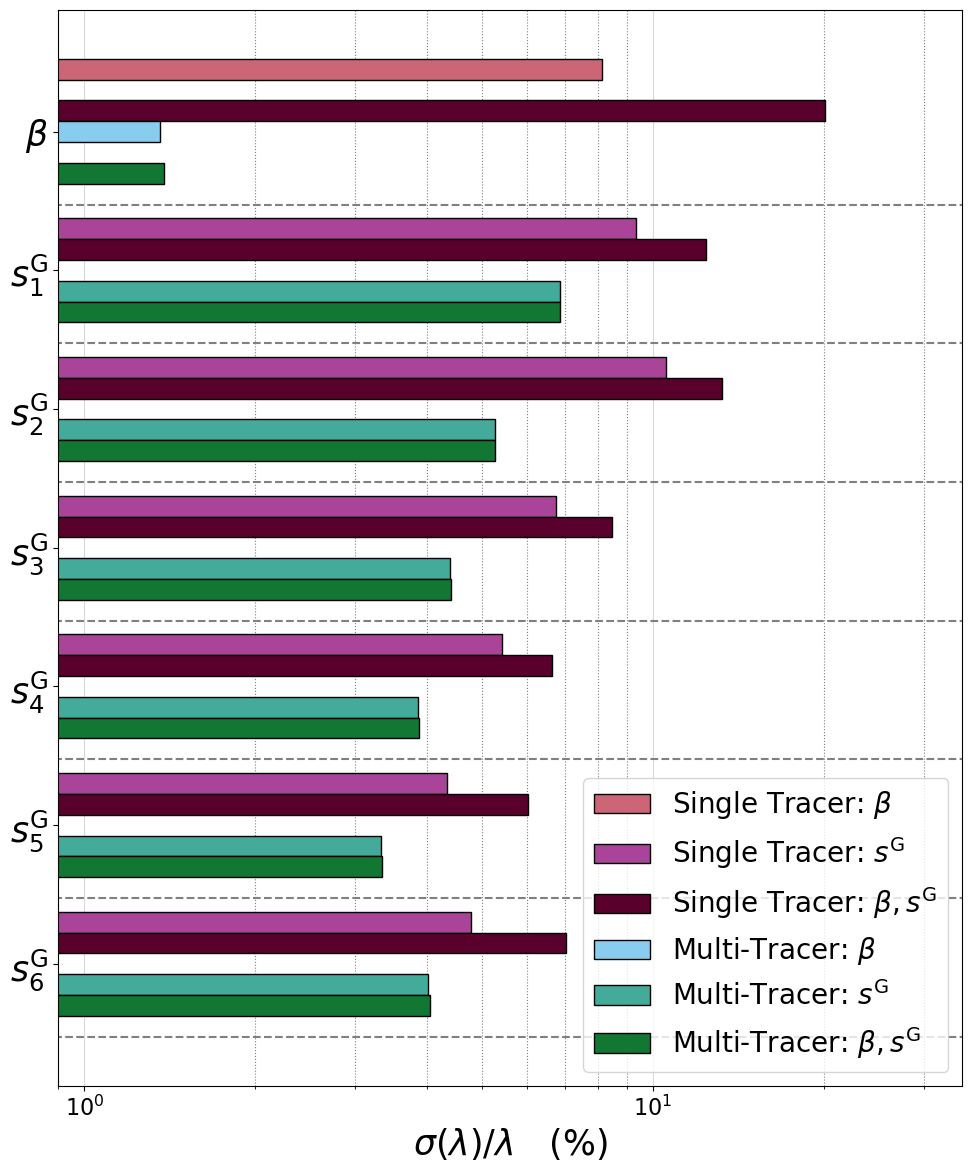

In [103]:
# -----------------------------------------------------------------------------
# Configuration (unchanged)
# -----------------------------------------------------------------------------
Name_Survey_Gal = "DES"
Name_Survey_HI  = "Meerkat"

N_bins_Gal_vis = 6
list_bins_HI = [0, 5]
list_set_name = [
                 "beta", 
                 "sz",
                 "both", 
                 ]
skip_Cosm_param = 6

# -----------------------------------------------------------------------------
# Plot preparation
# -----------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 12))          # slightly taller for horizontal bars

width = 0.15                                      # bar height (thickness) in horizontal mode
# Galaxy_Colors = [ 
#                 "#5A002D", "#CC6677",
#                 "#117733", "#44AA99",
#                 "#332288", "#88CCEE" 
#                 ]

# HI_Colors = ["#AA4499",
#              "#BB9C00"
#               ]

list_colors = [Galaxy_Colors[1], HI_Colors[0], Galaxy_Colors[0],
               Galaxy_Colors[5], Galaxy_Colors[3], Galaxy_Colors[2]]
counter = 0

# -----------------------------------------------------------------------------
# Loop over survey combinations (unchanged except plotting)
# -----------------------------------------------------------------------------
for N_bins_HI in list_bins_HI:
    for Set_Name in list_set_name:
        ic(N_bins_HI, Set_Name)

        # Load Fisher matrix
        save_filename_i = f"{Name_Survey_Gal}_{N_bins_Gal_vis}zbins_{Name_Survey_HI}_{N_bins_HI}zbins_{Set_Name}"
        FIM_Cl_full_i = np.loadtxt(open(f"{folder_name}FisherM_Cl_full_{save_filename_i}.csv", "rb"),
                                   delimiter=" ", skiprows=0)
        Inv_FIM_Cl_full_i = np.linalg.inv(FIM_Cl_full_i)

        # Build parameter dictionary (exactly as in original)
        dic_Cosm_param = {
            "H0"   : ['hubble_const' , 67.27           , 0.7       ],
            'w'    : ['w'            , -1              , 0.05      ],
            'Ob'   : ['omega_baryon' , 0.0492          , 10**-4    ],
            'Ocdm' : ['omega_cdm'    , 0.2647          , 10**-3    ],
            "As"   : ["curv_amp"     , 2.2065*10**-9   , 10**-11   ],
            "ns"   : ["spec_index"   , 0.9645          , 10**-2    ]
        }

        if Set_Name == "beta":
            N_params = 1
            dic_Cosm_param["beta"] = ['beta', 1, 10**-2]
            Set_Name_label = r"$\beta$"
        elif Set_Name == "sz":
            N_params = N_bins_Gal_vis
            for index_zc in range(len(arr_z_central)):
                if index_zc in dic_Gal_HI_id["Gal"]:
                    dic_Cosm_param[f"s_{index_zc+1}"] = ["mag_bias", dic_mag_bias[index_zc], dic_mag_bias[index_zc]*10**-2]
            Set_Name_label = r"$s^\mathrm{G}$"
        elif Set_Name == "both":
            N_params = 1 + N_bins_Gal_vis
            dic_Cosm_param["beta"] = ['beta', 1, 10**-2]
            for index_zc in range(len(arr_z_central)):
                if index_zc in dic_Gal_HI_id["Gal"]:
                    dic_Cosm_param[f"s_{index_zc+1}"] = ["mag_bias", dic_mag_bias[index_zc], dic_mag_bias[index_zc]*10**-2]
            Set_Name_label = r"$\beta, s^\mathrm{G}$"

        # Extract parameter values
        parameters_vals = []
        for key in dic_Cosm_param.keys():
            parameters_vals.append(dic_Cosm_param[key][1])

        # Compute uncertainties (percent)
        array_FIM_err_percent = np.zeros(N_params)
        for index_p in range(N_params):
            index_skip_Cosm_p = index_p + skip_Cosm_param
            array_FIM_err_percent[index_p] = np.sqrt(Inv_FIM_Cl_full_i[index_skip_Cosm_p, index_skip_Cosm_p]) \
                                             / np.abs(parameters_vals[index_skip_Cosm_p]) * 100


        if N_bins_HI == 0:
            Result_name = f"Single Tracer: {Set_Name_label}"
        else:
            Result_name = f"Multi-Tracer: {Set_Name_label}"

        # ---------------------------------------------------------------------
        # Horizontal bar plotting (transformed from vertical)
        # ---------------------------------------------------------------------
        offset = width * counter                     # vertical offset for this group
        if Set_Name == "sz":
            y_pos = np.arange(1, N_params + 1)       # parameter indices on y‑axis
        else:
            y_pos = np.arange(N_params)

        # barh: y positions, bar length (uncertainty), height (bar thickness)
        ax.barh(y_pos + offset, array_FIM_err_percent, height=width,
                label=Result_name, color=list_colors[counter], edgecolor="k")
        counter += 1

# -----------------------------------------------------------------------------
# Customize the plot (horizontal orientation)
# -----------------------------------------------------------------------------
list_parameters = [
    r"$\beta$",
    r"$s^\mathrm{G}_1$",
    r"$s^\mathrm{G}_2$",
    r"$s^\mathrm{G}_3$",
    r"$s^\mathrm{G}_4$",
    r"$s^\mathrm{G}_5$",
    r"$s^\mathrm{G}_6$",
]

# ax.set_title('Comparison of Parameter Uncertainties', fontsize=20)
ax.set_axisbelow(True)
ax.set_xscale("log")                                 # uncertainty on log scale
ax.set_xlim([9*10**-1, 3.5*10**1])

# Y‑ticks at the centre of each group of bars
y_tick_positions = np.arange(len(list_parameters)) + 3 * width
ax.set_yticks(y_tick_positions)
ax.set_yticklabels(list_parameters, fontsize=25)

# Horizontal separator lines between parameter groups
ax.hlines(np.arange(len(list_parameters)) + 6.5 * width, 0, 40,
          color="grey", ls="--")

ax.set_xlabel(r'$\sigma(\lambda) / \lambda \quad (\%)$', fontsize=25)
# ax.set_ylabel('')                                    # implicit from y‑tick labels

ax.grid(True, alpha=0.3, axis='x')                   # grid lines along x‑axis
ax.xaxis.grid(color='grey', linestyle='solid', which="major")
ax.xaxis.grid(color='gray', linestyle="dotted", which="minor")
ax.legend(fontsize=20, loc='lower right')
ax.invert_yaxis()
plt.tight_layout()
plt.savefig("Histogram_Compare_results_sz_beta_DES_MK_vertical.pdf")

plt.show()

#### Baseline

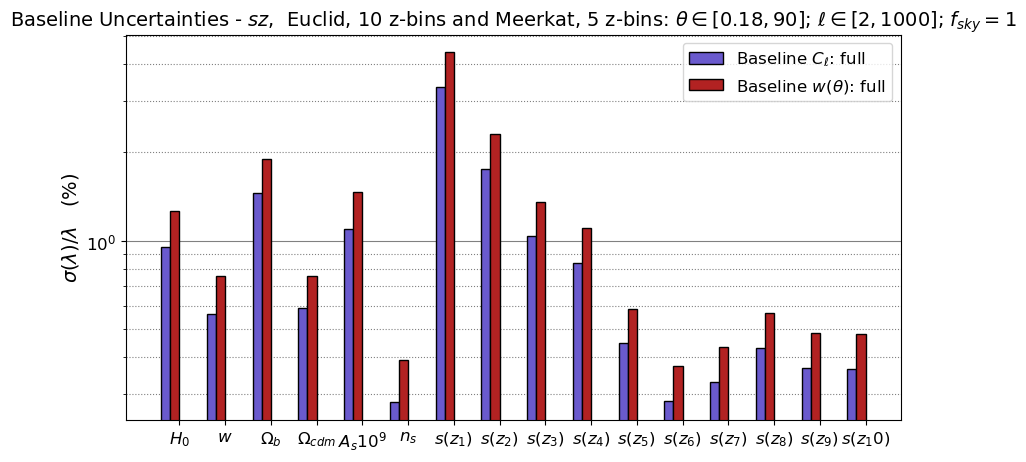

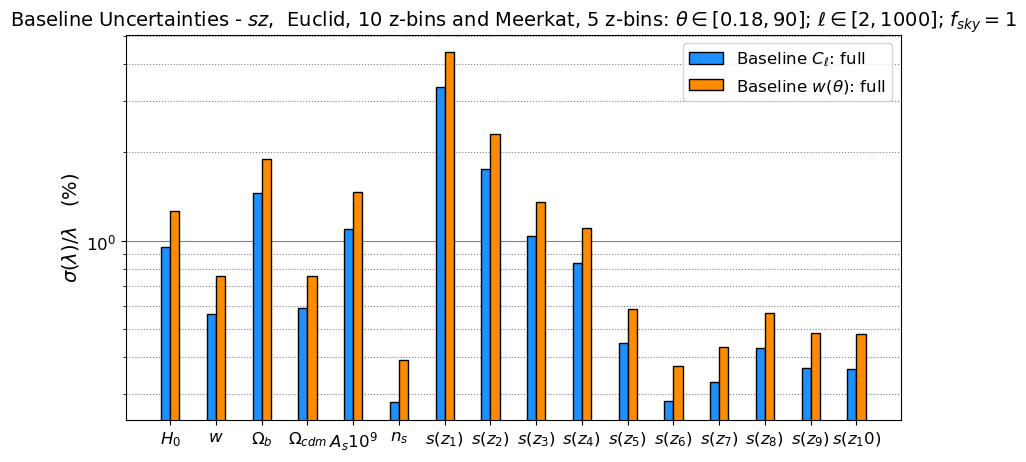

In [ ]:
# FIM_Cl_auto_Base = np.loadtxt(open(F"{folder_name}FisherM_Cl_auto_{save_filename}_f{10}_lmin{2}_thetaMax{90}.csv", "rb"), delimiter=" ", skiprows=0)
# FIM_w_auto_Base  = np.loadtxt(open(F"{folder_name}FisherM_w_auto_{ save_filename}_f{10}_lmin{2}_thetaMax{90}.csv", "rb"), delimiter=" ", skiprows=0)
FIM_Cl_full_Base = np.loadtxt(open(F"{folder_name}FisherM_Cl_full_{save_filename}_f{10}_lmin{2}_thetaMax{90}.csv", "rb"), delimiter=" ", skiprows=0)
FIM_w_full_Base  = np.loadtxt(open(F"{folder_name}FisherM_w_full_{ save_filename}_f{10}_lmin{2}_thetaMax{90}.csv", "rb"), delimiter=" ", skiprows=0)

# Inv_FIM_Cl_auto_Base = np.linalg.inv( FIM_Cl_auto_Base)
# Inv_FIM_w_auto_Base  = np.linalg.inv( FIM_w_auto_Base )    
Inv_FIM_Cl_full_Base = np.linalg.inv( FIM_Cl_full_Base)  
Inv_FIM_w_full_Base  = np.linalg.inv( FIM_w_full_Base )  

Title_plot = rf"Baseline Uncertainties - ${set_name}$,  {Survey_Gal}, {N_bins_Gal} z-bins and {Survey_HI}, {N_bins_HI} z-bins: $\theta \in [{0.18}, {90}]$; $\ell \in [{2}, {1000}]$; " + r"$f_{sky} = 1$"  
name_fig_hist_base = f"Figures/Hist_{set_name}_{Survey_Gal}_{N_bins_Gal}zbins_{Survey_HI}_{N_bins_HI}zbins_theta_018_90-ell_2_1000-f_sky_10"

list_parameters = [
    r'$H_0$',
    r'$w$', 
    r"$\Omega_b$", 
    r"$\Omega_{cdm}$",
    r"$A_s 10^{9}$", 
    r"$n_s$",
    # r"$\beta$",
    r"$s(z_1)$",
    r"$s(z_2)$",
    r"$s(z_3)$",
    r"$s(z_4)$",
    r"$s(z_5)$",
    r"$s(z_6)$",
    r"$s(z_7)$",
    r"$s(z_8)$",
    r"$s(z_9)$",
    r"$s(z_10)$",
    ]

parameters_vals = [ ]
check_parameters = [ ]
for key in dic_Cosm_param.keys():
    parameters_vals.append( dic_Cosm_param[key][1] )
    check_parameters.append( key )

array_Cl_auto_Base = np.zeros( len(list_parameters) )
array_w_auto_Base  = np.zeros( len(list_parameters) )
array_Cl_full_Base = np.zeros( len(list_parameters) )
array_w_full_Base  = np.zeros( len(list_parameters) )
for index_p, p in enumerate(parameters_vals):
    # array_Cl_auto_Base[index_p] = np.sqrt( Inv_FIM_Cl_auto_Base [index_p,index_p] ) / np.abs(p) * 100   # Divide by value and multiply by 100 to get the uncertainty in percentage
    # array_w_auto_Base[index_p]  = np.sqrt( Inv_FIM_w_auto_Base [index_p,index_p] )  / np.abs(p) * 100
    array_Cl_full_Base[index_p] = np.sqrt( Inv_FIM_Cl_full_Base [index_p,index_p] ) / np.abs(p) * 100
    array_w_full_Base[index_p]  = np.sqrt( Inv_FIM_w_full_Base [index_p,index_p] )  / np.abs(p) * 100

Est_Result_dic_Base = { }
# Est_Result_dic_Base[r"Baseline $C_\ell$: auto"]    = array_Cl_auto_Base
# Est_Result_dic_Base[r"Baseline $w(\theta)$: auto"]= array_w_auto_Base
Est_Result_dic_Base[r"Baseline $C_\ell$: full"]    = array_Cl_full_Base
Est_Result_dic_Base[r"Baseline $w(\theta)$: full"] = array_w_full_Base

list_Base_keys= []
for key in Est_Result_dic_Base.keys():
    list_Base_keys.append(key)

# Ploting 
fig, ax = plt.subplots(figsize=(10,5))

list_colors = ["slateblue", "firebrick", "dodgerblue", "darkorange"]

width=0.2
Label_loc = np.arange(len(list_parameters))
counter = 0
for key in list_Base_keys:
    offset = width * counter
    rects = ax.bar(Label_loc + offset, Est_Result_dic_Base[key], width, label=key, color=list_colors[counter], edgecolor="k")
    counter += 1

ax.set_ylabel(r'$\sigma(\lambda) / \lambda \quad (\%)$')
ax.set_title( f'{Title_plot}', fontsize=14)
ax.set_xticks(Label_loc + 1.5*width, list_parameters, rotation=0)
ax.set_yscale("log")
ax.set_axisbelow(True)
ax.yaxis.grid(color='grey', linestyle='solid', which="major")
ax.yaxis.grid(color='gray', linestyle="dotted", which="minor")
plt.legend()
plt.savefig(name_fig_hist_base+".png")
plt.show()


########################## Plotting only Full correlations ##############################

Est_Result_dic_Base_full = { }
Est_Result_dic_Base_full[r"Baseline $C_\ell$: full"]    = array_Cl_full_Base
Est_Result_dic_Base_full[r"Baseline $w(\theta)$: full"] = array_w_full_Base

list_Base_keys_full= []
for key in Est_Result_dic_Base_full.keys():
    list_Base_keys_full.append(key)

fig, ax = plt.subplots(figsize=(10,5))

list_colors_full = ["dodgerblue", "darkorange" ]
counter = 0
for key in list_Base_keys_full:
    offset = width * counter
    rects = ax.bar(Label_loc + offset, Est_Result_dic_Base_full[key], width, 
                   label=key, color=list_colors_full[counter], edgecolor="k")
    counter += 1

ax.set_ylabel(r'$\sigma(\lambda) / \lambda \quad (\%)$')
ax.set_title( f'{Title_plot}', fontsize=14)
ax.set_xticks(Label_loc + 0.5*width, list_parameters, rotation=0)
ax.set_yscale("log")
ax.set_axisbelow(True)
ax.yaxis.grid(color='grey', linestyle='solid', which="major")
ax.yaxis.grid(color='gray', linestyle="dotted", which="minor")
plt.legend()
plt.savefig(name_fig_hist_base+"_full.png")
plt.show()

#### Parameters to compare Baseline with

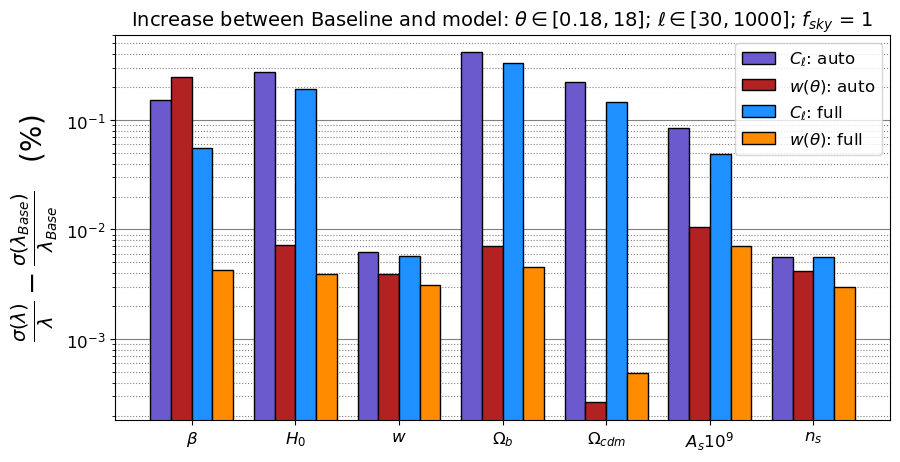

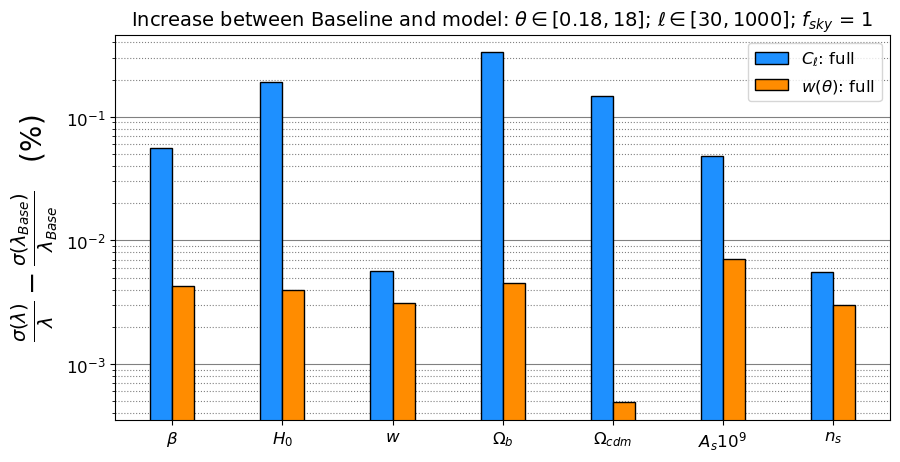

In [ ]:
# f_sky, f_sky_str = 1.0, "10"
# f_sky, f_sky_str = 0.33, "033"

# theta_max = 18

# l_min     = 10
# l_min     = 30


FIM_Cl_auto = np.loadtxt(open(F"{folder_name}FisherM_Cl_auto_{save_filename}_f{f_sky_str}_lmin{l_min}_thetaMax{theta_max}.csv", "rb"), delimiter=" ", skiprows=0)
FIM_w_auto  = np.loadtxt(open(F"{folder_name}FisherM_w_auto_{ save_filename}_f{f_sky_str}_lmin{l_min}_thetaMax{theta_max}.csv", "rb"), delimiter=" ", skiprows=0)
FIM_Cl_full = np.loadtxt(open(F"{folder_name}FisherM_Cl_full_{save_filename}_f{f_sky_str}_lmin{l_min}_thetaMax{theta_max}.csv", "rb"), delimiter=" ", skiprows=0)
FIM_w_full  = np.loadtxt(open(F"{folder_name}FisherM_w_full_{ save_filename}_f{f_sky_str}_lmin{l_min}_thetaMax{theta_max}.csv", "rb"), delimiter=" ", skiprows=0)

Inv_FIM_Cl_auto = np.linalg.inv( FIM_Cl_auto )
Inv_FIM_w_auto  = np.linalg.inv( FIM_w_auto  )    
Inv_FIM_Cl_full = np.linalg.inv( FIM_Cl_full)  
Inv_FIM_w_full  = np.linalg.inv( FIM_w_full )  


Title_plot = rf"Increase between Baseline and model: $\theta \in [{theta_min}, {theta_max:.3g}]$; $\ell \in [{l_min}, {l_max}]$; " + r"$f_{sky}$ = " + rf"{f_sky:.3g}"  

name_fig_hist = f"Figures/Hist_{set_name}_{Survey}_{N_bins}z-bins_theta_{theta_min_str}_{theta_max:.3g}-ell_{l_min}_{l_max}-f_sky_{f_sky_str}"


list_parameters = [
    # r"$s(z_1)$",
    # r"$s(z_2)$",
    # r"$s(z_3)$",
    # r"$s(z_4)$",
    r"$\beta$",
    r'$H_0$',
    r'$w$', 
    r"$\Omega_b$", 
    r"$\Omega_{cdm}$",
    r"$A_s 10^{9}$", 
    r"$n_s$"
    ]

parameters_vals = [ ]
check_parameters = [ ]
for key in dic_Cosm_param.keys():
    parameters_vals.append( dic_Cosm_param[key][1] )
    check_parameters.append( key )


array_Cl_auto = np.zeros( len(list_parameters) )
array_w_auto  = np.zeros( len(list_parameters) )
array_Cl_full = np.zeros( len(list_parameters) )
array_w_full  = np.zeros( len(list_parameters) )
for index_p, p in enumerate(parameters_vals):
    array_Cl_auto[index_p] = np.sqrt( Inv_FIM_Cl_auto [index_p,index_p] ) / np.abs(p) * 100   # Divide by value and multiply by 100 to get the uncertainty in percentage
    array_w_auto[index_p]  = np.sqrt( Inv_FIM_w_auto [index_p,index_p] )  / np.abs(p) * 100
    array_Cl_full[index_p] = np.sqrt( Inv_FIM_Cl_full [index_p,index_p] ) / np.abs(p) * 100
    array_w_full[index_p]  = np.sqrt( Inv_FIM_w_full [index_p,index_p] )  / np.abs(p) * 100

Est_Result_dic = { }
Est_Result_dic[r"$C_\ell$: auto"]    = array_Cl_auto
Est_Result_dic[r"$w(\theta)$: auto"] = array_w_auto
Est_Result_dic[r"$C_\ell$: full"]    = array_Cl_full
Est_Result_dic[r"$w(\theta)$: full"] = array_w_full

# Ploting 
fig, ax = plt.subplots(figsize=(10,5))

width=0.2
Label_loc = np.arange(len(list_parameters))
counter = 0
for index_key, key in enumerate(Est_Result_dic.keys()):
    offset = width * counter
    rects = ax.bar(Label_loc + offset, Est_Result_dic[key]-Est_Result_dic_Base[list_Base_keys[index_key]], width, 
                   label=key, color=list_colors[counter], edgecolor="k")
    counter += 1

ax.set_ylabel(r'$\frac{\sigma(\lambda)}{\lambda} - \frac{\sigma(\lambda_{Base})}{\lambda_{Base}}  \quad (\%)$', fontsize=20)
ax.set_title( f'{Title_plot}', fontsize=14)
ax.set_xticks(Label_loc + 1.5*width, list_parameters, rotation=0)
ax.set_yscale("log")
ax.set_axisbelow(True)
ax.yaxis.grid(color='grey', linestyle='solid', which="major")
ax.yaxis.grid(color='gray', linestyle="dotted", which="minor")
plt.legend()
plt.savefig(name_fig_hist+".png")
plt.show()



########################## Plotting only Full correlations ##############################

Est_Result_dic_full = { }
Est_Result_dic_full[r"$C_\ell$: full"]    = array_Cl_full
Est_Result_dic_full[r"$w(\theta)$: full"] = array_w_full


fig, ax = plt.subplots(figsize=(10,5))

list_colors_full = ["dodgerblue", "darkorange" ]
counter = 0
for index_key, key in enumerate(Est_Result_dic_full.keys()):
    offset = width * counter
    rects = ax.bar(Label_loc + offset, Est_Result_dic_full[key]-Est_Result_dic_Base_full[list_Base_keys_full[index_key]], width, 
                   label=key, color=list_colors_full[counter], edgecolor="k")
    counter += 1

ax.set_ylabel(r'$\frac{\sigma(\lambda)}{\lambda} - \frac{\sigma(\lambda_{Base})}{\lambda_{Base}}  \quad (\%)$', fontsize=20)
ax.set_title( f'{Title_plot}', fontsize=14)
ax.set_xticks(Label_loc + 0.5*width, list_parameters, rotation=0)
ax.set_yscale("log")
ax.set_axisbelow(True)
ax.yaxis.grid(color='grey', linestyle='solid', which="major")
ax.yaxis.grid(color='gray', linestyle="dotted", which="minor")
plt.legend()
plt.savefig(name_fig_hist+"_full.png")
plt.show()